In [1]:
# E-Commerce Intelligence Platform
# First Python EDA Notebook

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

print("\nAll libraries imported successfully!")

Pandas version: 3.1.1
NumPy version: 2.5.4

All libraries imported successfully!


In [2]:
import pandas as pd
import psycopg
from sqlalchemy import create_engine, text
from getpass import getpass

# PostgreSQL connection details
DB_HOST = "localhost"
DB_PORT = "5432"
DB_NAME = "ecommerce_analytics"
DB_USER = "postgres"

# Securely enter database password
DB_PASSWORD = getpass("Enter PostgreSQL password: ")

# Create database connection
connection_url = (
    f"postgresql+psycopg://{DB_USER}:{DB_PASSWORD}"
    f"@{DB_HOST}:{DB_PORT}/{DB_NAME}"
)

engine = create_engine(connection_url)

# Test connection
with engine.connect() as connection:
    result = connection.execute(
        text("SELECT current_database(), current_user")
    )
    print("Database connection successful!")
    print("Database and user:", result.fetchone())


Enter PostgreSQL password:  ········


Database connection successful!
Database and user: ('ecommerce_analytics', 'postgres')


In [6]:

# Load Executive KPIs from PostgreSQL

query = """
SELECT *
FROM analytics.executive_kpis;
"""

kpi_df = pd.read_sql(query, engine)

print("Data loaded successfully!")
print("Dataset shape:", kpi_df.shape)

display(kpi_df.T)


Data loaded successfully!
Dataset shape: (1, 15)


,0
total_orders,99441.00
delivered_orders,96478.00
canceled_orders,625.00
total_product_revenue,13591643.70
delivered_product_revenue,13221498.11
total_freight,2251909.54
average_order_value,159.33
total_customers,93358.00
total_products,32951.00
total_sellers,3095.00


In [7]:

# Check available views in analytics schema

check_query = """
SELECT
    table_schema,
    table_name,
    table_type
FROM information_schema.tables
WHERE table_schema = 'analytics'
ORDER BY table_name;
"""

available_views = pd.read_sql(check_query, engine)

display(available_views)

print("Total analytics objects:", len(available_views))


,table_schema,table_name,table_type
0,analytics,category_performance,VIEW
1,analytics,category_product_performance,VIEW
2,analytics,customer_retention,VIEW
3,analytics,customer_rfm,VIEW
4,analytics,customer_rfm_final,BASE TABLE
5,analytics,customer_rfm_scores,VIEW
6,analytics,customer_segments,VIEW
7,analytics,delivery_performance,VIEW
8,analytics,executive_kpis,VIEW
9,analytics,monthly_sales,VIEW


Total analytics objects: 17


In [8]:

# ==========================================
# EXECUTIVE KPI ANALYSIS
# ==========================================

total_orders = kpi_df.loc[0, "total_orders"]
delivered_orders = kpi_df.loc[0, "delivered_orders"]
canceled_orders = kpi_df.loc[0, "canceled_orders"]

# Calculate delivery and cancellation rates
delivery_rate = (delivered_orders / total_orders) * 100
cancellation_rate = (canceled_orders / total_orders) * 100

# Revenue metrics
total_revenue = kpi_df.loc[0, "total_product_revenue"]
delivered_revenue = kpi_df.loc[0, "delivered_product_revenue"]

# Display business insights
print("========== BUSINESS KPI ANALYSIS ==========")

print(f"Delivery Rate: {delivery_rate:.2f}%")
print(f"Cancellation Rate: {cancellation_rate:.2f}%")

print(f"Total Product Revenue: R$ {total_revenue:,.2f}")
print(f"Delivered Product Revenue: R$ {delivered_revenue:,.2f}")

print(f"Average Order Value: R$ {kpi_df.loc[0, 'average_order_value']:.2f}")

print(f"Average Review Score: {kpi_df.loc[0, 'average_review_score']}/5")

print("===========================================")


========== BUSINESS KPI ANALYSIS ==========
Delivery Rate: 97.02%
Cancellation Rate: 0.63%
Total Product Revenue: R$ 13,591,643.70
Delivered Product Revenue: R$ 13,221,498.11
Average Order Value: R$ 159.33
Average Review Score: 4.09/5


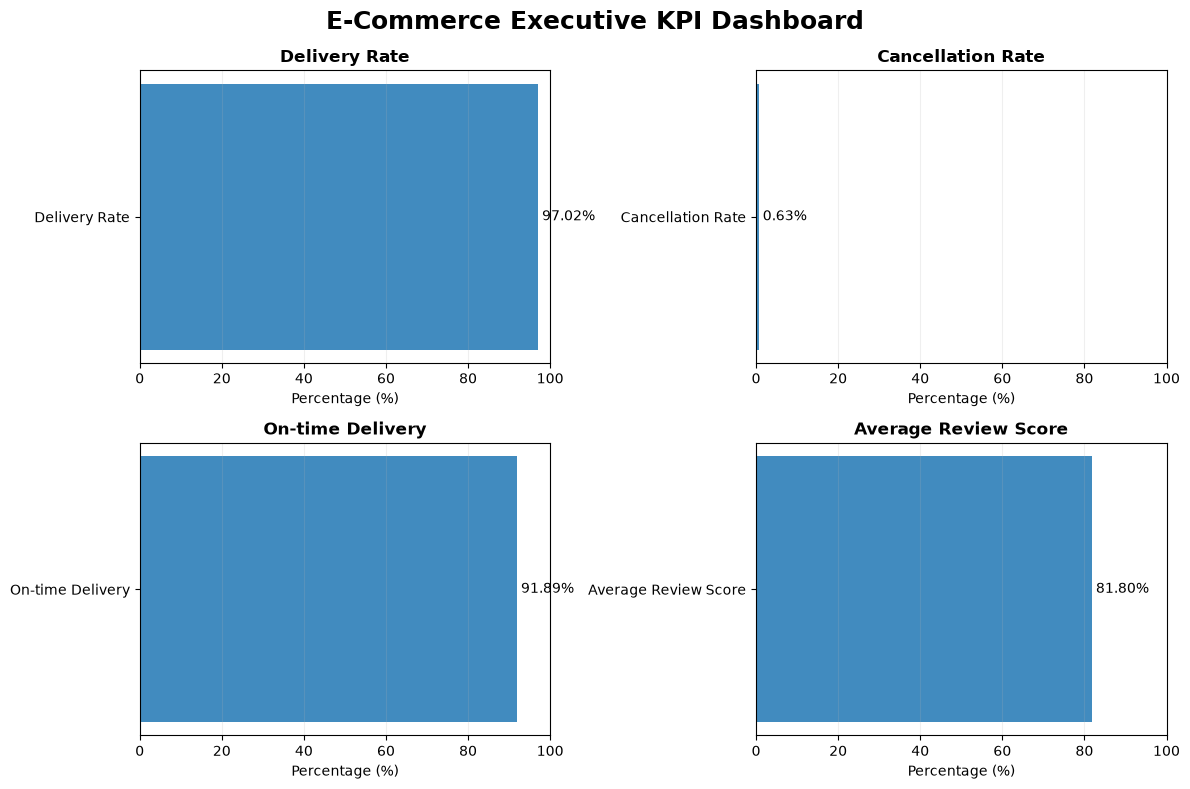

In [9]:

import matplotlib.pyplot as plt
import numpy as np

# KPI values
metrics = {
    "Delivery Rate": delivery_rate,
    "Cancellation Rate": cancellation_rate,
    "On-time Delivery": kpi_df.loc[0, "on_time_delivery_percentage"],
    "Average Review Score": (
        kpi_df.loc[0, "average_review_score"] / 5 * 100
    )
}

# Create dashboard
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

fig.suptitle(
    "E-Commerce Executive KPI Dashboard",
    fontsize=18,
    fontweight="bold"
)

for ax, (name, value) in zip(axes.flat, metrics.items()):
    ax.barh([name], [value], alpha=0.85)
    ax.set_xlim(0, 100)
    ax.set_xlabel("Percentage (%)")
    ax.set_title(name, fontweight="bold")
    ax.text(
        value + 1,
        0,
        f"{value:.2f}%",
        va="center"
    )
    ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()


In [10]:

# Load monthly sales data from PostgreSQL

monthly_query = """
SELECT *
FROM analytics.monthly_sales
ORDER BY sales_month;
"""

monthly_df = pd.read_sql(
    monthly_query,
    engine,
    parse_dates=["sales_month"]
)

print("Monthly sales data loaded successfully!")
print("Dataset shape:", monthly_df.shape)

display(monthly_df.head(10))


Monthly sales data loaded successfully!
Dataset shape: (25, 7)


,sales_month,total_orders,delivered_orders,canceled_orders,total_product_revenue,total_freight,average_order_value
0,2016-09-01,4,1,2,267.36,87.39,88.69
1,2016-10-01,324,265,24,49507.66,7301.18,175.34
2,2016-12-01,1,1,0,10.90,8.72,19.62
3,2017-01-01,800,750,3,120312.87,16875.62,171.49
4,2017-02-01,1780,1653,17,247303.02,38977.60,160.83
5,2017-03-01,2682,2546,33,374344.30,57704.29,161.09
6,2017-04-01,2404,2303,18,359927.23,52495.01,171.56
7,2017-05-01,3700,3546,29,506071.14,80119.81,158.43
8,2017-06-01,3245,3135,16,433038.60,69924.44,155.00
9,2017-07-01,4026,3872,28,498031.48,86940.14,145.30


In [11]:

print("DATASET INFORMATION")
monthly_df.info()

print("\nMISSING VALUES")
display(monthly_df.isnull().sum())

print("\nSTATISTICAL SUMMARY")
display(monthly_df.describe().T)


DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype        
---  ------                 --------------  -----        
 0   sales_month            25 non-null     datetime64[s]
 1   total_orders           25 non-null     int64        
 2   delivered_orders       25 non-null     int64        
 3   canceled_orders        25 non-null     int64        
 4   total_product_revenue  25 non-null     float64      
 5   total_freight          25 non-null     float64      
 6   average_order_value    25 non-null     float64      
dtypes: datetime64[s](1), float64(3), int64(3)
memory usage: 1.5 KB

MISSING VALUES


sales_month              0
total_orders             0
delivered_orders         0
canceled_orders          0
total_product_revenue    0
total_freight            0
average_order_value      0
dtype: int64


STATISTICAL SUMMARY


,count,mean,min,25%,50%,75%,max,std
sales_month,25,2017-09-28 12:28:48,2016-09-01 00:00:00,2017-04-01 00:00:00,2017-10-01 00:00:00,2018-04-01 00:00:00,2018-10-01 00:00:00,NaN
total_orders,25.0,3977.64,1.0,1780.0,4285.0,6512.0,7544.0,2699.938516
delivered_orders,25.0,3859.12,0.0,1653.0,4150.0,6351.0,7289.0,2644.281666
canceled_orders,25.0,25.0,0.0,15.0,24.0,29.0,84.0,19.478621
total_product_revenue,25.0,543665.748,0.0,247303.02,573971.68,865124.31,1010271.37,367072.096319
total_freight,25.0,90076.3816,0.0,38977.6,94232.92,153264.14,171913.38,62657.872281
average_order_value,25.0,139.8636,0.0,152.22,158.43,167.13,175.34,51.667701


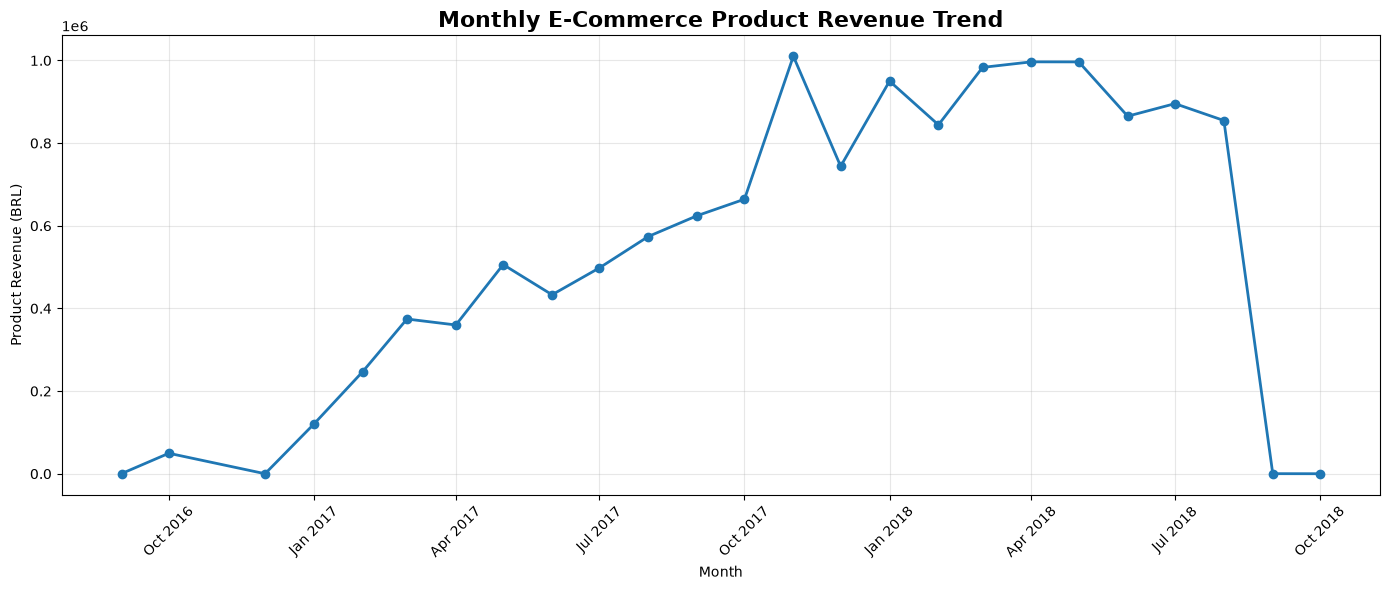

HIGHEST REVENUE MONTH
sales_month              2017-11-01 00:00:00
total_product_revenue             1010271.37
Name: 13, dtype: object

LOWEST REVENUE MONTH
sales_month              2018-10-01 00:00:00
total_product_revenue                    0.0
Name: 24, dtype: object


In [12]:

# ==========================================
# MONTHLY REVENUE TREND ANALYSIS
# ==========================================

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Sort data by month
monthly_df = monthly_df.sort_values("sales_month")

# Find highest and lowest revenue months
highest_month = monthly_df.loc[
    monthly_df["total_product_revenue"].idxmax()
]

lowest_month = monthly_df.loc[
    monthly_df["total_product_revenue"].idxmin()
]

# Create revenue trend chart
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_df["sales_month"],
    monthly_df["total_product_revenue"],
    marker="o",
    linewidth=2
)

plt.title(
    "Monthly E-Commerce Product Revenue Trend",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Product Revenue (BRL)")

plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("HIGHEST REVENUE MONTH")
print(highest_month[["sales_month", "total_product_revenue"]])

print("\nLOWEST REVENUE MONTH")
print(lowest_month[["sales_month", "total_product_revenue"]])


In [13]:

# Top 5 revenue-generating months
top_5_months = monthly_df.nlargest(
    5, "total_product_revenue"
)[[
    "sales_month",
    "total_orders",
    "delivered_orders",
    "total_product_revenue"
]]

print("TOP 5 REVENUE MONTHS")
display(top_5_months)

# Check months with zero revenue
zero_revenue_months = monthly_df[
    monthly_df["total_product_revenue"].fillna(0) == 0
][[
    "sales_month",
    "total_orders",
    "delivered_orders",
    "canceled_orders",
    "total_product_revenue"
]]

print("ZERO REVENUE MONTHS")
display(zero_revenue_months)


TOP 5 REVENUE MONTHS


,sales_month,total_orders,delivered_orders,total_product_revenue
13,2017-11-01,7544,7289,1010271.37
18,2018-04-01,6939,6798,996647.75
19,2018-05-01,6873,6749,996517.68
17,2018-03-01,7211,7003,983213.44
15,2018-01-01,7269,7069,950030.36


ZERO REVENUE MONTHS


,sales_month,total_orders,delivered_orders,canceled_orders,total_product_revenue
24,2018-10-01,4,0,4,0.0


In [14]:

# ==========================================
# MONTH-OVER-MONTH REVENUE GROWTH
# ==========================================

monthly_growth_df = monthly_df.copy()

monthly_growth_df["revenue_change"] = (
    monthly_growth_df["total_product_revenue"].diff()
)

monthly_growth_df["revenue_growth_pct"] = (
    monthly_growth_df["total_product_revenue"].pct_change() * 100
)

monthly_growth_df.replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)

print("MONTHLY REVENUE GROWTH ANALYSIS")

display(
    monthly_growth_df[
        [
            "sales_month",
            "total_product_revenue",
            "revenue_change",
            "revenue_growth_pct"
        ]
    ].round(2)
)


MONTHLY REVENUE GROWTH ANALYSIS


/var/folders/y9/wrynjjb10td2_6pm041jbm2w0000gn/T/ipykernel_1392/1744896109.py:31: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,sales_month,total_product_revenue,revenue_change,revenue_growth_pct
0,2016-09-01,267.36,NaN,NaN
1,2016-10-01,49507.66,49240.30,18417.23
2,2016-12-01,10.90,-49496.76,-99.98
3,2017-01-01,120312.87,120301.97,1103687.80
4,2017-02-01,247303.02,126990.15,105.55
5,2017-03-01,374344.30,127041.28,51.37
6,2017-04-01,359927.23,-14417.07,-3.85
7,2017-05-01,506071.14,146143.91,40.60
8,2017-06-01,433038.60,-73032.54,-14.43
9,2017-07-01,498031.48,64992.88,15.01


In [15]:

# Inspect product performance view columns

product_columns_query = """
SELECT
    column_name,
    data_type
FROM information_schema.columns
WHERE table_schema = 'analytics'
  AND table_name = 'product_performance'
ORDER BY ordinal_position;
"""

product_columns = pd.read_sql(
    product_columns_query,
    engine
)

display(product_columns)


,column_name,data_type
0,product_id,text
1,product_category,character varying
2,total_items_sold,bigint
3,total_orders,bigint
4,total_sellers,bigint
5,product_revenue,numeric
6,total_freight,numeric
7,average_selling_price,numeric
8,minimum_selling_price,numeric
9,maximum_selling_price,numeric


In [16]:

# ==========================================
# PRODUCT PERFORMANCE ANALYSIS
# ==========================================

product_query = """
SELECT *
FROM analytics.product_performance;
"""

product_df = pd.read_sql(product_query, engine)

print("Product data loaded successfully!")
print("Dataset shape:", product_df.shape)

display(product_df.head(10))


Product data loaded successfully!
Dataset shape: (32951, 10)


,product_id,product_category,total_items_sold,total_orders,total_sellers,product_revenue,total_freight,average_selling_price,minimum_selling_price,maximum_selling_price
0,00066f42aeeb9f3007548bb9d3f33c38,perfumery,1,1,1,101.65,18.59,101.65,101.65,101.65
1,00088930e925c41fd95ebfe695fd2655,auto,1,1,1,129.90,13.93,129.90,129.90,129.90
2,0009406fd7479715e4bef61dd91f2462,bed_bath_table,1,1,1,229.00,13.10,229.00,229.00,229.00
3,000b8f95fcb9e0096488278317764d19,housewares,2,2,1,117.80,39.20,58.90,58.90,58.90
4,000d9be29b5207b54e86aa1b1ac54872,watches_gifts,1,1,1,199.00,19.27,199.00,199.00,199.00
5,0011c512eb256aa0dbbb544d8dffcf6e,auto,1,1,1,52.00,15.80,52.00,52.00,52.00
6,00126f27c813603687e6ce486d909d01,cool_stuff,2,2,1,498.00,29.73,249.00,249.00,249.00
7,001795ec6f1b187d37335e1c4704762e,consoles_games,9,7,1,350.10,106.10,38.90,38.90,38.90
8,001b237c0e9bb435f2e54071129237e9,bed_bath_table,1,1,1,78.90,21.19,78.90,78.90,78.90
9,001b72dfd63e9833e8c02742adf472e3,furniture_decor,14,12,1,489.86,174.68,34.99,34.99,34.99


In [17]:

print("DATASET INFORMATION")
product_df.info()

print("\nMISSING VALUES")
display(product_df.isnull().sum())

print("\nSTATISTICAL SUMMARY")
display(product_df.describe().T)


DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   product_id             32951 non-null  str    
 1   product_category       32951 non-null  str    
 2   total_items_sold       32951 non-null  int64  
 3   total_orders           32951 non-null  int64  
 4   total_sellers          32951 non-null  int64  
 5   product_revenue        32951 non-null  float64
 6   total_freight          32951 non-null  float64
 7   average_selling_price  32951 non-null  float64
 8   minimum_selling_price  32951 non-null  float64
 9   maximum_selling_price  32951 non-null  float64
dtypes: float64(5), int64(3), str(2)
memory usage: 3.9 MB

MISSING VALUES


product_id               0
product_category         0
total_items_sold         0
total_orders             0
total_sellers            0
product_revenue          0
total_freight            0
average_selling_price    0
minimum_selling_price    0
maximum_selling_price    0
dtype: int64


STATISTICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
total_items_sold,32951.0,3.418713,10.619709,1.00,1.00,1.00,3.00,527.00
total_orders,32951.0,3.108403,9.456937,1.00,1.00,1.00,2.00,467.00
total_sellers,32951.0,1.045431,0.260092,1.00,1.00,1.00,1.00,8.00
product_revenue,32951.0,412.480462,1371.945598,2.20,59.90,136.75,329.00,63885.00
total_freight,32951.0,68.341159,217.392354,0.01,15.94,26.74,58.04,13761.52
average_selling_price,32951.0,145.302536,246.895754,0.85,39.90,79.00,154.90,6735.00
minimum_selling_price,32951.0,143.532028,245.294737,0.85,39.90,78.00,150.00,6735.00
maximum_selling_price,32951.0,147.510216,249.330836,0.85,39.90,79.90,158.99,6735.00


In [18]:

# ==========================================
# CATEGORY-WISE PERFORMANCE ANALYSIS
# ==========================================

# Group product data by category
category_df = (
    product_df
    .groupby("product_category", dropna=False)
    .agg(
        total_items_sold=("total_items_sold", "sum"),
        total_orders=("total_orders", "sum"),
        total_sellers=("total_sellers", "sum"),
        total_revenue=("product_revenue", "sum")
    )
    .reset_index()
)

# Calculate revenue contribution
total_revenue = category_df["total_revenue"].sum()

category_df["revenue_contribution_pct"] = (
    category_df["total_revenue"] / total_revenue * 100
)

# Sort by revenue
category_df = category_df.sort_values(
    "total_revenue",
    ascending=False
)

print("Total Product Categories:", len(category_df))

print("\nTOP 10 REVENUE-GENERATING CATEGORIES")

display(
    category_df.head(10).round(2)
)


Total Product Categories: 74

TOP 10 REVENUE-GENERATING CATEGORIES


,product_category,total_items_sold,total_orders,total_sellers,total_revenue,revenue_contribution_pct
43,health_beauty,9670,9022,2612,1258681.34,9.26
73,watches_gifts,5991,5799,1524,1205005.68,8.87
7,bed_bath_table,11115,10160,3113,1036988.68,7.63
67,sports_leisure,8641,7858,3012,988048.97,7.27
15,computers_accessories,7827,6887,1812,911954.32,6.71
39,furniture_decor,8334,6781,2676,729762.49,5.37
20,cool_stuff,3796,3658,833,635290.85,4.67
49,housewares,6964,6019,2384,632248.66,4.65
5,auto,4235,3991,1948,592720.11,4.36
42,garden_tools,4347,3607,782,485256.46,3.57


In [19]:

# ==========================================
# CATEGORY-WISE PERFORMANCE ANALYSIS
# ==========================================

# Group product data by category
category_df = (
    product_df
    .groupby("product_category", dropna=False)
    .agg(
        total_items_sold=("total_items_sold", "sum"),
        total_orders=("total_orders", "sum"),
        total_sellers=("total_sellers", "sum"),
        total_revenue=("product_revenue", "sum")
    )
    .reset_index()
)

# Calculate revenue contribution
total_revenue = category_df["total_revenue"].sum()

category_df["revenue_contribution_pct"] = (
    category_df["total_revenue"] / total_revenue * 100
)

# Sort by revenue
category_df = category_df.sort_values(
    "total_revenue",
    ascending=False
)

print("Total Product Categories:", len(category_df))

print("\nTOP 10 REVENUE-GENERATING CATEGORIES")

display(
    category_df.head(10).round(2)
)


Total Product Categories: 74

TOP 10 REVENUE-GENERATING CATEGORIES


,product_category,total_items_sold,total_orders,total_sellers,total_revenue,revenue_contribution_pct
43,health_beauty,9670,9022,2612,1258681.34,9.26
73,watches_gifts,5991,5799,1524,1205005.68,8.87
7,bed_bath_table,11115,10160,3113,1036988.68,7.63
67,sports_leisure,8641,7858,3012,988048.97,7.27
15,computers_accessories,7827,6887,1812,911954.32,6.71
39,furniture_decor,8334,6781,2676,729762.49,5.37
20,cool_stuff,3796,3658,833,635290.85,4.67
49,housewares,6964,6019,2384,632248.66,4.65
5,auto,4235,3991,1948,592720.11,4.36
42,garden_tools,4347,3607,782,485256.46,3.57


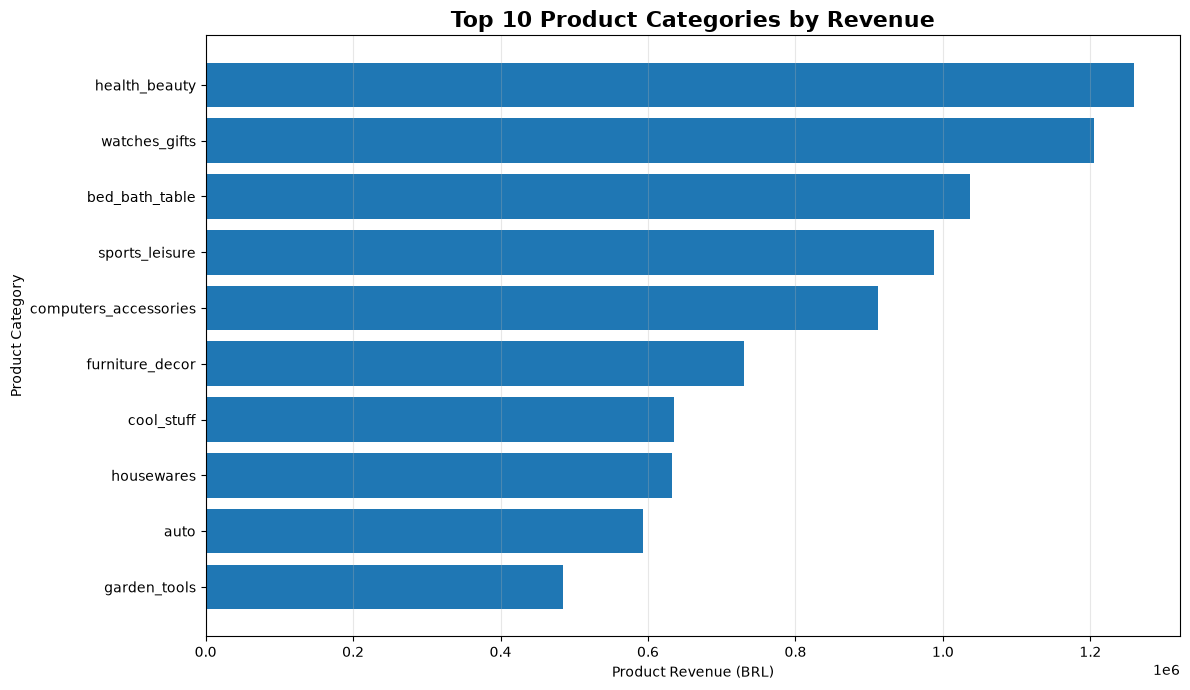

In [20]:

# Top 10 categories by revenue

top_categories = category_df.head(10).sort_values(
    "total_revenue"
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_categories["product_category"].fillna("Unknown"),
    top_categories["total_revenue"]
)

plt.title(
    "Top 10 Product Categories by Revenue",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Product Revenue (BRL)")
plt.ylabel("Product Category")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [21]:

# ==========================================
# CATEGORY REVENUE CONTRIBUTION
# ==========================================

# Sort categories by revenue
category_df = category_df.sort_values(
    "total_revenue",
    ascending=False
).reset_index(drop=True)

# Calculate cumulative revenue contribution
category_df["cumulative_revenue_pct"] = (
    category_df["revenue_contribution_pct"].cumsum()
)

# Top category metrics
top_5_share = category_df.head(5)[
    "revenue_contribution_pct"
].sum()

top_10_share = category_df.head(10)[
    "revenue_contribution_pct"
].sum()

print("========== CATEGORY REVENUE INSIGHTS ==========")

print("Total categories:", len(category_df))

print(
    "Top 5 category revenue contribution:",
    round(top_5_share, 2), "%"
)

print(
    "Top 10 category revenue contribution:",
    round(top_10_share, 2), "%"
)

print("\nTOP 10 CATEGORY CONTRIBUTION")

display(
    category_df[
        [
            "product_category",
            "total_revenue",
            "revenue_contribution_pct",
            "cumulative_revenue_pct"
        ]
    ].head(10).round(2)
)


========== CATEGORY REVENUE INSIGHTS ==========
Total categories: 74
Top 5 category revenue contribution: 39.74 %
Top 10 category revenue contribution: 62.36 %

TOP 10 CATEGORY CONTRIBUTION


,product_category,total_revenue,revenue_contribution_pct,cumulative_revenue_pct
0,health_beauty,1258681.34,9.26,9.26
1,watches_gifts,1205005.68,8.87,18.13
2,bed_bath_table,1036988.68,7.63,25.76
3,sports_leisure,988048.97,7.27,33.03
4,computers_accessories,911954.32,6.71,39.74
5,furniture_decor,729762.49,5.37,45.10
6,cool_stuff,635290.85,4.67,49.78
7,housewares,632248.66,4.65,54.43
8,auto,592720.11,4.36,58.79
9,garden_tools,485256.46,3.57,62.36


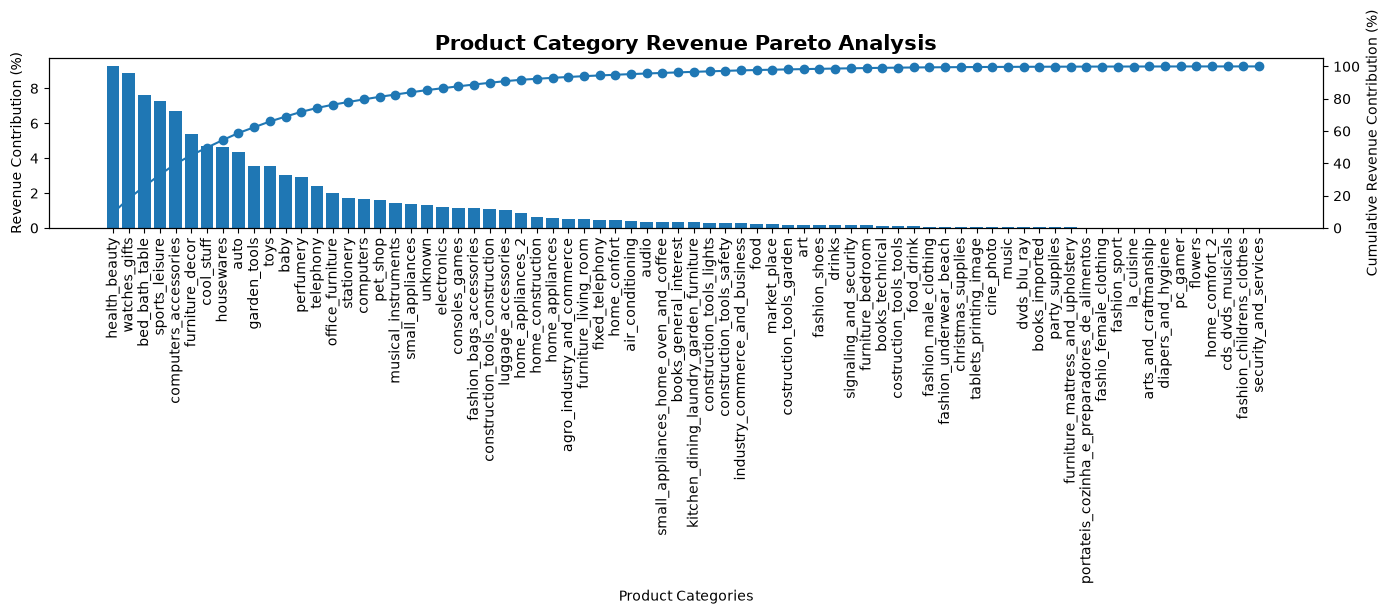

In [22]:

# ==========================================
# CATEGORY REVENUE PARETO CHART
# ==========================================

fig, ax1 = plt.subplots(figsize=(14, 6))

categories = category_df["product_category"].fillna("Unknown")

ax1.bar(
    categories,
    category_df["revenue_contribution_pct"]
)

ax1.set_xlabel("Product Categories")
ax1.set_ylabel("Revenue Contribution (%)")
ax1.tick_params(axis="x", rotation=90)

ax2 = ax1.twinx()

ax2.plot(
    categories,
    category_df["cumulative_revenue_pct"],
    marker="o"
)

ax2.set_ylabel("Cumulative Revenue Contribution (%)")
ax2.set_ylim(0, 105)

plt.title(
    "Product Category Revenue Pareto Analysis",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


In [23]:

# ==========================================
# CUSTOMER RFM ANALYSIS
# ==========================================

customer_columns_query = """
SELECT
    column_name,
    data_type
FROM information_schema.columns
WHERE table_schema = 'analytics'
  AND table_name = 'customer_rfm'
ORDER BY ordinal_position;
"""

customer_columns = pd.read_sql(
    customer_columns_query,
    engine
)

display(customer_columns)


,column_name,data_type
0,customer_unique_id,character varying
1,frequency,bigint
2,monetary,numeric
3,last_purchase_date,timestamp without time zone
4,first_purchase_date,timestamp without time zone
5,customer_lifespan_days,numeric


In [24]:
customer_columns_query = """
SELECT
    column_name,
    data_type
FROM information_schema.columns
WHERE table_schema = 'analytics'
  AND table_name = 'customer_rfm'
ORDER BY ordinal_position;
"""

customer_columns = pd.read_sql(
    customer_columns_query,
    engine
)

display(customer_columns)

,column_name,data_type
0,customer_unique_id,character varying
1,frequency,bigint
2,monetary,numeric
3,last_purchase_date,timestamp without time zone
4,first_purchase_date,timestamp without time zone
5,customer_lifespan_days,numeric


In [25]:

customer_columns_query = """
SELECT
    column_name,
    data_type
FROM information_schema.columns
WHERE table_schema = 'analytics'
  AND table_name = 'customer_rfm'
ORDER BY ordinal_position;
"""

customer_columns = pd.read_sql(
    customer_columns_query,
    engine
)

display(customer_columns)


,column_name,data_type
0,customer_unique_id,character varying
1,frequency,bigint
2,monetary,numeric
3,last_purchase_date,timestamp without time zone
4,first_purchase_date,timestamp without time zone
5,customer_lifespan_days,numeric


In [26]:

customer_columns_query = """
SELECT
    column_name,
    data_type
FROM information_schema.columns
WHERE table_schema = 'analytics'
  AND table_name = 'customer_rfm'
ORDER BY ordinal_position;
"""

customer_columns = pd.read_sql(customer_columns_query, engine)

display(customer_columns)


,column_name,data_type
0,customer_unique_id,character varying
1,frequency,bigint
2,monetary,numeric
3,last_purchase_date,timestamp without time zone
4,first_purchase_date,timestamp without time zone
5,customer_lifespan_days,numeric


In [27]:
customer_columns_query = """
SELECT
    column_name,
    data_type
FROM information_schema.columns
WHERE table_schema = 'analytics'
  AND table_name = 'customer_rfm'
ORDER BY ordinal_position;
"""

customer_columns = pd.read_sql(
    customer_columns_query,
    engine
)

display(customer_columns)


,column_name,data_type
0,customer_unique_id,character varying
1,frequency,bigint
2,monetary,numeric
3,last_purchase_date,timestamp without time zone
4,first_purchase_date,timestamp without time zone
5,customer_lifespan_days,numeric


In [28]:
customer_rfm_query = """
SELECT *
FROM analytics.customer_rfm;
"""

customer_rfm_df = pd.read_sql(customer_rfm_query, engine)

print("Dataset Shape:", customer_rfm_df.shape)

print("\nFirst 5 Customers:")
display(customer_rfm_df.head())

print("\nData Types:")
display(customer_rfm_df.dtypes)

Dataset Shape: (93358, 6)

First 5 Customers:


,customer_unique_id,frequency,monetary,last_purchase_date,first_purchase_date,customer_lifespan_days
0,0000366f3b9a7992bf8c76cfdf3221e2,1,129.90,2018-05-10 10:56:27,2018-05-10 10:56:27,0.0
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,18.90,2018-05-07 11:11:27,2018-05-07 11:11:27,0.0
2,0000f46a3911fa3c0805444483337064,1,69.00,2017-03-10 21:05:03,2017-03-10 21:05:03,0.0
3,0000f6ccb0745a6a4b88665a16c9f078,1,25.99,2017-10-12 20:29:41,2017-10-12 20:29:41,0.0
4,0004aac84e0df4da2b147fca70cf8255,1,180.00,2017-11-14 19:45:42,2017-11-14 19:45:42,0.0



Data Types:


customer_unique_id                   str
frequency                          int64
monetary                         float64
last_purchase_date        datetime64[us]
first_purchase_date       datetime64[us]
customer_lifespan_days           float64
dtype: object

In [29]:
customer_rfm_query = """
SELECT *
FROM analytics.customer_rfm;
"""

customer_rfm_df = pd.read_sql(customer_rfm_query, engine)

print("Dataset Shape:", customer_rfm_df.shape)
display(customer_rfm_df.head())
display(customer_rfm_df.describe())

Dataset Shape: (93358, 6)


,customer_unique_id,frequency,monetary,last_purchase_date,first_purchase_date,customer_lifespan_days
0,0000366f3b9a7992bf8c76cfdf3221e2,1,129.90,2018-05-10 10:56:27,2018-05-10 10:56:27,0.0
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,18.90,2018-05-07 11:11:27,2018-05-07 11:11:27,0.0
2,0000f46a3911fa3c0805444483337064,1,69.00,2017-03-10 21:05:03,2017-03-10 21:05:03,0.0
3,0000f6ccb0745a6a4b88665a16c9f078,1,25.99,2017-10-12 20:29:41,2017-10-12 20:29:41,0.0
4,0004aac84e0df4da2b147fca70cf8255,1,180.00,2017-11-14 19:45:42,2017-11-14 19:45:42,0.0


,frequency,monetary,last_purchase_date,first_purchase_date,customer_lifespan_days
count,93358.000000,93358.000000,93358,93358,93358.000000
mean,1.033420,141.621480,2018-01-04 03:47:36.045363,2018-01-01 12:18:32.380503,2.645183
min,1.000000,0.850000,2016-09-15 12:16:38,2016-09-15 12:16:38,0.000000
25%,1.000000,47.650000,2017-09-17 18:25:15,2017-09-13 15:41:22.500000,0.000000
50%,1.000000,89.730000,2018-01-23 00:12:12.500000,2018-01-20 06:48:07,0.000000
75%,1.000000,154.737500,2018-05-07 17:22:34.750000,2018-05-05 14:13:38.250000,0.000000
max,15.000000,13440.000000,2018-08-29 15:00:37,2018-08-29 15:00:37,633.080000
std,0.209097,215.694014,NaN,NaN,25.008095


In [30]:

customer_summary_query = """
WITH customer_metrics AS (
    SELECT
        customer_unique_id,
        frequency,
        monetary,
        (
            MAX(last_purchase_date) OVER ()::date
            - last_purchase_date::date
        ) AS recency_days
    FROM analytics.customer_rfm
)
SELECT
    COUNT(*) AS total_customers,
    ROUND(AVG(recency_days), 2) AS avg_recency_days,
    MIN(recency_days) AS min_recency_days,
    MAX(recency_days) AS max_recency_days,
    ROUND(AVG(frequency), 2) AS avg_frequency,
    MAX(frequency) AS max_frequency,
    ROUND(AVG(monetary), 2) AS avg_monetary_brl,
    MAX(monetary) AS max_monetary_brl
FROM customer_metrics;
"""

customer_summary_df = pd.read_sql(
    customer_summary_query,
    engine
)

display(customer_summary_df)


,total_customers,avg_recency_days,min_recency_days,max_recency_days,avg_frequency,max_frequency,avg_monetary_brl,max_monetary_brl
0,93358,237.48,0,713,1.03,15,141.62,13440.0


In [31]:

import pandas as pd

# Load customer RFM data if not already loaded
customer_rfm_query = """
SELECT *
FROM analytics.customer_rfm;
"""

customer_rfm_df = pd.read_sql(customer_rfm_query, engine)

# Calculate recency using latest delivered purchase date
reference_date = customer_rfm_df["last_purchase_date"].max()

customer_rfm_df["recency_days"] = (
    reference_date - customer_rfm_df["last_purchase_date"]
).dt.days

# Assign RFM scores (1 to 5)
customer_rfm_df["R_score"] = pd.qcut(
    customer_rfm_df["recency_days"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

customer_rfm_df["F_score"] = pd.qcut(
    customer_rfm_df["frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

customer_rfm_df["M_score"] = pd.qcut(
    customer_rfm_df["monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Combined RFM score
customer_rfm_df["RFM_score"] = (
    customer_rfm_df["R_score"].astype(str)
    + customer_rfm_df["F_score"].astype(str)
    + customer_rfm_df["M_score"].astype(str)
)

display(customer_rfm_df.head(10))


,customer_unique_id,frequency,monetary,last_purchase_date,first_purchase_date,customer_lifespan_days,recency_days,R_score,F_score,M_score,RFM_score
0,0000366f3b9a7992bf8c76cfdf3221e2,1,129.90,2018-05-10 10:56:27,2018-05-10 10:56:27,0.0,111,4,1,4,414
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,18.90,2018-05-07 11:11:27,2018-05-07 11:11:27,0.0,114,4,1,1,411
2,0000f46a3911fa3c0805444483337064,1,69.00,2017-03-10 21:05:03,2017-03-10 21:05:03,0.0,536,1,1,2,112
3,0000f6ccb0745a6a4b88665a16c9f078,1,25.99,2017-10-12 20:29:41,2017-10-12 20:29:41,0.0,320,2,1,1,211
4,0004aac84e0df4da2b147fca70cf8255,1,180.00,2017-11-14 19:45:42,2017-11-14 19:45:42,0.0,287,2,1,5,215
5,0004bd2a26a76fe21f786e4fbd80607f,1,154.00,2018-04-05 19:33:16,2018-04-05 19:33:16,0.0,145,4,1,4,414
6,00050ab1314c0e55a6ca13cf7181fecf,1,27.99,2018-04-20 12:57:23,2018-04-20 12:57:23,0.0,131,4,1,1,411
7,00053a61a98854899e70ed204dd4bafe,1,382.00,2018-02-28 11:15:41,2018-02-28 11:15:41,0.0,182,3,1,5,315
8,0005e1862207bf6ccc02e4228effd9a0,1,135.00,2017-03-04 23:32:12,2017-03-04 23:32:12,0.0,542,1,1,4,114
9,0005ef4cd20d2893f0d9fbd94d3c0d97,1,104.90,2018-03-12 15:22:12,2018-03-12 15:22:12,0.0,169,4,1,3,413


In [32]:

def assign_customer_segment(row):
    r = row["R_score"]
    f = row["F_score"]
    m = row["M_score"]

    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"

    elif r >= 3 and f >= 4:
        return "Loyal Customers"

    elif r >= 4 and f >= 2:
        return "Potential Loyalists"

    elif r >= 4 and f == 1:
        return "New Customers"

    elif r <= 2 and f >= 4 and m >= 4:
        return "Cannot Lose Them"

    elif r <= 2 and f >= 3:
        return "At Risk"

    elif r <= 2 and f <= 2:
        return "Hibernating"

    else:
        return "Other Customers"


customer_rfm_df["customer_segment"] = customer_rfm_df.apply(
    assign_customer_segment,
    axis=1
)

segment_summary = (
    customer_rfm_df.groupby("customer_segment")
    .agg(
        total_customers=("customer_unique_id", "count"),
        average_frequency=("frequency", "mean"),
        average_monetary=("monetary", "mean")
    )
    .reset_index()
    .sort_values("total_customers", ascending=False)
)

segment_summary["customer_percentage"] = (
    segment_summary["total_customers"]
    / len(customer_rfm_df) * 100
).round(2)

segment_summary["average_monetary"] = (
    segment_summary["average_monetary"].round(2)
)

display(segment_summary)


,customer_segment,total_customers,average_frequency,average_monetary,customer_percentage
0,At Risk,16313,1.017593,93.89,17.47
4,Loyal Customers,15950,1.058370,95.17,17.08
7,Potential Loyalists,14993,1.000000,140.93,16.06
3,Hibernating,14986,1.000000,140.88,16.05
6,Other Customers,11119,1.000000,130.72,11.91
5,New Customers,7479,1.000000,139.20,8.01
2,Champions,6474,1.171764,274.16,6.93
1,Cannot Lose Them,6044,1.130708,277.66,6.47


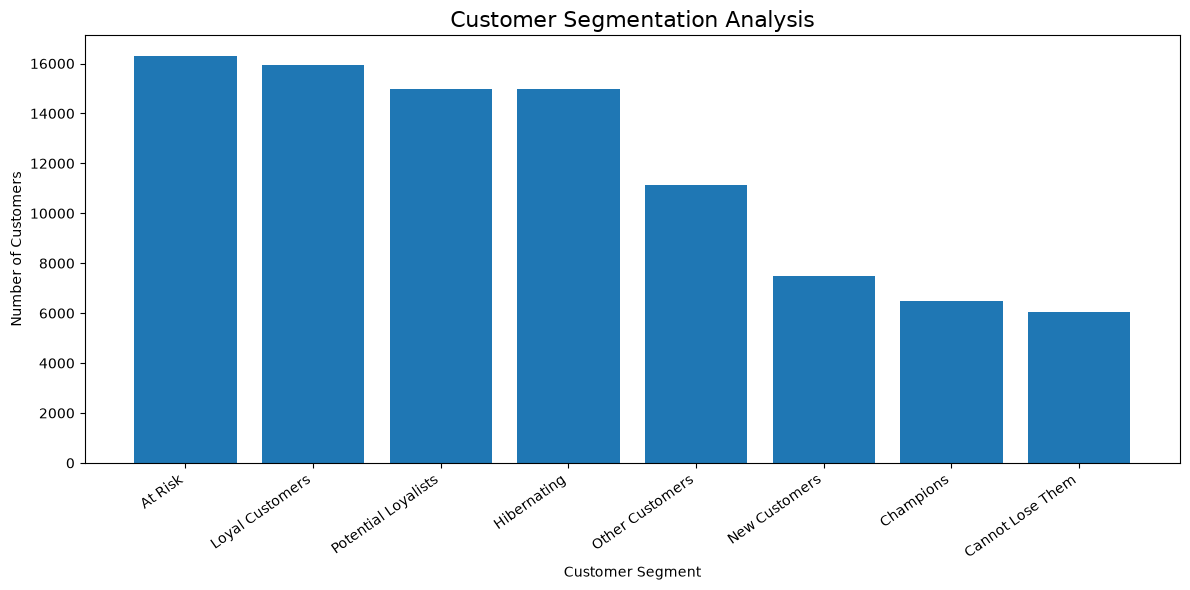

In [33]:

import matplotlib.pyplot as plt

# Customer count by segment
plt.figure(figsize=(12, 6))

plt.bar(
    segment_summary["customer_segment"],
    segment_summary["total_customers"]
)

plt.title("Customer Segmentation Analysis", fontsize=16)
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()


In [34]:
import os
# Create output directory if it doesn't exist
os.makedirs("python/outputs", exist_ok=True)
# Export customer RFM results
customer_rfm_df.to_csv(
    "python/outputs/customer_rfm_analysis.csv",
    index=False
)
# Export segment summary
segment_summary.to_csv(
    "python/outputs/customer_segment_summary.csv",
    index=False
)
print("RFM files exported successfully!")
print("1. customer_rfm_analysis.csv")
print("2. customer_segment_summary.csv")


RFM files exported successfully!
1. customer_rfm_analysis.csv
2. customer_segment_summary.csv


In [35]:

import os

output_folder = "python/outputs"

print("Folder exists:", os.path.exists(output_folder))

if os.path.exists(output_folder):
    print("\nFiles inside outputs:")
    for file in os.listdir(output_folder):
        print(file)


Folder exists: True

Files inside outputs:
sales_forecast_model_comparison.csv
customer_segment_summary.csv
top_10_cities.csv
freight_cost_analysis.csv
sales_forecast_model_results.csv
ml_customer_segmentation.csv
state_sales_analysis.csv
review_delivery_analysis.csv
payment_method_analysis.csv
delivery_summary.csv
customer_sentiment_summary.csv
ml_customer_segment_summary.csv
customer_rfm_analysis.csv
city_sales_analysis.csv
sales_forecast_business_insights.csv
monthly_delivery_analysis.csv
seller_performance_scorecard.csv
monthly_customer_retention.csv
payment_installment_analysis.csv


In [36]:
from sqlalchemy import text

create_rfm_table_query = """
CREATE TABLE IF NOT EXISTS analytics.customer_rfm_final (
    customer_unique_id VARCHAR(50) PRIMARY KEY,
    frequency BIGINT,
    monetary NUMERIC(12,2),
    last_purchase_date TIMESTAMP,
    first_purchase_date TIMESTAMP,
    customer_lifespan_days NUMERIC,
    recency_days INTEGER,
    r_score INTEGER,
    f_score INTEGER,
    m_score INTEGER,
    rfm_score VARCHAR(3),
    customer_segment VARCHAR(50)
);
"""

with engine.begin() as conn:
    conn.execute(text(create_rfm_table_query))

print("Table analytics.customer_rfm_final created successfully!")


Table analytics.customer_rfm_final created successfully!


In [37]:

from sqlalchemy import text

# Rename Python columns to match PostgreSQL table
rfm_upload_df = customer_rfm_df.rename(columns={
    "R_score": "r_score",
    "F_score": "f_score",
    "M_score": "m_score",
    "RFM_score": "rfm_score"
}).copy()

# Select columns in the database table's order
rfm_upload_df = rfm_upload_df[[
    "customer_unique_id",
    "frequency",
    "monetary",
    "last_purchase_date",
    "first_purchase_date",
    "customer_lifespan_days",
    "recency_days",
    "r_score",
    "f_score",
    "m_score",
    "rfm_score",
    "customer_segment"
]]

# Upload to a temporary table
rfm_upload_df.to_sql(
    "customer_rfm_load",
    engine,
    schema="analytics",
    if_exists="replace",
    index=False,
    chunksize=5000
)

# Insert/update final table safely
with engine.begin() as conn:
    conn.execute(text("""
        INSERT INTO analytics.customer_rfm_final
        SELECT * FROM analytics.customer_rfm_load
        ON CONFLICT (customer_unique_id)
        DO UPDATE SET
            frequency = EXCLUDED.frequency,
            monetary = EXCLUDED.monetary,
            last_purchase_date = EXCLUDED.last_purchase_date,
            first_purchase_date = EXCLUDED.first_purchase_date,
            customer_lifespan_days = EXCLUDED.customer_lifespan_days,
            recency_days = EXCLUDED.recency_days,
            r_score = EXCLUDED.r_score,
            f_score = EXCLUDED.f_score,
            m_score = EXCLUDED.m_score,
            rfm_score = EXCLUDED.rfm_score,
            customer_segment = EXCLUDED.customer_segment
    """))

    conn.execute(text("""
        DROP TABLE analytics.customer_rfm_load;
    """))

print("Customer RFM data uploaded successfully!")
print("Rows uploaded:", len(rfm_upload_df))


Customer RFM data uploaded successfully!
Rows uploaded: 93358


In [38]:

from sqlalchemy import text
import pandas as pd

verification_query = """
SELECT
    COUNT(*) AS total_customers,
    COUNT(DISTINCT customer_unique_id) AS unique_customers,
    COUNT(*) FILTER (WHERE customer_segment = 'Champions') AS champions,
    COUNT(*) FILTER (WHERE customer_segment = 'At Risk') AS at_risk,
    COUNT(*) FILTER (WHERE customer_segment = 'Hibernating') AS hibernating
FROM analytics.customer_rfm_final;
"""

verification_df = pd.read_sql(
    verification_query,
    engine
)

display(verification_df)


,total_customers,unique_customers,champions,at_risk,hibernating
0,93358,93358,6474,16313,14986


In [39]:
retention_check_query = """
SELECT
    customer_segment,
    COUNT(*) AS total_customers,
    ROUND(
        COUNT(*) * 100.0 /
        SUM(COUNT(*)) OVER (), 2
    ) AS customer_percentage,
    ROUND(AVG(frequency), 2) AS avg_orders,
    ROUND(AVG(monetary), 2) AS avg_spending_brl
FROM analytics.customer_rfm_final
GROUP BY customer_segment
ORDER BY total_customers DESC;
"""

retention_check_df = pd.read_sql(
    retention_check_query,
    engine
)

display(retention_check_df)

,customer_segment,total_customers,customer_percentage,avg_orders,avg_spending_brl
0,At Risk,16313,17.47,1.02,93.89
1,Loyal Customers,15950,17.08,1.06,95.17
2,Potential Loyalists,14993,16.06,1.00,140.93
3,Hibernating,14986,16.05,1.00,140.88
4,Other Customers,11119,11.91,1.00,130.72
5,New Customers,7479,8.01,1.00,139.20
6,Champions,6474,6.93,1.17,274.16
7,Cannot Lose Them,6044,6.47,1.13,277.66


In [40]:

validation_query = """
SELECT
    to_regclass('analytics.customer_rfm_final') AS table_name,
    CASE
        WHEN to_regclass('analytics.customer_rfm_final') IS NULL
        THEN 0
        ELSE (
            SELECT COUNT(*)
            FROM analytics.customer_rfm_final
        )
    END AS total_records;
"""

validation_df = pd.read_sql(validation_query, engine)
display(validation_df)


,table_name,total_records
0,analytics.customer_rfm_final,93358


In [41]:
retention_df = pd.read_sql("""
SELECT
    customer_segment,
    COUNT(*) AS total_customers,
    ROUND(AVG(frequency), 2) AS avg_frequency,
    ROUND(AVG(monetary), 2) AS avg_monetary
FROM analytics.customer_rfm_final
GROUP BY customer_segment
ORDER BY total_customers DESC;
""", engine)

display(retention_df)

,customer_segment,total_customers,avg_frequency,avg_monetary
0,At Risk,16313,1.02,93.89
1,Loyal Customers,15950,1.06,95.17
2,Potential Loyalists,14993,1.00,140.93
3,Hibernating,14986,1.00,140.88
4,Other Customers,11119,1.00,130.72
5,New Customers,7479,1.00,139.20
6,Champions,6474,1.17,274.16
7,Cannot Lose Them,6044,1.13,277.66


In [42]:
retention_query = """
SELECT
    COUNT(*) AS total_customers,
    COUNT(*) FILTER (
        WHERE frequency = 1
    ) AS one_time_customers,
    COUNT(*) FILTER (
        WHERE frequency > 1
    ) AS repeat_customers,
    ROUND(
        COUNT(*) FILTER (WHERE frequency > 1) * 100.0
        / NULLIF(COUNT(*), 0), 2
    ) AS repeat_customer_percentage
FROM analytics.customer_rfm;
"""

retention_df = pd.read_sql(retention_query, engine)
display(retention_df)

,total_customers,one_time_customers,repeat_customers,repeat_customer_percentage
0,93358,90557,2801,3.0


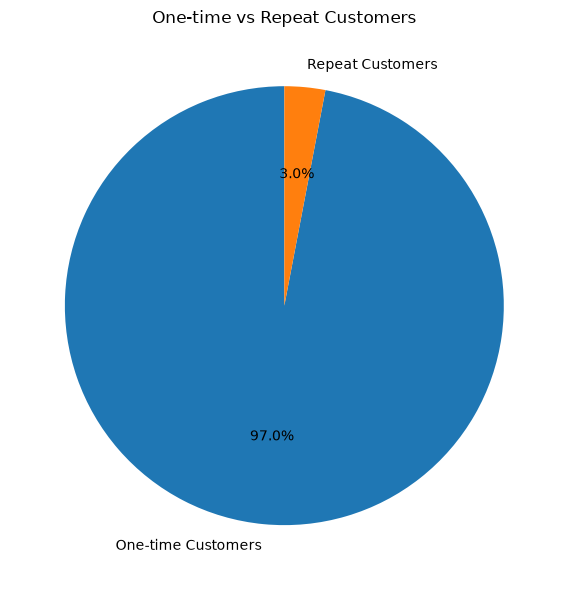

In [43]:
import matplotlib.pyplot as plt

retention_labels = ["One-time Customers", "Repeat Customers"]

retention_values = [
    int(retention_df["one_time_customers"].iloc[0]),
    int(retention_df["repeat_customers"].iloc[0])
]

plt.figure(figsize=(8, 6))

plt.pie(
    retention_values,
    labels=retention_labels,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("One-time vs Repeat Customers")
plt.tight_layout()
plt.show()

In [44]:

monthly_retention_query = """
WITH customer_monthly_orders AS (
    SELECT
        c.customer_unique_id,
        DATE_TRUNC('month', o.order_purchase_timestamp)::date
            AS order_month,
        COUNT(*) AS monthly_orders
    FROM staging.orders o
    JOIN staging.customers c
        ON o.customer_id = c.customer_id
    WHERE o.order_status = 'delivered'
    GROUP BY
        c.customer_unique_id,
        DATE_TRUNC('month', o.order_purchase_timestamp)::date
)
SELECT
    order_month,
    COUNT(*) AS active_customers,
    COUNT(*) FILTER (
        WHERE first_order_month = order_month
    ) AS new_customers
FROM (
    SELECT
        customer_unique_id,
        order_month,
        MIN(order_month) OVER (
            PARTITION BY customer_unique_id
        ) AS first_order_month
    FROM customer_monthly_orders
) x
GROUP BY order_month
ORDER BY order_month;
"""

monthly_retention_df = pd.read_sql(
    monthly_retention_query,
    engine
)

monthly_retention_df["repeat_customers"] = (
    monthly_retention_df["active_customers"]
    - monthly_retention_df["new_customers"]
)

display(monthly_retention_df.head(10))


,order_month,active_customers,new_customers,repeat_customers
0,2016-09-01,1,1,0
1,2016-10-01,262,262,0
2,2016-12-01,1,1,0
3,2017-01-01,718,717,1
4,2017-02-01,1630,1628,2
5,2017-03-01,2508,2503,5
6,2017-04-01,2274,2256,18
7,2017-05-01,3479,3451,28
8,2017-06-01,3076,3037,39
9,2017-07-01,3802,3752,50


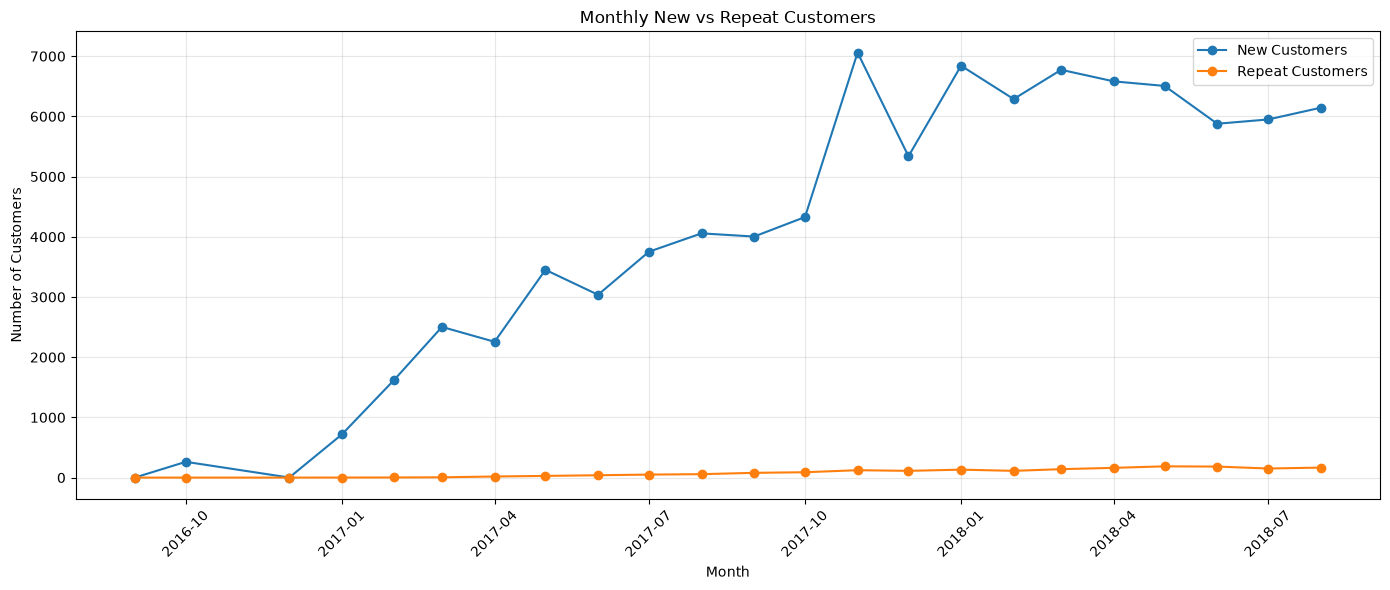

In [45]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_retention_df["order_month"],
    monthly_retention_df["new_customers"],
    marker="o",
    label="New Customers"
)

plt.plot(
    monthly_retention_df["order_month"],
    monthly_retention_df["repeat_customers"],
    marker="o",
    label="Repeat Customers"
)

plt.title("Monthly New vs Repeat Customers")
plt.xlabel("Month")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [46]:

import os

os.makedirs("python/outputs", exist_ok=True)

monthly_retention_df.to_csv(
    "python/outputs/monthly_customer_retention.csv",
    index=False
)

print("Monthly retention data exported!")
print("Rows:", len(monthly_retention_df))
print("File: python/outputs/monthly_customer_retention.csv")


Monthly retention data exported!
Rows: 23
File: python/outputs/monthly_customer_retention.csv


In [47]:

# Aggregate product performance by category
category_revenue_df = (
    product_df.groupby("product_category", dropna=False)
    .agg(
        total_items_sold=("total_items_sold", "sum"),
        total_revenue=("product_revenue", "sum")
    )
    .reset_index()
)

category_revenue_df["revenue_share_pct"] = (
    category_revenue_df["total_revenue"]
    / category_revenue_df["total_revenue"].sum()
    * 100
).round(2)

top_10_categories = (
    category_revenue_df
    .sort_values("total_revenue", ascending=False)
    .head(10)
)

display(top_10_categories)


,product_category,total_items_sold,total_revenue,revenue_share_pct
43,health_beauty,9670,1258681.34,9.26
73,watches_gifts,5991,1205005.68,8.87
7,bed_bath_table,11115,1036988.68,7.63
67,sports_leisure,8641,988048.97,7.27
15,computers_accessories,7827,911954.32,6.71
39,furniture_decor,8334,729762.49,5.37
20,cool_stuff,3796,635290.85,4.67
49,housewares,6964,632248.66,4.65
5,auto,4235,592720.11,4.36
42,garden_tools,4347,485256.46,3.57


In [48]:

total_revenue = category_revenue_df["total_revenue"].sum()

top_10_revenue = top_10_categories["total_revenue"].sum()

top_10_contribution = (
    top_10_revenue / total_revenue
) * 100

remaining_contribution = 100 - top_10_contribution

print("Total Category Revenue:", round(total_revenue, 2), "BRL")
print("Top 10 Category Revenue:", round(top_10_revenue, 2), "BRL")
print("Top 10 Revenue Contribution:", round(top_10_contribution, 2), "%")
print("Remaining Categories Contribution:", round(remaining_contribution, 2), "%")


Total Category Revenue: 13591643.7 BRL
Top 10 Category Revenue: 8475957.56 BRL
Top 10 Revenue Contribution: 62.36 %
Remaining Categories Contribution: 37.64 %


In [49]:

# Sort categories by revenue
pareto_df = category_revenue_df.sort_values(
    "total_revenue",
    ascending=False
).copy()

# Calculate cumulative revenue contribution
pareto_df["revenue_share_pct"] = (
    pareto_df["total_revenue"]
    / pareto_df["total_revenue"].sum()
) * 100

pareto_df["cumulative_revenue_pct"] = (
    pareto_df["revenue_share_pct"].cumsum()
)

# Find categories contributing up to approximately 80%
pareto_df["pareto_group"] = (
    pareto_df["cumulative_revenue_pct"] <= 80
)

display(pareto_df.head(15))

categories_for_80 = pareto_df[
    pareto_df["pareto_group"]
]

print(
    "Categories contributing up to 80%:",
    len(categories_for_80)
)


,product_category,total_items_sold,total_revenue,revenue_share_pct,cumulative_revenue_pct,pareto_group
43,health_beauty,9670,1258681.34,9.260700,9.260700,True
73,watches_gifts,5991,1205005.68,8.865783,18.126483,True
7,bed_bath_table,11115,1036988.68,7.629605,25.756088,True
67,sports_leisure,8641,988048.97,7.269533,33.025621,True
15,computers_accessories,7827,911954.32,6.709669,39.735290,True
39,furniture_decor,8334,729762.49,5.369200,45.104489,True
20,cool_stuff,3796,635290.85,4.674128,49.778618,True
49,housewares,6964,632248.66,4.651745,54.430363,True
5,auto,4235,592720.11,4.360916,58.791278,True
42,garden_tools,4347,485256.46,3.570256,62.361534,True


Categories contributing up to 80%: 17


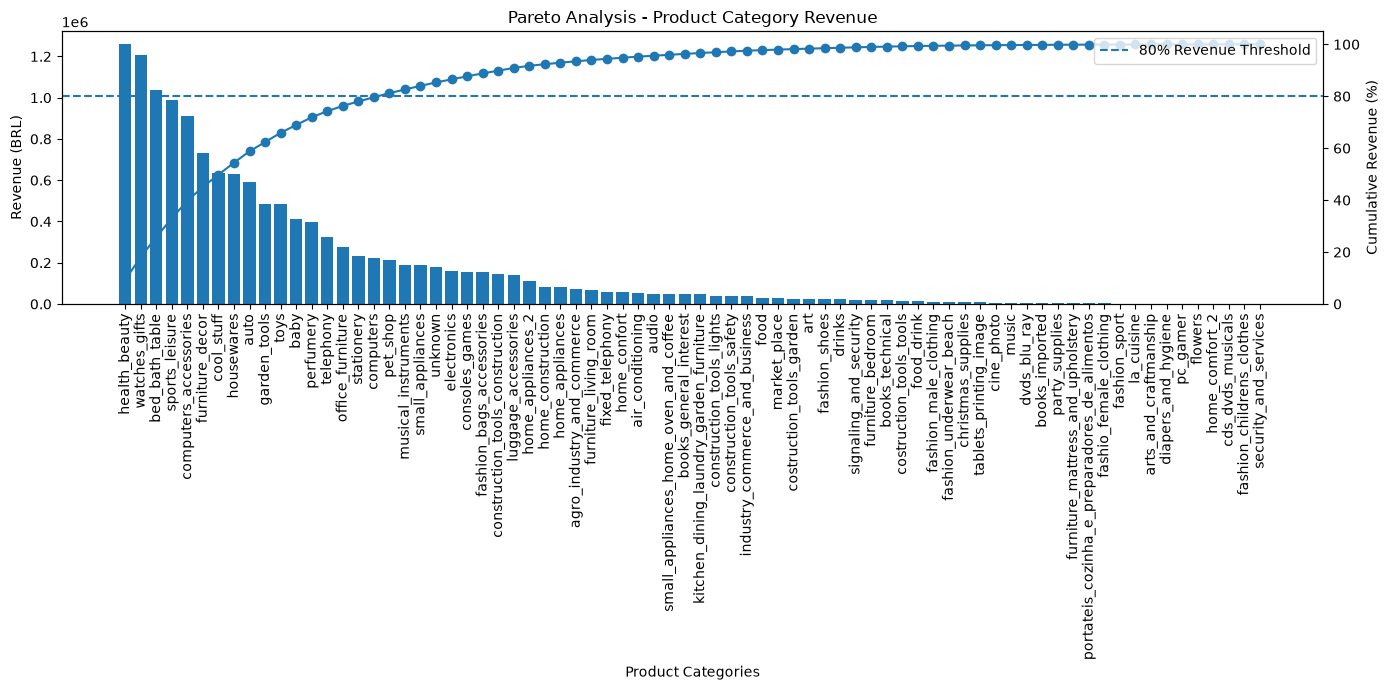

In [50]:

import matplotlib.pyplot as plt

pareto_plot_df = pareto_df.copy()

fig, ax1 = plt.subplots(figsize=(14, 7))

# Revenue bars
ax1.bar(
    pareto_plot_df["product_category"].astype(str),
    pareto_plot_df["total_revenue"]
)

ax1.set_xlabel("Product Categories")
ax1.set_ylabel("Revenue (BRL)")
ax1.set_title("Pareto Analysis - Product Category Revenue")
ax1.tick_params(axis="x", rotation=90)

# Cumulative percentage line
ax2 = ax1.twinx()

ax2.plot(
    range(len(pareto_plot_df)),
    pareto_plot_df["cumulative_revenue_pct"],
    marker="o"
)

ax2.axhline(y=80, linestyle="--", label="80% Revenue Threshold")
ax2.set_ylabel("Cumulative Revenue (%)")
ax2.set_ylim(0, 105)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()


In [51]:

# Generate category-level business insights

top_category = pareto_df.iloc[0]

lowest_category = pareto_df.iloc[-1]

top_5_share = pareto_df.head(5)["revenue_share_pct"].sum()

categories_80 = (
    pareto_df["cumulative_revenue_pct"] <= 80
).sum()

# Include the category that crosses the 80% threshold
categories_80 += 1

print("CATEGORY BUSINESS INSIGHTS")
print("-" * 45)

print(
    f"Top Revenue Category: "
    f"{top_category['product_category']}"
)

print(
    f"Top Category Revenue: "
    f"R$ {top_category['total_revenue']:,.2f}"
)

print(
    f"Top 5 Categories Revenue Share: "
    f"{top_5_share:.2f}%"
)

print(
    f"Categories needed to reach approximately 80% revenue: "
    f"{categories_80}"
)

print(
    f"Lowest Revenue Category: "
    f"{lowest_category['product_category']}"
)


CATEGORY BUSINESS INSIGHTS
---------------------------------------------
Top Revenue Category: health_beauty
Top Category Revenue: R$ 1,258,681.34
Top 5 Categories Revenue Share: 39.74%
Categories needed to reach approximately 80% revenue: 18
Lowest Revenue Category: security_and_services


In [52]:

seller_query = """
SELECT
    s.seller_id,
    s.seller_city,
    s.seller_state,
    COUNT(DISTINCT oi.order_id) AS total_orders,
    COUNT(*) AS total_items_sold,
    ROUND(SUM(oi.price), 2) AS total_revenue,
    ROUND(AVG(oi.price), 2) AS avg_item_price
FROM staging.sellers s
JOIN staging.order_items oi
    ON s.seller_id = oi.seller_id
JOIN staging.orders o
    ON oi.order_id = o.order_id
WHERE o.order_status = 'delivered'
GROUP BY
    s.seller_id,
    s.seller_city,
    s.seller_state
ORDER BY total_revenue DESC;
"""

seller_df = pd.read_sql(seller_query, engine)

print("Seller Dataset Shape:", seller_df.shape)
display(seller_df.head(10))


Seller Dataset Shape: (2970, 7)


,seller_id,seller_city,seller_state,total_orders,total_items_sold,total_revenue,avg_item_price
0,4869f7a5dfa277a7dca6462dcf3b52b2,guariba,SP,1124,1148,226987.93,197.72
1,53243585a1d6dc2643021fd1853d8905,lauro de freitas,BA,348,400,217940.44,544.85
2,4a3ca9315b744ce9f8e9374361493884,ibitinga,SP,1772,1949,196882.12,101.02
3,fa1c13f2614d7b5c4749cbc52fecda94,sumare,SP,578,579,190917.14,329.74
4,7c67e1448b00f6e969d365cea6b010ab,itaquaquecetuba,SP,973,1355,186570.05,137.69
5,7e93a43ef30c4f03f38b393420bc753a,barueri,SP,319,322,165981.49,515.47
6,da8622b14eb17ae2831f4ac5b9dab84a,piracicaba,SP,1311,1548,159816.87,103.24
7,7a67c85e85bb2ce8582c35f2203ad736,sao paulo,SP,1145,1155,139658.69,120.92
8,1025f0e2d44d7041d6cf58b6550e0bfa,sao paulo,SP,910,1420,138208.56,97.33
9,955fee9216a65b617aa5c0531780ce60,sao paulo,SP,1261,1472,131836.71,89.56


In [53]:

top_10_sellers = (
    seller_df
    .sort_values("total_revenue", ascending=False)
    .head(10)
    .copy()
)

display(top_10_sellers)



,seller_id,seller_city,seller_state,total_orders,total_items_sold,total_revenue,avg_item_price
0,4869f7a5dfa277a7dca6462dcf3b52b2,guariba,SP,1124,1148,226987.93,197.72
1,53243585a1d6dc2643021fd1853d8905,lauro de freitas,BA,348,400,217940.44,544.85
2,4a3ca9315b744ce9f8e9374361493884,ibitinga,SP,1772,1949,196882.12,101.02
3,fa1c13f2614d7b5c4749cbc52fecda94,sumare,SP,578,579,190917.14,329.74
4,7c67e1448b00f6e969d365cea6b010ab,itaquaquecetuba,SP,973,1355,186570.05,137.69
5,7e93a43ef30c4f03f38b393420bc753a,barueri,SP,319,322,165981.49,515.47
6,da8622b14eb17ae2831f4ac5b9dab84a,piracicaba,SP,1311,1548,159816.87,103.24
7,7a67c85e85bb2ce8582c35f2203ad736,sao paulo,SP,1145,1155,139658.69,120.92
8,1025f0e2d44d7041d6cf58b6550e0bfa,sao paulo,SP,910,1420,138208.56,97.33
9,955fee9216a65b617aa5c0531780ce60,sao paulo,SP,1261,1472,131836.71,89.56


In [54]:

total_seller_revenue = seller_df["total_revenue"].sum()

top_10_seller_revenue = top_10_sellers["total_revenue"].sum()

top_10_seller_share = (
    top_10_seller_revenue / total_seller_revenue
) * 100

print("SELLER REVENUE ANALYSIS")
print("-" * 40)

print(
    f"Total Seller Revenue: R$ {total_seller_revenue:,.2f}"
)

print(
    f"Top 10 Seller Revenue: R$ {top_10_seller_revenue:,.2f}"
)

print(
    f"Top 10 Seller Contribution: {top_10_seller_share:.2f}%"
)


SELLER REVENUE ANALYSIS
----------------------------------------
Total Seller Revenue: R$ 13,221,498.11
Top 10 Seller Revenue: R$ 1,754,800.00
Top 10 Seller Contribution: 13.27%


In [55]:

seller_delivery_query = """
SELECT
    oi.seller_id,
    COUNT(DISTINCT o.order_id) AS total_orders,
    COUNT(DISTINCT o.order_id) FILTER (
        WHERE o.order_delivered_customer_date
              <= o.order_estimated_delivery_date
    ) AS on_time_orders,
    COUNT(DISTINCT o.order_id) FILTER (
        WHERE o.order_delivered_customer_date
              > o.order_estimated_delivery_date
    ) AS late_orders,
    ROUND(
        AVG(
            EXTRACT(
                EPOCH FROM (
                    o.order_delivered_customer_date
                    - o.order_purchase_timestamp
                )
            ) / 86400
        )::numeric, 2
    ) AS avg_delivery_days
FROM staging.order_items oi
JOIN staging.orders o
    ON oi.order_id = o.order_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
  AND o.order_estimated_delivery_date IS NOT NULL
GROUP BY oi.seller_id
ORDER BY total_orders DESC;
"""

seller_delivery_df = pd.read_sql(
    seller_delivery_query,
    engine
)

seller_delivery_df["on_time_delivery_pct"] = (
    seller_delivery_df["on_time_orders"]
    / seller_delivery_df["total_orders"] * 100
).round(2)

display(seller_delivery_df.head(10))


,seller_id,total_orders,on_time_orders,late_orders,avg_delivery_days,on_time_delivery_pct
0,6560211a19b47992c3666cc44a7e94c0,1819,1702,117,9.54,93.57
1,4a3ca9315b744ce9f8e9374361493884,1772,1577,195,14.42,89.00
2,cc419e0650a3c5ba77189a1882b7556a,1651,1550,101,11.54,93.88
3,1f50f920176fa81dab994f9023523100,1399,1251,148,15.57,89.42
4,da8622b14eb17ae2831f4ac5b9dab84a,1311,1211,100,11.17,92.37
5,955fee9216a65b617aa5c0531780ce60,1261,1163,98,10.74,92.23
6,7a67c85e85bb2ce8582c35f2203ad736,1145,1077,68,11.17,94.06
7,ea8482cd71df3c1969d7b9473ff13abc,1132,1014,118,13.32,89.58
8,4869f7a5dfa277a7dca6462dcf3b52b2,1124,994,130,15.01,88.43
9,3d871de0142ce09b7081e2b9d1733cb1,1064,1001,63,13.42,94.08


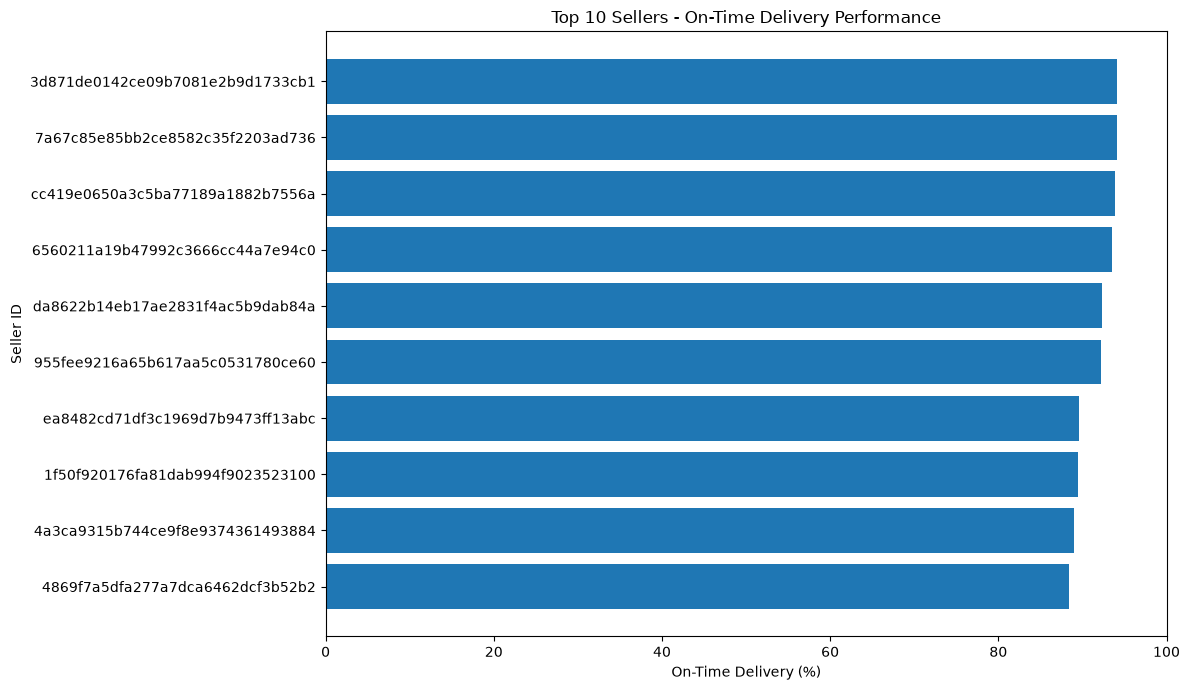

,seller_id,total_orders,on_time_orders,late_orders,avg_delivery_days,on_time_delivery_pct
8,4869f7a5dfa277a7dca6462dcf3b52b2,1124,994,130,15.01,88.43
1,4a3ca9315b744ce9f8e9374361493884,1772,1577,195,14.42,89.00
3,1f50f920176fa81dab994f9023523100,1399,1251,148,15.57,89.42
7,ea8482cd71df3c1969d7b9473ff13abc,1132,1014,118,13.32,89.58
5,955fee9216a65b617aa5c0531780ce60,1261,1163,98,10.74,92.23
4,da8622b14eb17ae2831f4ac5b9dab84a,1311,1211,100,11.17,92.37
0,6560211a19b47992c3666cc44a7e94c0,1819,1702,117,9.54,93.57
2,cc419e0650a3c5ba77189a1882b7556a,1651,1550,101,11.54,93.88
6,7a67c85e85bb2ce8582c35f2203ad736,1145,1077,68,11.17,94.06
9,3d871de0142ce09b7081e2b9d1733cb1,1064,1001,63,13.42,94.08


In [56]:

top_delivery_sellers = (
    seller_delivery_df
    .sort_values("total_orders", ascending=False)
    .head(10)
    .sort_values("on_time_delivery_pct")
)

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

plt.barh(
    top_delivery_sellers["seller_id"].astype(str),
    top_delivery_sellers["on_time_delivery_pct"]
)

plt.title("Top 10 Sellers - On-Time Delivery Performance")
plt.xlabel("On-Time Delivery (%)")
plt.ylabel("Seller ID")
plt.xlim(0, 100)

plt.tight_layout()
plt.show()

display(top_delivery_sellers)


In [57]:

# Merge seller revenue and delivery metrics
seller_scorecard = seller_df.merge(
    seller_delivery_df[
        [
            "seller_id",
            "on_time_delivery_pct",
            "avg_delivery_days",
            "late_orders"
        ]
    ],
    on="seller_id",
    how="left"
)

# Rank sellers by revenue
seller_scorecard["revenue_rank"] = (
    seller_scorecard["total_revenue"]
    .rank(method="dense", ascending=False)
    .astype(int)
)

# Sort by revenue
seller_scorecard = seller_scorecard.sort_values(
    "total_revenue",
    ascending=False
)

display(seller_scorecard.head(15))


,seller_id,seller_city,seller_state,total_orders,total_items_sold,total_revenue,avg_item_price,on_time_delivery_pct,avg_delivery_days,late_orders,revenue_rank
0,4869f7a5dfa277a7dca6462dcf3b52b2,guariba,SP,1124,1148,226987.93,197.72,88.43,15.01,130,1
1,53243585a1d6dc2643021fd1853d8905,lauro de freitas,BA,348,400,217940.44,544.85,95.69,13.37,15,2
2,4a3ca9315b744ce9f8e9374361493884,ibitinga,SP,1772,1949,196882.12,101.02,89.00,14.42,195,3
3,fa1c13f2614d7b5c4749cbc52fecda94,sumare,SP,578,579,190917.14,329.74,89.79,13.34,59,4
4,7c67e1448b00f6e969d365cea6b010ab,itaquaquecetuba,SP,973,1355,186570.05,137.69,89.93,22.39,98,5
5,7e93a43ef30c4f03f38b393420bc753a,barueri,SP,319,322,165981.49,515.47,94.36,11.34,18,6
6,da8622b14eb17ae2831f4ac5b9dab84a,piracicaba,SP,1311,1548,159816.87,103.24,92.37,11.17,100,7
7,7a67c85e85bb2ce8582c35f2203ad736,sao paulo,SP,1145,1155,139658.69,120.92,94.06,11.17,68,8
8,1025f0e2d44d7041d6cf58b6550e0bfa,sao paulo,SP,910,1420,138208.56,97.33,89.89,12.05,92,9
9,955fee9216a65b617aa5c0531780ce60,sao paulo,SP,1261,1472,131836.71,89.56,92.23,10.74,98,10


In [58]:

import os

os.makedirs("python/outputs", exist_ok=True)

seller_scorecard.to_csv(
    "python/outputs/seller_performance_scorecard.csv",
    index=False
)

print("Seller scorecard exported successfully!")
print("Total sellers:", len(seller_scorecard))
print("File: python/outputs/seller_performance_scorecard.csv")


Seller scorecard exported successfully!
Total sellers: 2970
File: python/outputs/seller_performance_scorecard.csv


In [59]:

review_query = """
SELECT
    review_id,
    order_id,
    review_score,
    review_comment_title,
    review_comment_message,
    review_creation_date,
    review_answer_timestamp
FROM staging.reviews;
"""

review_df = pd.read_sql(review_query, engine)

print("Review Dataset Shape:", review_df.shape)
print("\nReview Score Distribution:")

display(
    review_df["review_score"]
    .value_counts()
    .sort_index()
    .rename_axis("review_score")
    .reset_index(name="total_reviews")
)

print(
    "\nAverage Review Score:",
    round(review_df["review_score"].mean(), 2)
)


Review Dataset Shape: (99224, 7)

Review Score Distribution:


,review_score,total_reviews
0,1,11424
1,2,3151
2,3,8179
3,4,19142
4,5,57328



Average Review Score: 4.09


In [60]:

review_df["sentiment_category"] = pd.cut(
    review_df["review_score"],
    bins=[0, 2, 3, 5],
    labels=["Negative", "Neutral", "Positive"]
)

sentiment_summary = (
    review_df.groupby("sentiment_category", observed=False)
    .agg(
        total_reviews=("review_id", "count"),
        average_score=("review_score", "mean")
    )
    .reset_index()
)

sentiment_summary["review_percentage"] = (
    sentiment_summary["total_reviews"]
    / sentiment_summary["total_reviews"].sum()
    * 100
).round(2)

sentiment_summary["average_score"] = (
    sentiment_summary["average_score"].round(2)
)

display(sentiment_summary)


,sentiment_category,total_reviews,average_score,review_percentage
0,Negative,14575,1.22,14.69
1,Neutral,8179,3.00,8.24
2,Positive,76470,4.75,77.07


In [61]:

# Keep only non-empty review messages
comments_df = review_df[
    review_df["review_comment_message"].notna()
].copy()

# Clean text
comments_df["clean_review"] = (
    comments_df["review_comment_message"]
    .astype(str)
    .str.lower()
    .str.strip()
)

# Remove empty messages
comments_df = comments_df[
    comments_df["clean_review"] != ""
]

print("Total reviews:", len(review_df))
print("Reviews with comments:", len(comments_df))
print(
    "Comment availability:",
    round(len(comments_df) / len(review_df) * 100, 2),
    "%"
)

display(
    comments_df[
        ["review_score", "clean_review"]
    ].head(10)
)


Total reviews: 99224
Reviews with comments: 40950
Comment availability: 41.27 %


,review_score,clean_review
3,5,recebi bem antes do prazo estipulado.
4,5,parabéns lojas lannister adorei comprar pela i...
9,4,aparelho eficiente. no site a marca do aparelh...
12,4,"mas um pouco ,travando...pelo valor ta boa."
15,5,"vendedor confiável, produto ok e entrega antes..."
16,2,"gostaria de saber o que houve, sempre recebi e..."
19,1,péssimo
22,5,loja nota 10
24,5,obrigado pela atençao amim dispensada
27,5,a compra foi realizada facilmente.\r\na entreg...


In [62]:

from collections import Counter
import re

# Combine all customer review comments
all_reviews_text = " ".join(
    comments_df["clean_review"].dropna()
)

# Extract words
words = re.findall(r"\b[a-z]{3,}\b", all_reviews_text)

# Common English words to ignore
stop_words = {
    "the", "and", "for", "was", "with", "this",
    "that", "but", "not", "you", "are", "have",
    "had", "from", "they", "very", "one", "all",
    "its", "can", "has", "out", "been", "delivery",
    "product", "ordered", "order"
}

filtered_words = [
    word for word in words
    if word not in stop_words
]

word_frequency = Counter(filtered_words)

top_words_df = pd.DataFrame(
    word_frequency.most_common(20),
    columns=["word", "frequency"]
)

display(top_words_df)


,word,frequency
0,produto,18428
1,prazo,8475
2,que,8324
3,muito,7925
4,entrega,6528
5,com,5787
6,antes,5626
7,chegou,5555
8,recebi,5274
9,bom,4607


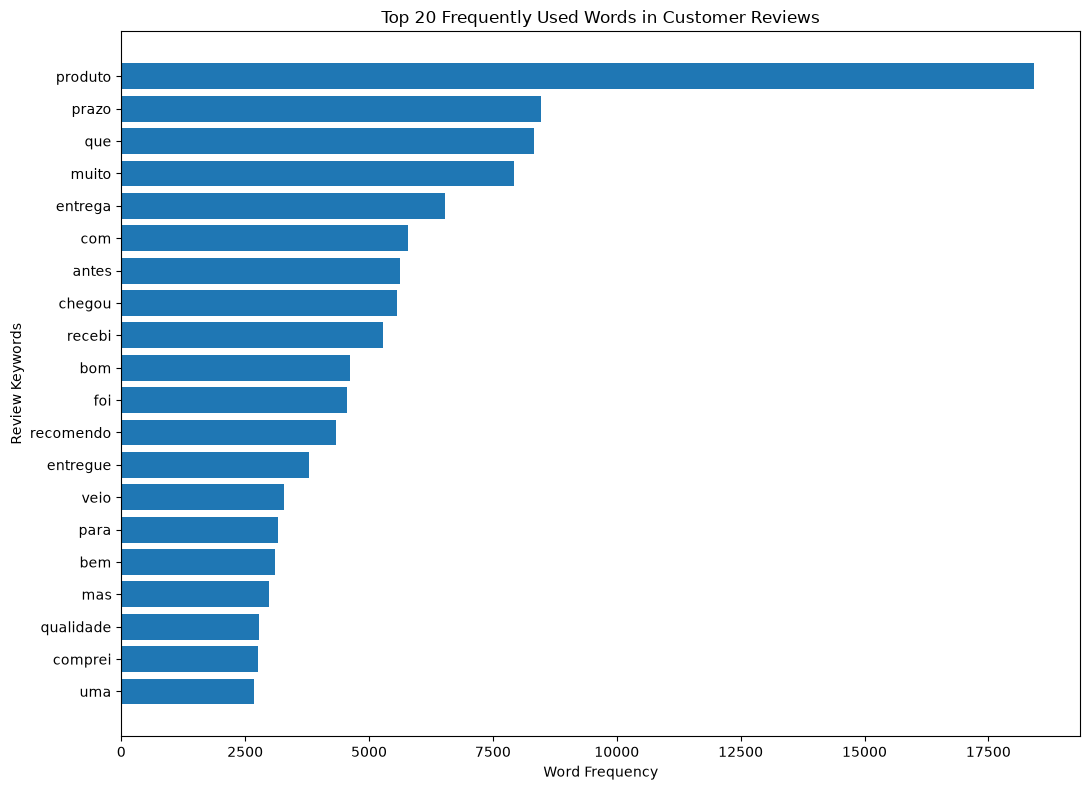

In [63]:

import matplotlib.pyplot as plt

top_words_plot = top_words_df.sort_values(
    "frequency",
    ascending=True
)

plt.figure(figsize=(11, 8))

plt.barh(
    top_words_plot["word"],
    top_words_plot["frequency"]
)

plt.title("Top 20 Frequently Used Words in Customer Reviews")
plt.xlabel("Word Frequency")
plt.ylabel("Review Keywords")

plt.tight_layout()
plt.show()


In [64]:

review_delivery_query = """
SELECT
    CASE
        WHEN o.order_delivered_customer_date
             > o.order_estimated_delivery_date
        THEN 'Late Delivery'
        ELSE 'On-Time Delivery'
    END AS delivery_status,
    COUNT(DISTINCT r.review_id) AS total_reviews,
    ROUND(AVG(r.review_score)::numeric, 2) AS average_review_score,
    COUNT(*) FILTER (
        WHERE r.review_score <= 2
    ) AS negative_reviews
FROM staging.reviews r
JOIN staging.orders o
    ON r.order_id = o.order_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
  AND o.order_estimated_delivery_date IS NOT NULL
GROUP BY 1
ORDER BY 1;
"""

review_delivery_df = pd.read_sql(
    review_delivery_query,
    engine
)

display(review_delivery_df)


,delivery_status,total_reviews,average_review_score,negative_reviews
0,Late Delivery,7674,2.57,4160
1,On-Time Delivery,88030,4.29,8186


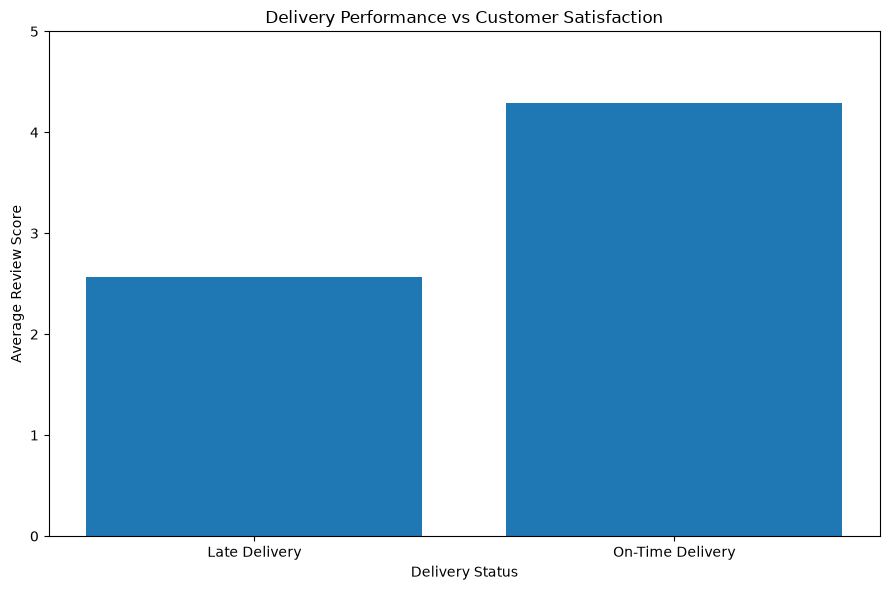

,delivery_status,total_reviews,average_review_score,negative_reviews
0,Late Delivery,7674,2.57,4160
1,On-Time Delivery,88030,4.29,8186


In [65]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.bar(
    review_delivery_df["delivery_status"],
    review_delivery_df["average_review_score"]
)

plt.title("Delivery Performance vs Customer Satisfaction")
plt.xlabel("Delivery Status")
plt.ylabel("Average Review Score")
plt.ylim(0, 5)

plt.tight_layout()
plt.show()

display(review_delivery_df)


In [66]:

import os

os.makedirs("python/outputs", exist_ok=True)

# Export review delivery analysis
review_delivery_df.to_csv(
    "python/outputs/review_delivery_analysis.csv",
    index=False
)

# Export sentiment summary
sentiment_summary.to_csv(
    "python/outputs/customer_sentiment_summary.csv",
    index=False
)

print("Review analysis exported successfully!")
print("Files:")
print("1. review_delivery_analysis.csv")
print("2. customer_sentiment_summary.csv")


Review analysis exported successfully!
Files:
1. review_delivery_analysis.csv
2. customer_sentiment_summary.csv


In [67]:

payment_query = """
SELECT
    payment_type,
    COUNT(*) AS total_transactions,
    COUNT(DISTINCT order_id) AS unique_orders,
    ROUND(SUM(payment_value), 2) AS total_payment_brl,
    ROUND(AVG(payment_value), 2) AS average_payment_brl,
    ROUND(
        SUM(payment_value) * 100.0
        / SUM(SUM(payment_value)) OVER (),
        2
    ) AS payment_value_share_pct
FROM staging.payments
GROUP BY payment_type
ORDER BY total_payment_brl DESC;
"""

payment_df = pd.read_sql(payment_query, engine)

print("Payment Dataset Shape:", payment_df.shape)
display(payment_df)


Payment Dataset Shape: (5, 6)


,payment_type,total_transactions,unique_orders,total_payment_brl,average_payment_brl,payment_value_share_pct
0,credit_card,76795,76505,12542084.19,163.32,78.34
1,boleto,19784,19784,2869361.27,145.03,17.92
2,voucher,5775,3866,379436.87,65.70,2.37
3,debit_card,1529,1528,217989.79,142.57,1.36
4,not_defined,3,3,0.00,0.00,0.00


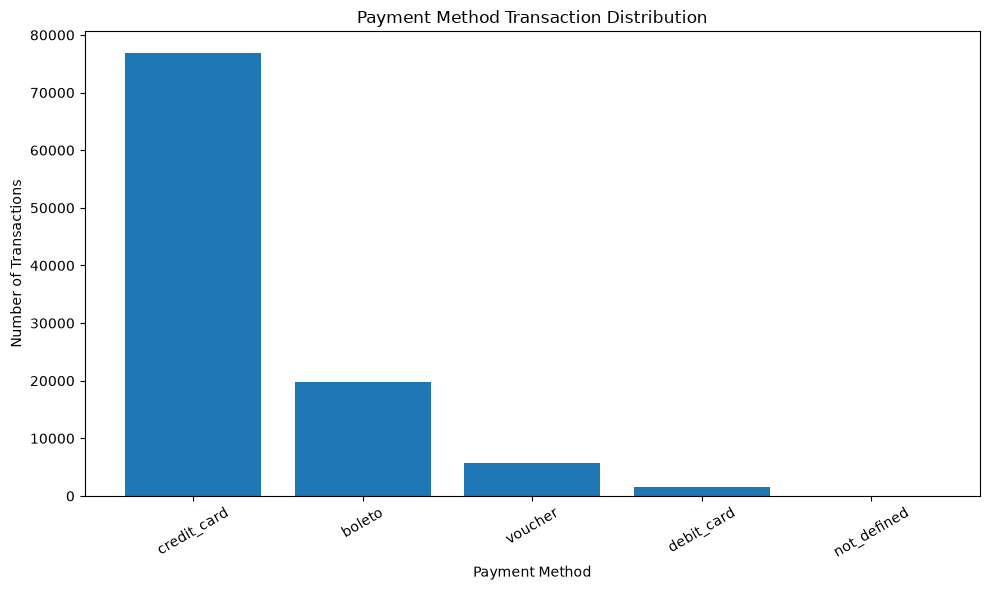

In [68]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    payment_df["payment_type"],
    payment_df["total_transactions"]
)

plt.title("Payment Method Transaction Distribution")
plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


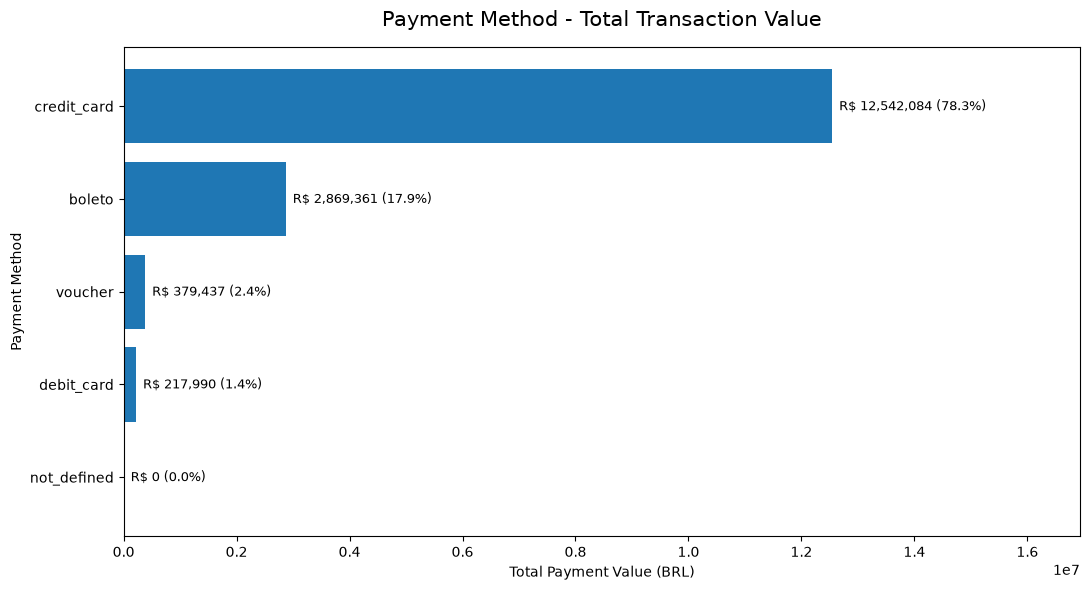

In [69]:

import matplotlib.pyplot as plt

payment_plot_df = payment_df.sort_values(
    "total_payment_brl",
    ascending=True
).copy()

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    payment_plot_df["payment_type"],
    payment_plot_df["total_payment_brl"]
)

ax.set_title(
    "Payment Method - Total Transaction Value",
    fontsize=15,
    pad=15
)
ax.set_xlabel("Total Payment Value (BRL)")
ax.set_ylabel("Payment Method")

# Add value and percentage labels
for bar, (_, row) in zip(bars, payment_plot_df.iterrows()):
    ax.text(
        bar.get_width() + payment_plot_df["total_payment_brl"].max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f'R$ {row["total_payment_brl"]:,.0f} ({row["payment_value_share_pct"]:.1f}%)',
        va="center",
        fontsize=9
    )

ax.set_xlim(
    0,
    payment_plot_df["total_payment_brl"].max() * 1.35
)

plt.tight_layout()
plt.show()


In [70]:

installment_query = """
SELECT
    payment_installments,
    COUNT(*) AS total_transactions,
    ROUND(SUM(payment_value), 2) AS total_payment_brl,
    ROUND(AVG(payment_value), 2) AS avg_payment_brl
FROM staging.payments
WHERE payment_type = 'credit_card'
GROUP BY payment_installments
ORDER BY payment_installments;
"""

installment_df = pd.read_sql(
    installment_query,
    engine
)

display(installment_df)


,payment_installments,total_transactions,total_payment_brl,avg_payment_brl
0,0,2,188.63,94.32
1,1,25455,2440445.43,95.87
2,2,12413,1579283.03,127.23
3,3,10461,1491103.80,142.54
4,4,7098,1163907.61,163.98
5,5,5239,961174.30,183.47
6,6,3920,822611.81,209.85
7,7,1626,305157.39,187.67
8,8,4268,1313423.34,307.74
9,9,644,131015.92,203.44


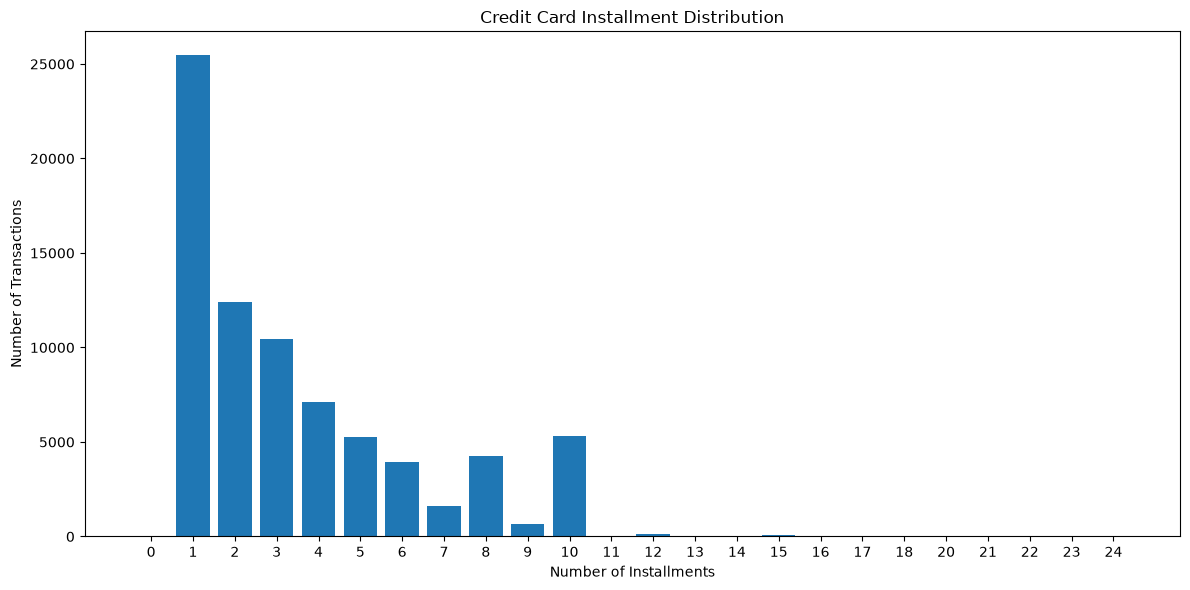

In [71]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    installment_df["payment_installments"].astype(str),
    installment_df["total_transactions"]
)

plt.title("Credit Card Installment Distribution")
plt.xlabel("Number of Installments")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()


In [72]:

# Calculate transaction share by installment option
installment_insights = installment_df.copy()

installment_insights["transaction_share_pct"] = (
    installment_insights["total_transactions"]
    / installment_insights["total_transactions"].sum()
    * 100
).round(2)

installment_insights["payment_value_share_pct"] = (
    installment_insights["total_payment_brl"]
    / installment_insights["total_payment_brl"].sum()
    * 100
).round(2)

display(
    installment_insights.sort_values(
        "total_transactions",
        ascending=False
    )
)

# Most popular installment option
popular_option = installment_insights.loc[
    installment_insights["total_transactions"].idxmax()
]

print("\nMOST POPULAR INSTALLMENT OPTION")
print("Installments:", popular_option["payment_installments"])
print("Transactions:", popular_option["total_transactions"])
print("Transaction Share:", popular_option["transaction_share_pct"], "%")


,payment_installments,total_transactions,total_payment_brl,avg_payment_brl,transaction_share_pct,payment_value_share_pct
1,1,25455,2440445.43,95.87,33.15,19.46
2,2,12413,1579283.03,127.23,16.16,12.59
3,3,10461,1491103.80,142.54,13.62,11.89
4,4,7098,1163907.61,163.98,9.24,9.28
10,10,5328,2211577.34,415.09,6.94,17.63
5,5,5239,961174.30,183.47,6.82,7.66
8,8,4268,1313423.34,307.74,5.56,10.47
6,6,3920,822611.81,209.85,5.10,6.56
7,7,1626,305157.39,187.67,2.12,2.43
9,9,644,131015.92,203.44,0.84,1.04



MOST POPULAR INSTALLMENT OPTION
Installments: 1.0
Transactions: 25455.0
Transaction Share: 33.15 %


In [73]:

import os

os.makedirs("python/outputs", exist_ok=True)

# Export payment method analysis
payment_df.to_csv(
    "python/outputs/payment_method_analysis.csv",
    index=False
)

# Export installment analysis
installment_insights.to_csv(
    "python/outputs/payment_installment_analysis.csv",
    index=False
)

print("Payment analytics exported successfully!")
print("1. payment_method_analysis.csv")
print("2. payment_installment_analysis.csv")
print("Output folder: python/outputs/")


Payment analytics exported successfully!
1. payment_method_analysis.csv
2. payment_installment_analysis.csv
Output folder: python/outputs/


In [74]:

state_sales_query = """
SELECT
    c.customer_state,
    COUNT(DISTINCT o.order_id) AS total_orders,
    COUNT(DISTINCT c.customer_unique_id) AS unique_customers,
    ROUND(SUM(oi.price), 2) AS total_revenue_brl,
    ROUND(AVG(oi.price), 2) AS average_item_price
FROM staging.orders o
JOIN staging.customers c
    ON o.customer_id = c.customer_id
JOIN staging.order_items oi
    ON o.order_id = oi.order_id
WHERE o.order_status = 'delivered'
GROUP BY c.customer_state
ORDER BY total_revenue_brl DESC;
"""

state_sales_df = pd.read_sql(
    state_sales_query,
    engine
)

print("State Sales Dataset:", state_sales_df.shape)
display(state_sales_df)


State Sales Dataset: (27, 5)


,customer_state,total_orders,unique_customers,total_revenue_brl,average_item_price
0,SP,40501,39156,5067633.16,109.10
1,RJ,12350,11917,1759651.13,124.42
2,MG,11354,11001,1552481.83,120.20
3,RS,5345,5168,728897.47,118.83
4,PR,4923,4769,666063.51,117.91
5,SC,3546,3449,507012.13,123.75
6,BA,3256,3158,493584.14,134.02
7,DF,2080,2019,296498.41,125.90
8,GO,1957,1895,282836.70,124.21
9,ES,1995,1928,268643.45,120.74


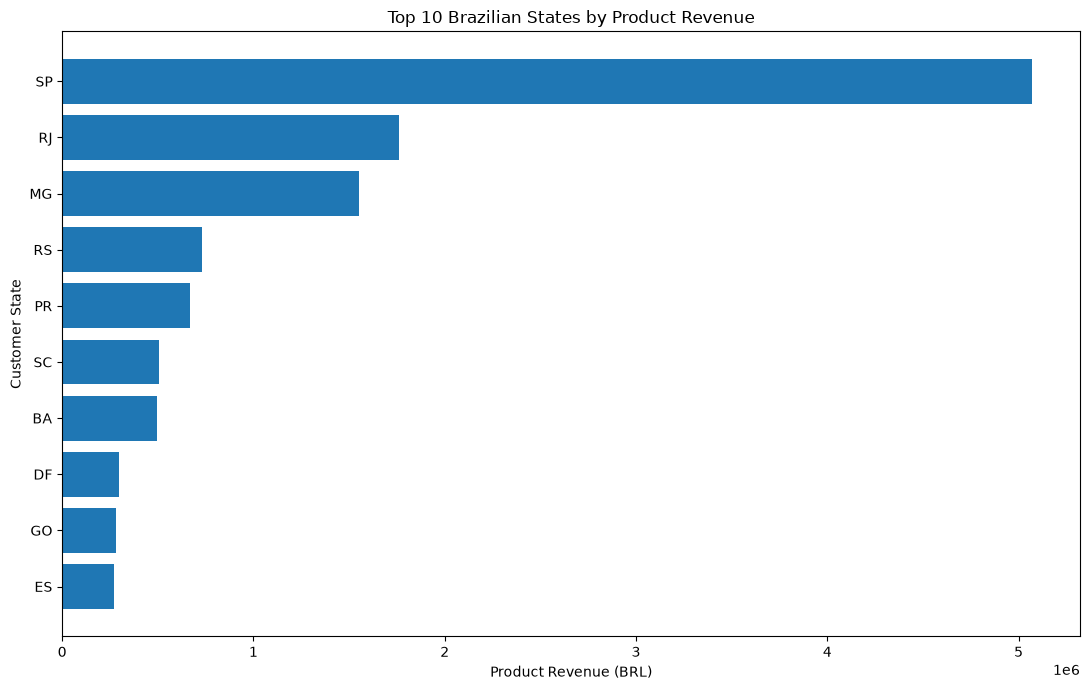

,customer_state,total_orders,unique_customers,total_revenue_brl,average_item_price
9,ES,1995,1928,268643.45,120.74
8,GO,1957,1895,282836.70,124.21
7,DF,2080,2019,296498.41,125.90
6,BA,3256,3158,493584.14,134.02
5,SC,3546,3449,507012.13,123.75
4,PR,4923,4769,666063.51,117.91
3,RS,5345,5168,728897.47,118.83
2,MG,11354,11001,1552481.83,120.20
1,RJ,12350,11917,1759651.13,124.42
0,SP,40501,39156,5067633.16,109.10


In [75]:

import matplotlib.pyplot as plt

top_states = (
    state_sales_df
    .sort_values("total_revenue_brl", ascending=False)
    .head(10)
    .sort_values("total_revenue_brl")
)

plt.figure(figsize=(11, 7))

plt.barh(
    top_states["customer_state"],
    top_states["total_revenue_brl"]
)

plt.title("Top 10 Brazilian States by Product Revenue")
plt.xlabel("Product Revenue (BRL)")
plt.ylabel("Customer State")

plt.tight_layout()
plt.show()

display(top_states)


In [76]:

city_sales_query = """
SELECT
    c.customer_city,
    c.customer_state,
    COUNT(DISTINCT o.order_id) AS total_orders,
    COUNT(DISTINCT c.customer_unique_id) AS unique_customers,
    ROUND(SUM(oi.price), 2) AS total_revenue_brl,
    ROUND(AVG(oi.price), 2) AS average_item_price
FROM staging.orders o
JOIN staging.customers c
    ON o.customer_id = c.customer_id
JOIN staging.order_items oi
    ON o.order_id = oi.order_id
WHERE o.order_status = 'delivered'
GROUP BY
    c.customer_city,
    c.customer_state
ORDER BY total_revenue_brl DESC;
"""

city_sales_df = pd.read_sql(
    city_sales_query,
    engine
)

print("City Dataset Shape:", city_sales_df.shape)
display(city_sales_df.head(15))


City Dataset Shape: (4272, 6)


,customer_city,customer_state,total_orders,unique_customers,total_revenue_brl,average_item_price
0,sao paulo,SP,15045,14528,1859556.83,106.87
1,rio de janeiro,RJ,6601,6361,955573.97,125.87
2,belo horizonte,MG,2697,2606,346039.04,112.10
3,brasilia,DF,2071,2013,295814.72,126.36
4,curitiba,PR,1489,1434,205999.33,119.28
5,campinas,SP,1406,1363,184657.87,113.57
6,porto alegre,RS,1342,1292,182319.55,115.91
7,salvador,BA,1188,1154,173273.05,127.59
8,guarulhos,SP,1144,1111,139008.19,107.43
9,niteroi,RJ,825,788,115890.26,120.97


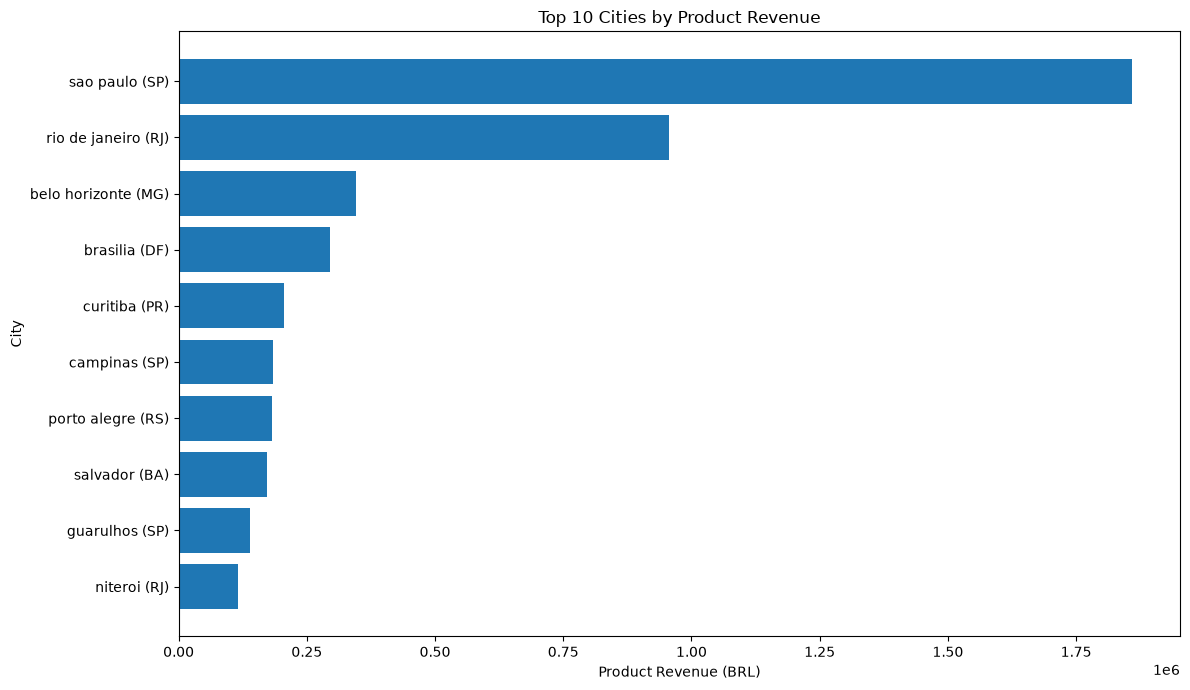

,customer_city,customer_state,total_orders,unique_customers,total_revenue_brl,average_item_price,city_label
9,niteroi,RJ,825,788,115890.26,120.97,niteroi (RJ)
8,guarulhos,SP,1144,1111,139008.19,107.43,guarulhos (SP)
7,salvador,BA,1188,1154,173273.05,127.59,salvador (BA)
6,porto alegre,RS,1342,1292,182319.55,115.91,porto alegre (RS)
5,campinas,SP,1406,1363,184657.87,113.57,campinas (SP)
4,curitiba,PR,1489,1434,205999.33,119.28,curitiba (PR)
3,brasilia,DF,2071,2013,295814.72,126.36,brasilia (DF)
2,belo horizonte,MG,2697,2606,346039.04,112.10,belo horizonte (MG)
1,rio de janeiro,RJ,6601,6361,955573.97,125.87,rio de janeiro (RJ)
0,sao paulo,SP,15045,14528,1859556.83,106.87,sao paulo (SP)


In [77]:

import matplotlib.pyplot as plt

top_10_cities = (
    city_sales_df
    .sort_values("total_revenue_brl", ascending=False)
    .head(10)
    .copy()
)

# City + state label, to distinguish cities with similar names
top_10_cities["city_label"] = (
    top_10_cities["customer_city"]
    + " ("
    + top_10_cities["customer_state"]
    + ")"
)

top_10_cities = top_10_cities.sort_values(
    "total_revenue_brl"
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_10_cities["city_label"],
    top_10_cities["total_revenue_brl"]
)

plt.title("Top 10 Cities by Product Revenue")
plt.xlabel("Product Revenue (BRL)")
plt.ylabel("City")

plt.tight_layout()
plt.show()

display(top_10_cities)


In [78]:

total_city_revenue = city_sales_df["total_revenue_brl"].sum()

top_10_city_revenue = top_10_cities["total_revenue_brl"].sum()

top_10_city_share = (
    top_10_city_revenue / total_city_revenue
) * 100

print("GEOGRAPHIC REVENUE ANALYSIS")
print("-" * 45)

print(f"Total Revenue: R$ {total_city_revenue:,.2f}")
print(f"Top 10 City Revenue: R$ {top_10_city_revenue:,.2f}")
print(f"Top 10 City Contribution: {top_10_city_share:.2f}%")
print(
    f"Other Cities Contribution: "
    f"{100 - top_10_city_share:.2f}%"
)


GEOGRAPHIC REVENUE ANALYSIS
---------------------------------------------
Total Revenue: R$ 13,221,498.11
Top 10 City Revenue: R$ 4,458,132.81
Top 10 City Contribution: 33.72%
Other Cities Contribution: 66.28%


In [79]:

import os

os.makedirs("python/outputs", exist_ok=True)

# Export state-wise sales
state_sales_df.to_csv(
    "python/outputs/state_sales_analysis.csv",
    index=False
)

# Export city-wise sales
city_sales_df.to_csv(
    "python/outputs/city_sales_analysis.csv",
    index=False
)

# Export top 10 cities
top_10_cities.to_csv(
    "python/outputs/top_10_cities.csv",
    index=False
)

print("Geographic analysis exported successfully!")
print("State records:", len(state_sales_df))
print("City records:", len(city_sales_df))
print("Files saved in python/outputs/")


Geographic analysis exported successfully!
State records: 27
City records: 4272
Files saved in python/outputs/


In [80]:

delivery_summary_query = """
WITH order_freight AS (
    SELECT
        order_id,
        SUM(freight_value) AS total_freight
    FROM staging.order_items
    GROUP BY order_id
),
delivery_metrics AS (
    SELECT
        o.order_id,
        o.order_purchase_timestamp,
        o.order_delivered_customer_date,
        o.order_estimated_delivery_date,
        f.total_freight,
        EXTRACT(
            EPOCH FROM (
                o.order_delivered_customer_date
                - o.order_purchase_timestamp
            )
        ) / 86400 AS delivery_days,
        EXTRACT(
            EPOCH FROM (
                o.order_delivered_customer_date
                - o.order_estimated_delivery_date
            )
        ) / 86400 AS delay_days
    FROM staging.orders o
    LEFT JOIN order_freight f
        ON o.order_id = f.order_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
)
SELECT
    COUNT(*) AS delivered_orders,
    ROUND(AVG(delivery_days)::numeric, 2)
        AS avg_delivery_days,
    ROUND(MAX(delivery_days)::numeric, 2)
        AS max_delivery_days,
    COUNT(*) FILTER (
        WHERE delay_days <= 0
    ) AS on_time_orders,
    COUNT(*) FILTER (
        WHERE delay_days > 0
    ) AS late_orders,
    ROUND(AVG(total_freight)::numeric, 2)
        AS avg_freight_per_order,
    ROUND(SUM(total_freight)::numeric, 2)
        AS total_freight
FROM delivery_metrics;
"""

delivery_summary_df = pd.read_sql(
    delivery_summary_query,
    engine
)

display(delivery_summary_df)


,delivered_orders,avg_delivery_days,max_delivery_days,on_time_orders,late_orders,avg_freight_per_order,total_freight
0,96470,12.56,209.63,88644,7826,22.79,2198145.9


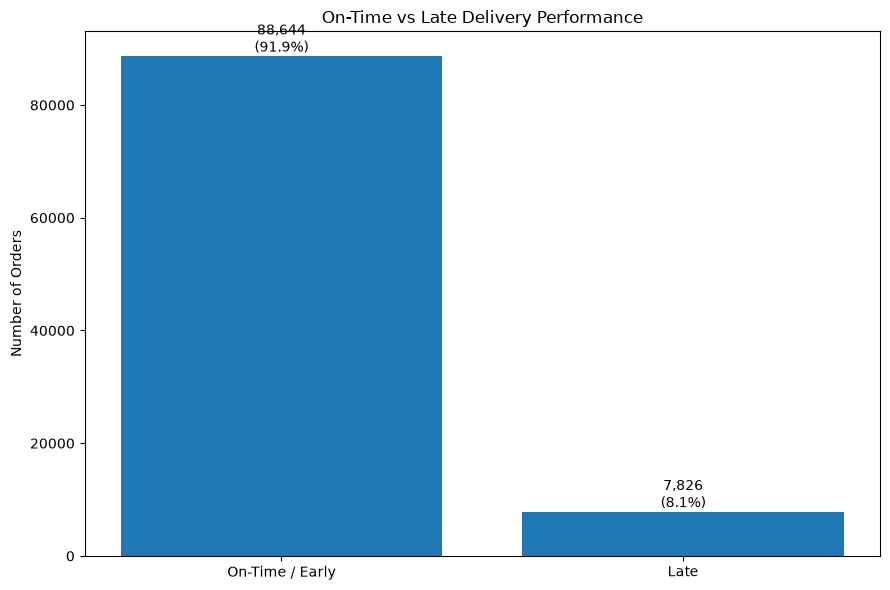

In [81]:

import matplotlib.pyplot as plt

on_time = int(delivery_summary_df["on_time_orders"].iloc[0])
late = int(delivery_summary_df["late_orders"].iloc[0])

delivery_labels = ["On-Time / Early", "Late"]
delivery_values = [on_time, late]

total = on_time + late

delivery_percentages = [
    value / total * 100 for value in delivery_values
]

fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.bar(delivery_labels, delivery_values)

ax.set_title("On-Time vs Late Delivery Performance")
ax.set_ylabel("Number of Orders")

for bar, value, percentage in zip(
    bars, delivery_values, delivery_percentages
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,}\n({percentage:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()


In [82]:

monthly_delivery_query = """
WITH freight AS (
    SELECT
        order_id,
        SUM(freight_value) AS total_freight
    FROM staging.order_items
    GROUP BY order_id
),
delivery_data AS (
    SELECT
        DATE_TRUNC(
            'month', o.order_purchase_timestamp
        )::date AS order_month,

        EXTRACT(
            EPOCH FROM (
                o.order_delivered_customer_date
                - o.order_purchase_timestamp
            )
        ) / 86400 AS delivery_days,

        CASE
            WHEN o.order_delivered_customer_date
                 <= o.order_estimated_delivery_date
            THEN 1 ELSE 0
        END AS on_time_flag,

        f.total_freight

    FROM staging.orders o
    LEFT JOIN freight f
        ON o.order_id = f.order_id

    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
      AND o.order_estimated_delivery_date IS NOT NULL
)
SELECT
    order_month,
    COUNT(*) AS delivered_orders,
    ROUND(AVG(delivery_days)::numeric, 2)
        AS avg_delivery_days,
    ROUND(AVG(on_time_flag) * 100, 2)
        AS on_time_delivery_pct,
    ROUND(AVG(total_freight)::numeric, 2)
        AS avg_freight_brl
FROM delivery_data
GROUP BY order_month
ORDER BY order_month;
"""

monthly_delivery_df = pd.read_sql(
    monthly_delivery_query,
    engine
)

print("Monthly Delivery Dataset:", monthly_delivery_df.shape)
display(monthly_delivery_df.head(10))


Monthly Delivery Dataset: (23, 5)


,order_month,delivered_orders,avg_delivery_days,on_time_delivery_pct,avg_freight_brl
0,2016-09-01,1,54.81,0.00,8.49
1,2016-10-01,265,19.60,98.87,23.27
2,2016-12-01,1,4.69,100.00,8.72
3,2017-01-01,750,12.65,96.93,20.91
4,2017-02-01,1653,13.17,96.79,22.39
5,2017-03-01,2546,12.95,94.42,21.65
6,2017-04-01,2303,14.92,92.14,21.77
7,2017-05-01,3545,11.32,96.39,21.86
8,2017-06-01,3135,12.01,96.14,21.73
9,2017-07-01,3872,11.59,96.57,21.87


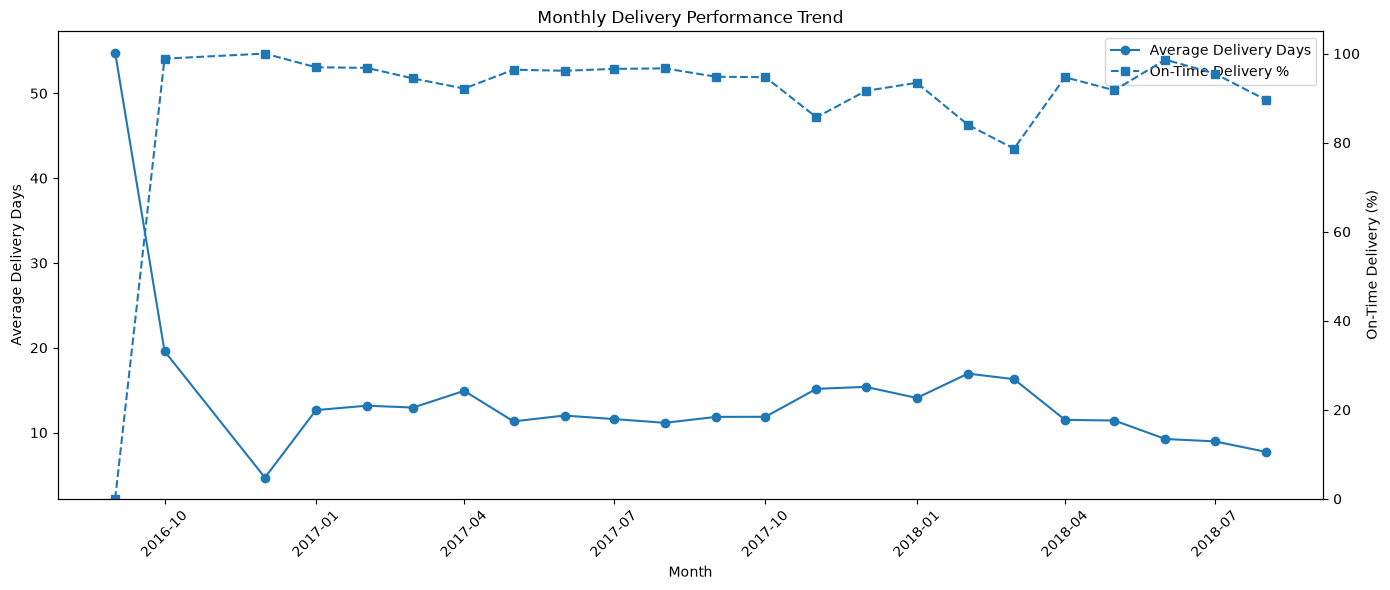

In [83]:

import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(14, 6))

# Average delivery days
ax1.plot(
    monthly_delivery_df["order_month"],
    monthly_delivery_df["avg_delivery_days"],
    marker="o",
    label="Average Delivery Days"
)

ax1.set_xlabel("Month")
ax1.set_ylabel("Average Delivery Days")
ax1.tick_params(axis="x", rotation=45)

# On-time delivery percentage
ax2 = ax1.twinx()

ax2.plot(
    monthly_delivery_df["order_month"],
    monthly_delivery_df["on_time_delivery_pct"],
    marker="s",
    linestyle="--",
    label="On-Time Delivery %"
)

ax2.set_ylabel("On-Time Delivery (%)")
ax2.set_ylim(0, 105)

ax1.set_title("Monthly Delivery Performance Trend")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.tight_layout()
plt.show()


In [84]:

freight_analysis_query = """
WITH order_metrics AS (
    SELECT
        o.order_id,
        SUM(oi.price) AS product_revenue,
        SUM(oi.freight_value) AS freight_cost
    FROM staging.orders o
    JOIN staging.order_items oi
        ON o.order_id = oi.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY o.order_id
)
SELECT
    COUNT(*) AS total_orders,
    ROUND(SUM(product_revenue)::numeric, 2)
        AS total_product_revenue_brl,
    ROUND(SUM(freight_cost)::numeric, 2)
        AS total_freight_brl,
    ROUND(AVG(freight_cost)::numeric, 2)
        AS avg_freight_per_order_brl,
    ROUND(
        SUM(freight_cost) * 100.0
        / NULLIF(SUM(product_revenue), 0),
        2
    ) AS freight_to_revenue_pct
FROM order_metrics;
"""

freight_analysis_df = pd.read_sql(
    freight_analysis_query,
    engine
)

display(freight_analysis_df)


,total_orders,total_product_revenue_brl,total_freight_brl,avg_freight_per_order_brl,freight_to_revenue_pct
0,96478,13221498.11,2198275.64,22.79,16.63


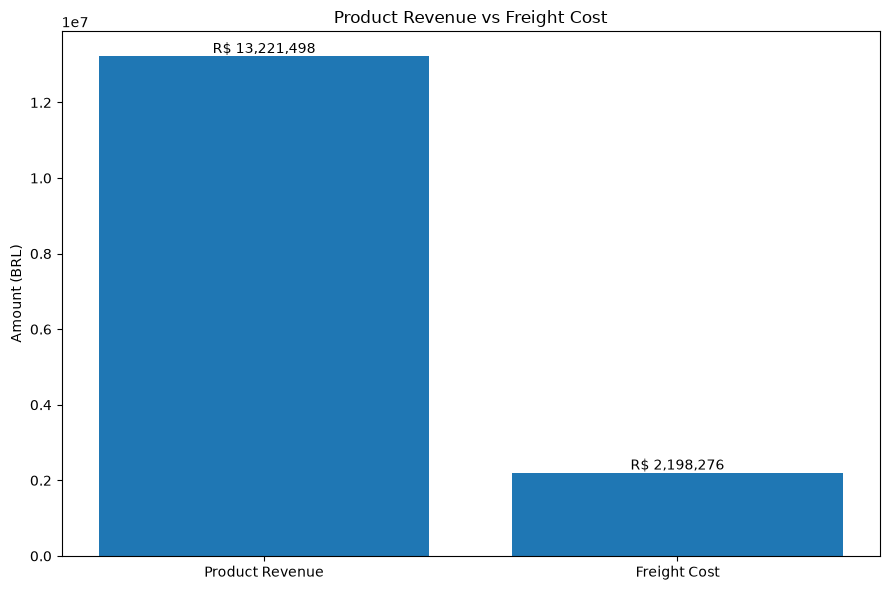

Freight-to-Revenue Ratio: 16.63 %


In [85]:

import matplotlib.pyplot as plt

freight_row = freight_analysis_df.iloc[0]

metrics = [
    "Product Revenue",
    "Freight Cost"
]

values = [
    freight_row["total_product_revenue_brl"],
    freight_row["total_freight_brl"]
]

plt.figure(figsize=(9, 6))

bars = plt.bar(metrics, values)

plt.title("Product Revenue vs Freight Cost")
plt.ylabel("Amount (BRL)")

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"R$ {value:,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

print(
    "Freight-to-Revenue Ratio:",
    freight_row["freight_to_revenue_pct"],
    "%"
)


In [86]:

import os

os.makedirs("python/outputs", exist_ok=True)

delivery_exports = {
    "delivery_summary.csv": "delivery_summary_df",
    "monthly_delivery_analysis.csv": "monthly_delivery_df",
    "freight_cost_analysis.csv": "freight_analysis_df"
}

for filename, variable_name in delivery_exports.items():
    if variable_name not in globals():
        print(f"Not available yet: {variable_name}")
        continue

    globals()[variable_name].to_csv(
        f"python/outputs/{filename}",
        index=False
    )

    print(f"Exported: {filename}")

print("\nDelivery analytics export check completed!")


Exported: delivery_summary.csv
Exported: monthly_delivery_analysis.csv
Exported: freight_cost_analysis.csv

Delivery analytics export check completed!


In [87]:

import os
import pandas as pd

output_folder = "python/outputs"

if not os.path.exists(output_folder):
    print("Output folder does not exist.")
else:
    output_files = []

    for filename in sorted(os.listdir(output_folder)):
        filepath = os.path.join(output_folder, filename)

        if os.path.isfile(filepath):
            output_files.append({
                "file_name": filename,
                "file_size_kb": round(
                    os.path.getsize(filepath) / 1024, 2
                )
            })

    output_inventory_df = pd.DataFrame(output_files)

    print("Total exported files:", len(output_inventory_df))
    display(output_inventory_df)


Total exported files: 19


,file_name,file_size_kb
0,city_sales_analysis.csv,136.46
1,customer_rfm_analysis.csv,10269.20
2,customer_segment_summary.csv,0.42
3,customer_sentiment_summary.csv,0.14
4,delivery_summary.csv,0.16
5,freight_cost_analysis.csv,0.14
6,ml_customer_segment_summary.csv,0.11
7,ml_customer_segmentation.csv,6507.46
8,monthly_customer_retention.csv,0.59
9,monthly_delivery_analysis.csv,0.83


In [88]:

import pandas as pd
import numpy as np

# Select customer behaviour features
ml_customer_df = customer_rfm_df[
    ["frequency", "monetary", "recency_days"]
].copy()

# Handle missing and invalid values
ml_customer_df = ml_customer_df.replace(
    [np.inf, -np.inf], np.nan
).dropna()

# Remove negative values
ml_customer_df = ml_customer_df[
    (ml_customer_df["frequency"] >= 0) &
    (ml_customer_df["monetary"] >= 0) &
    (ml_customer_df["recency_days"] >= 0)
]

print("ML Dataset Shape:", ml_customer_df.shape)
print("\nMissing Values:")
display(ml_customer_df.isnull().sum())

print("\nFeature Statistics:")
display(ml_customer_df.describe())


ML Dataset Shape: (93358, 3)

Missing Values:


frequency       0
monetary        0
recency_days    0
dtype: int64


Feature Statistics:


,frequency,monetary,recency_days
count,93358.000000,93358.000000,93358.000000
mean,1.033420,141.621480,236.941773
std,0.209097,215.694014,152.591453
min,1.000000,0.850000,0.000000
25%,1.000000,47.650000,113.000000
50%,1.000000,89.730000,218.000000
75%,1.000000,154.737500,345.000000
max,15.000000,13440.000000,713.000000


In [89]:

from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# Prepare data if Step 122 was not executed
if "ml_customer_df" not in globals():
    ml_customer_df = customer_rfm_df[
        ["frequency", "monetary", "recency_days"]
    ].copy()

ml_customer_df = ml_customer_df.replace(
    [np.inf, -np.inf], np.nan
).dropna()

# Log transformation reduces extreme skewness
ml_features = ml_customer_df[
    ["frequency", "monetary", "recency_days"]
].copy()

ml_features = np.log1p(ml_features)

# Standard scaling
scaler = StandardScaler()

scaled_features = scaler.fit_transform(ml_features)

print("Original dataset shape:", ml_customer_df.shape)
print("Scaled dataset shape:", scaled_features.shape)

scaled_df = pd.DataFrame(
    scaled_features,
    columns=["frequency", "monetary", "recency_days"],
    index=ml_customer_df.index
)

display(scaled_df.head())
display(scaled_df.describe().round(2))


Original dataset shape: (93358, 3)
Scaled dataset shape: (93358, 3)


,frequency,monetary,recency_days
0,-0.17019,0.420860,-0.459469
1,-0.17019,-1.618982,-0.431664
2,-0.17019,-0.256958,1.189371
3,-0.17019,-1.288977,0.648113
4,-0.17019,0.771782,0.534003


,frequency,monetary,recency_days
count,93358.00,93358.00,93358.00
mean,-0.00,0.00,-0.00
std,1.00,1.00,1.00
min,-0.17,-4.19,-5.42
25%,-0.17,-0.65,-0.44
50%,-0.17,0.02,0.25
75%,-0.17,0.61,0.73
max,26.95,5.44,1.49


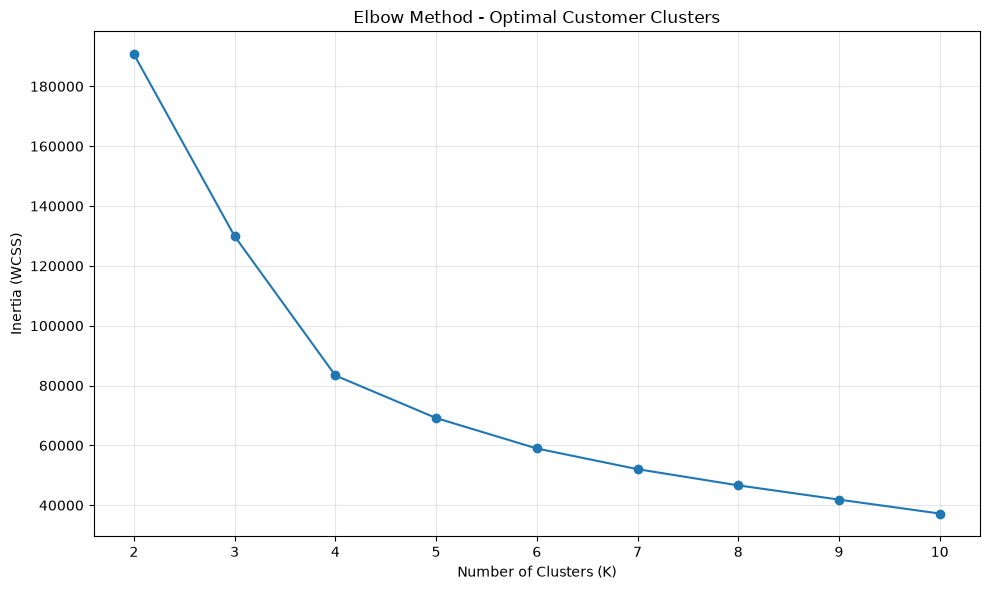

,k,inertia
0,2,190706.440699
1,3,129900.889196
2,4,83368.215511
3,5,69153.699265
4,6,58972.696054
5,7,52060.299711
6,8,46646.788605
7,9,41888.381364
8,10,37232.159076


In [90]:

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia_values = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(scaled_features)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method - Optimal Customer Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

display(
    pd.DataFrame({
        "k": list(k_values),
        "inertia": inertia_values
    })
)


In [91]:

from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
import pandas as pd

silhouette_results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(scaled_features)

    score = silhouette_score(
        scaled_features,
        labels,
        sample_size=10000,
        random_state=42
    )

    silhouette_results.append({
        "clusters": k,
        "silhouette_score": score
    })

silhouette_df = pd.DataFrame(silhouette_results)

display(
    silhouette_df.sort_values(
        "silhouette_score",
        ascending=False
    )
)


,clusters,silhouette_score
0,2,0.712722
1,3,0.417489
2,4,0.392393
4,6,0.350815
3,5,0.350125
5,7,0.346484
8,10,0.345126
7,9,0.340010
6,8,0.337376


In [92]:

# Compare the best silhouette score
best_k = int(
    silhouette_df.loc[
        silhouette_df["silhouette_score"].idxmax(),
        "clusters"
    ]
)

print("Best Silhouette K:", best_k)

# Display corresponding inertia
best_inertia = inertia_values[
    list(k_values).index(best_k)
]

print("Corresponding Inertia:", round(best_inertia, 2))

print("\nCluster evaluation:")
display(
    silhouette_df.sort_values(
        "silhouette_score",
        ascending=False
    )
)


Best Silhouette K: 2
Corresponding Inertia: 190706.44

Cluster evaluation:


,clusters,silhouette_score
0,2,0.712722
1,3,0.417489
2,4,0.392393
4,6,0.350815
3,5,0.350125
5,7,0.346484
8,10,0.345126
7,9,0.340010
6,8,0.337376


In [93]:

from sklearn.cluster import KMeans

# Train final K-Means model
final_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

# Assign customer clusters
ml_customer_df = ml_customer_df.copy()

ml_customer_df["ml_cluster"] = (
    final_kmeans.fit_predict(scaled_features)
)

print("Final K-Means Model Trained!")
print("Selected Clusters:", best_k)

print("\nCustomer Distribution:")
display(
    ml_customer_df["ml_cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("cluster")
    .reset_index(name="customers")
)


Final K-Means Model Trained!
Selected Clusters: 2

Customer Distribution:


,cluster,customers
0,0,2801
1,1,90557


In [94]:

# Profile each ML customer cluster
cluster_profile = (
    ml_customer_df.groupby("ml_cluster")
    .agg(
        total_customers=("frequency", "count"),
        avg_frequency=("frequency", "mean"),
        avg_monetary=("monetary", "mean"),
        avg_recency=("recency_days", "mean"),
        median_monetary=("monetary", "median")
    )
    .reset_index()
)

# Calculate customer percentage
cluster_profile["customer_percentage"] = (
    cluster_profile["total_customers"]
    / len(ml_customer_df) * 100
).round(2)

# Round average metrics
cluster_profile = cluster_profile.round(2)

display(cluster_profile)


,ml_cluster,total_customers,avg_frequency,avg_monetary,avg_recency,median_monetary,customer_percentage
0,0,2801,2.11,260.05,219.29,182.10,3.0
1,1,90557,1.00,137.96,237.49,86.96,97.0


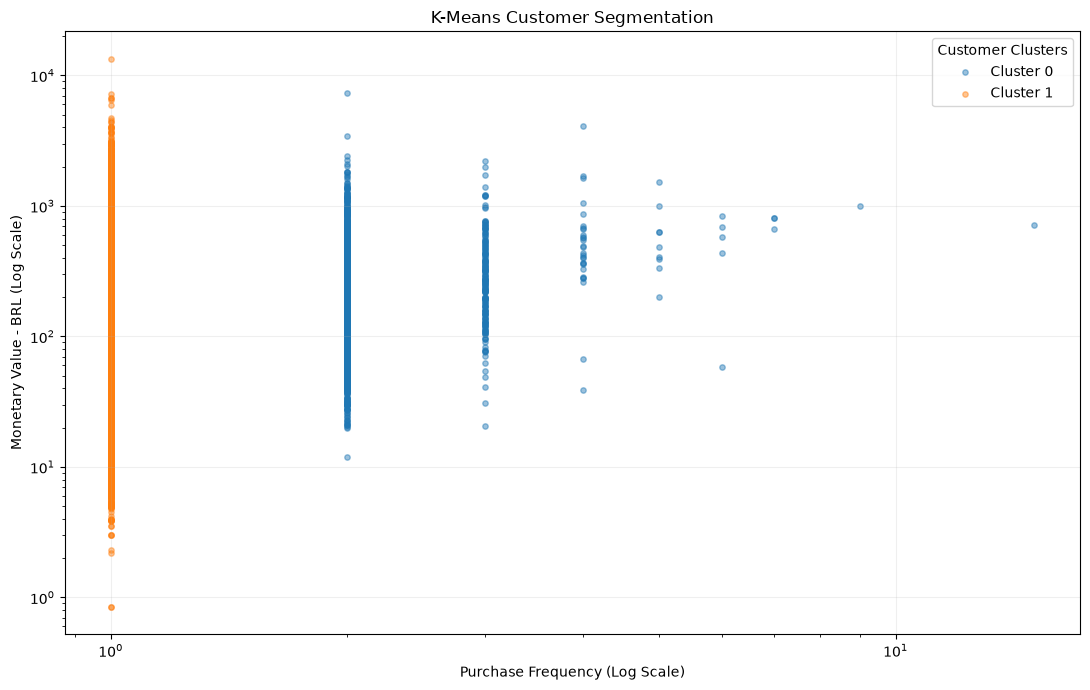

In [95]:

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 7))

for cluster_id in sorted(ml_customer_df["ml_cluster"].unique()):
    cluster_data = ml_customer_df[
        ml_customer_df["ml_cluster"] == cluster_id
    ]

    plt.scatter(
        cluster_data["frequency"],
        cluster_data["monetary"],
        label=f"Cluster {cluster_id}",
        alpha=0.45,
        s=15
    )

plt.xscale("log")
plt.yscale("log")

plt.title("K-Means Customer Segmentation")
plt.xlabel("Purchase Frequency (Log Scale)")
plt.ylabel("Monetary Value - BRL (Log Scale)")

plt.legend(title="Customer Clusters")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [96]:

# Display cluster profiles for business interpretation

display(
    cluster_profile.sort_values(
        "avg_monetary",
        ascending=False
    )
)

print("\nCluster IDs:")
print(sorted(ml_customer_df["ml_cluster"].unique()))

print("\nTotal customers:", len(ml_customer_df))


,ml_cluster,total_customers,avg_frequency,avg_monetary,avg_recency,median_monetary,customer_percentage
0,0,2801,2.11,260.05,219.29,182.10,3.0
1,1,90557,1.00,137.96,237.49,86.96,97.0



Cluster IDs:
[np.int32(0), np.int32(1)]

Total customers: 93358


In [97]:
print("CUSTOMER CLUSTER PROFILE")
print("=" * 50)

display(
    cluster_profile.sort_values(
        "avg_monetary",
        ascending=False
    ).reset_index(drop=True)
)

CUSTOMER CLUSTER PROFILE


,ml_cluster,total_customers,avg_frequency,avg_monetary,avg_recency,median_monetary,customer_percentage
0,0,2801,2.11,260.05,219.29,182.10,3.0
1,1,90557,1.00,137.96,237.49,86.96,97.0


In [98]:

cluster_ranking = cluster_profile.copy()

cluster_ranking["monetary_rank"] = (
    cluster_ranking["avg_monetary"]
    .rank(ascending=False, method="min")
    .astype(int)
)

cluster_ranking["frequency_rank"] = (
    cluster_ranking["avg_frequency"]
    .rank(ascending=False, method="min")
    .astype(int)
)

# Lower recency means more recent purchasing activity
cluster_ranking["recency_rank"] = (
    cluster_ranking["avg_recency"]
    .rank(ascending=True, method="min")
    .astype(int)
)

display(
    cluster_ranking.sort_values("monetary_rank")
)


,ml_cluster,total_customers,avg_frequency,avg_monetary,avg_recency,median_monetary,customer_percentage,monetary_rank,frequency_rank,recency_rank
0,0,2801,2.11,260.05,219.29,182.10,3.0,1,1,1
1,1,90557,1.00,137.96,237.49,86.96,97.0,2,2,2


In [99]:

# Create business labels based on cluster rankings

cluster_labels = {}

for _, row in cluster_ranking.iterrows():
    cluster_id = int(row["ml_cluster"])

    if row["monetary_rank"] == 1 and row["frequency_rank"] == 1:
        label = "High Value Customers"

    elif row["monetary_rank"] == 1:
        label = "Big Spenders"

    elif row["frequency_rank"] == 1:
        label = "Frequent Buyers"

    elif row["recency_rank"] == 1:
        label = "Recently Active Customers"

    elif row["recency_rank"] == len(cluster_ranking):
        label = "Low Engagement Customers"

    else:
        label = "Regular Customers"

    cluster_labels[cluster_id] = label

ml_customer_df["ml_segment"] = (
    ml_customer_df["ml_cluster"].map(cluster_labels)
)

display(
    ml_customer_df[
        ["frequency", "monetary", "recency_days",
         "ml_cluster", "ml_segment"]
    ].head(10)
)

print("Cluster Labels:")
display(cluster_labels)


,frequency,monetary,recency_days,ml_cluster,ml_segment
0,1,129.90,111,1,Low Engagement Customers
1,1,18.90,114,1,Low Engagement Customers
2,1,69.00,536,1,Low Engagement Customers
3,1,25.99,320,1,Low Engagement Customers
4,1,180.00,287,1,Low Engagement Customers
5,1,154.00,145,1,Low Engagement Customers
6,1,27.99,131,1,Low Engagement Customers
7,1,382.00,182,1,Low Engagement Customers
8,1,135.00,542,1,Low Engagement Customers
9,1,104.90,169,1,Low Engagement Customers


Cluster Labels:


{0: 'High Value Customers', 1: 'Low Engagement Customers'}

In [100]:

ml_segment_summary = (
    ml_customer_df.groupby("ml_segment")
    .agg(
        total_customers=("frequency", "count"),
        avg_frequency=("frequency", "mean"),
        avg_monetary=("monetary", "mean"),
        avg_recency=("recency_days", "mean")
    )
    .reset_index()
    .sort_values("total_customers", ascending=False)
)

ml_segment_summary["customer_percentage"] = (
    ml_segment_summary["total_customers"]
    / len(ml_customer_df) * 100
).round(2)

display(ml_segment_summary.round(2))


,ml_segment,total_customers,avg_frequency,avg_monetary,avg_recency,customer_percentage
1,Low Engagement Customers,90557,1.00,137.96,237.49,97.0
0,High Value Customers,2801,2.11,260.05,219.29,3.0


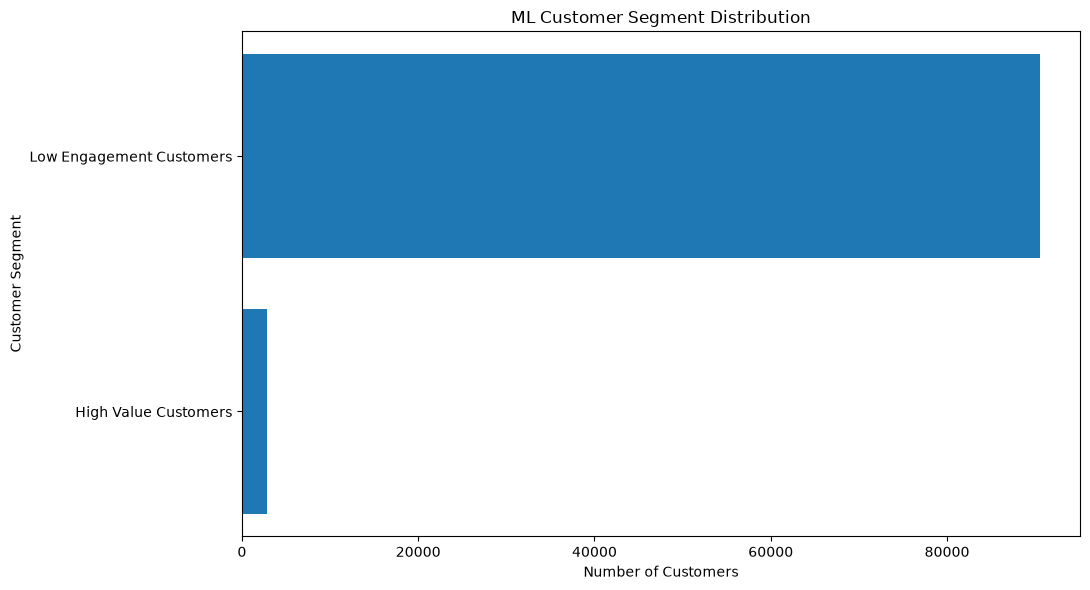

In [101]:

import matplotlib.pyplot as plt

plot_df = ml_segment_summary.sort_values(
    "total_customers"
)

plt.figure(figsize=(11, 6))

plt.barh(
    plot_df["ml_segment"],
    plot_df["total_customers"]
)

plt.title("ML Customer Segment Distribution")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")

plt.tight_layout()
plt.show()


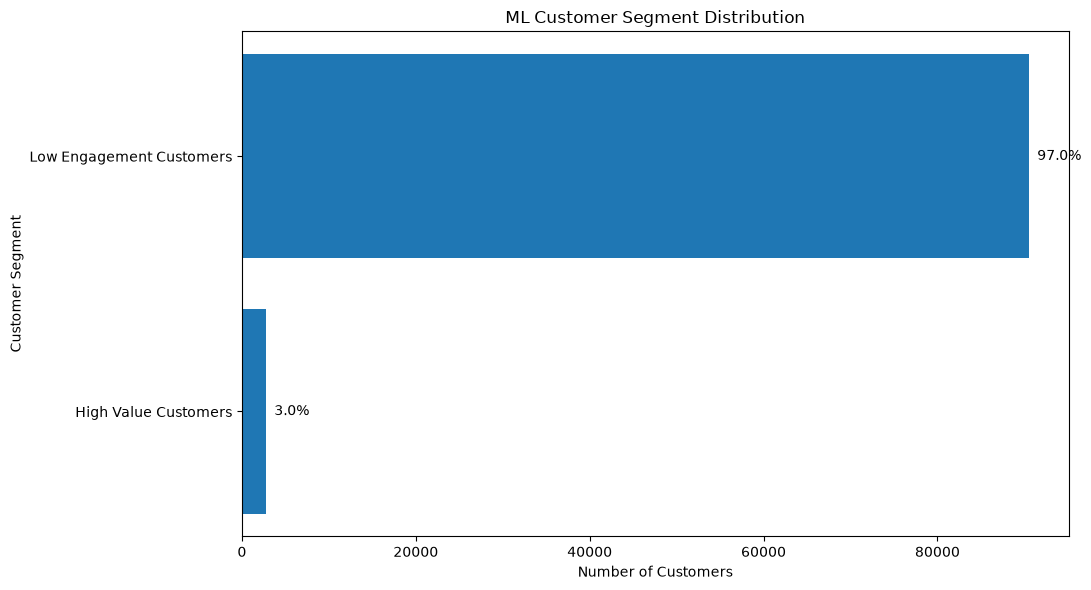

,ml_segment,total_customers,customer_percentage
0,High Value Customers,2801,3.0
1,Low Engagement Customers,90557,97.0


In [102]:

import matplotlib.pyplot as plt

# Create segment summary
ml_segment_summary = (
    ml_customer_df.groupby("ml_segment")
    .agg(
        total_customers=("frequency", "count")
    )
    .reset_index()
    .sort_values("total_customers", ascending=True)
)

# Calculate percentage
ml_segment_summary["customer_percentage"] = (
    ml_segment_summary["total_customers"]
    / ml_segment_summary["total_customers"].sum()
    * 100
).round(2)

# Plot
plt.figure(figsize=(11, 6))

bars = plt.barh(
    ml_segment_summary["ml_segment"],
    ml_segment_summary["total_customers"]
)

plt.title("ML Customer Segment Distribution")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")

for bar, percentage in zip(
    bars, ml_segment_summary["customer_percentage"]
):
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f"  {percentage:.1f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

display(ml_segment_summary)


In [103]:

import os
import pandas as pd

os.makedirs("python/outputs", exist_ok=True)

# Attach customer IDs using the original DataFrame index
ml_export_df = ml_customer_df.copy()

ml_export_df.insert(
    0,
    "customer_unique_id",
    customer_rfm_df.loc[
        ml_export_df.index, "customer_unique_id"
    ]
)

# Export individual customer cluster assignments
ml_export_df.to_csv(
    "python/outputs/ml_customer_segmentation.csv",
    index=False
)

# Export cluster summary
ml_segment_summary.to_csv(
    "python/outputs/ml_customer_segment_summary.csv",
    index=False
)

print("ML segmentation exported successfully!")
print("Customers:", len(ml_export_df))
print("Files:")
print("1. ml_customer_segmentation.csv")
print("2. ml_customer_segment_summary.csv")


ML segmentation exported successfully!
Customers: 93358
Files:
1. ml_customer_segmentation.csv
2. ml_customer_segment_summary.csv


In [104]:

# Load monthly sales data from PostgreSQL

sales_forecast_query = """
SELECT
    sales_month,
    total_orders,
    delivered_orders,
    total_product_revenue,
    total_freight,
    average_order_value
FROM analytics.monthly_sales
ORDER BY sales_month;
"""

sales_forecast_df = pd.read_sql(
    sales_forecast_query,
    engine
)

sales_forecast_df["sales_month"] = pd.to_datetime(
    sales_forecast_df["sales_month"]
)

sales_forecast_df = sales_forecast_df.sort_values(
    "sales_month"
).reset_index(drop=True)

print("Sales Dataset Shape:", sales_forecast_df.shape)
print("\nDate Range:")
print(
    sales_forecast_df["sales_month"].min(),
    "to",
    sales_forecast_df["sales_month"].max()
)

display(sales_forecast_df.head())
display(sales_forecast_df.tail())


Sales Dataset Shape: (25, 6)

Date Range:
2016-09-01 00:00:00 to 2018-10-01 00:00:00


,sales_month,total_orders,delivered_orders,total_product_revenue,total_freight,average_order_value
0,2016-09-01,4,1,267.36,87.39,88.69
1,2016-10-01,324,265,49507.66,7301.18,175.34
2,2016-12-01,1,1,10.90,8.72,19.62
3,2017-01-01,800,750,120312.87,16875.62,171.49
4,2017-02-01,1780,1653,247303.02,38977.60,160.83


,sales_month,total_orders,delivered_orders,total_product_revenue,total_freight,average_order_value
20,2018-06-01,6167,6099,865124.31,157552.80,165.83
21,2018-07-01,6292,6159,895507.22,163220.81,168.27
22,2018-08-01,6512,6351,854686.33,148622.14,154.07
23,2018-09-01,16,0,145.00,21.46,10.40
24,2018-10-01,4,0,0.00,0.00,0.00


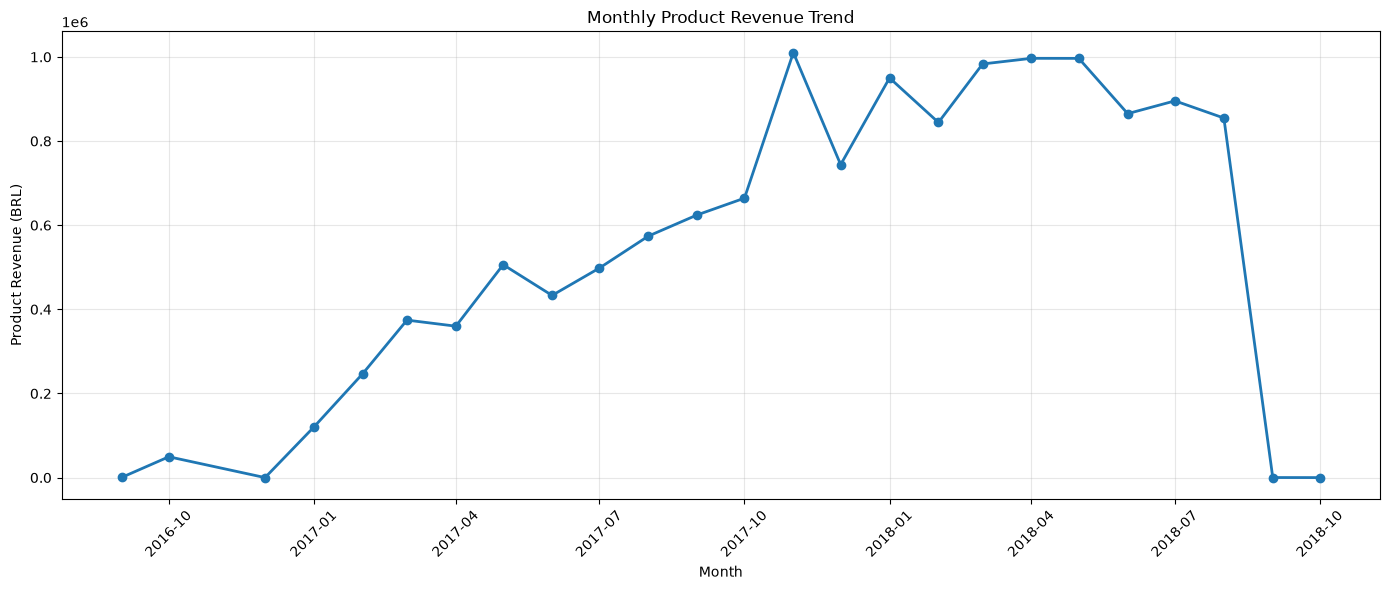

In [105]:

import pandas as pd
import matplotlib.pyplot as plt

# Load data if Step 137 was not executed
if "sales_forecast_df" not in globals():
    sales_forecast_query = """
    SELECT
        sales_month,
        total_orders,
        delivered_orders,
        total_product_revenue,
        total_freight,
        average_order_value
    FROM analytics.monthly_sales
    ORDER BY sales_month;
    """

    sales_forecast_df = pd.read_sql(
        sales_forecast_query, engine
    )

sales_forecast_df["sales_month"] = pd.to_datetime(
    sales_forecast_df["sales_month"]
)

# Monthly sales trend
plt.figure(figsize=(14, 6))

plt.plot(
    sales_forecast_df["sales_month"],
    sales_forecast_df["total_product_revenue"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Product Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Product Revenue (BRL)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [106]:

# Create a copy of monthly sales data
forecast_df = sales_forecast_df.copy()

# Sort chronologically
forecast_df = forecast_df.sort_values(
    "sales_month"
).reset_index(drop=True)

# Time-based features
forecast_df["year"] = forecast_df["sales_month"].dt.year
forecast_df["month"] = forecast_df["sales_month"].dt.month

# Sequential month number
forecast_df["time_index"] = range(len(forecast_df))

# Previous month revenue
forecast_df["lag_1"] = (
    forecast_df["total_product_revenue"].shift(1)
)

# Revenue from two months earlier
forecast_df["lag_2"] = (
    forecast_df["total_product_revenue"].shift(2)
)

# Three-month moving average (previous months only)
forecast_df["rolling_mean_3"] = (
    forecast_df["total_product_revenue"]
    .shift(1)
    .rolling(window=3)
    .mean()
)

display(forecast_df.head(10))


,sales_month,total_orders,delivered_orders,total_product_revenue,total_freight,average_order_value,year,month,time_index,lag_1,lag_2,rolling_mean_3
0,2016-09-01,4,1,267.36,87.39,88.69,2016,9,0,NaN,NaN,NaN
1,2016-10-01,324,265,49507.66,7301.18,175.34,2016,10,1,267.36,NaN,NaN
2,2016-12-01,1,1,10.90,8.72,19.62,2016,12,2,49507.66,267.36,NaN
3,2017-01-01,800,750,120312.87,16875.62,171.49,2017,1,3,10.90,49507.66,16595.306667
4,2017-02-01,1780,1653,247303.02,38977.60,160.83,2017,2,4,120312.87,10.90,56610.476667
5,2017-03-01,2682,2546,374344.30,57704.29,161.09,2017,3,5,247303.02,120312.87,122542.263333
6,2017-04-01,2404,2303,359927.23,52495.01,171.56,2017,4,6,374344.30,247303.02,247320.063333
7,2017-05-01,3700,3546,506071.14,80119.81,158.43,2017,5,7,359927.23,374344.30,327191.516667
8,2017-06-01,3245,3135,433038.60,69924.44,155.00,2017,6,8,506071.14,359927.23,413447.556667
9,2017-07-01,4026,3872,498031.48,86940.14,145.30,2017,7,9,433038.60,506071.14,433012.323333


In [107]:

# Select ML features and target
features = [
    "year",
    "month",
    "time_index",
    "lag_1",
    "lag_2",
    "rolling_mean_3"
]

target = "total_product_revenue"

# Remove rows with missing lag features
model_df = forecast_df.dropna(
    subset=features + [target]
).copy()

X = model_df[features]
y = model_df[target]

print("Original Dataset:", forecast_df.shape)
print("Training Dataset:", model_df.shape)

print("\nFeature Columns:")
print(features)

print("\nTarget Column:", target)

display(model_df.head())


Original Dataset: (25, 12)
Training Dataset: (22, 12)

Feature Columns:
['year', 'month', 'time_index', 'lag_1', 'lag_2', 'rolling_mean_3']

Target Column: total_product_revenue


,sales_month,total_orders,delivered_orders,total_product_revenue,total_freight,average_order_value,year,month,time_index,lag_1,lag_2,rolling_mean_3
3,2017-01-01,800,750,120312.87,16875.62,171.49,2017,1,3,10.90,49507.66,16595.306667
4,2017-02-01,1780,1653,247303.02,38977.60,160.83,2017,2,4,120312.87,10.90,56610.476667
5,2017-03-01,2682,2546,374344.30,57704.29,161.09,2017,3,5,247303.02,120312.87,122542.263333
6,2017-04-01,2404,2303,359927.23,52495.01,171.56,2017,4,6,374344.30,247303.02,247320.063333
7,2017-05-01,3700,3546,506071.14,80119.81,158.43,2017,5,7,359927.23,374344.30,327191.516667


In [108]:

from sklearn.model_selection import train_test_split

# Features and target
features = [
    "year",
    "month",
    "time_index",
    "lag_1",
    "lag_2",
    "rolling_mean_3"
]

target = "total_product_revenue"

# Ensure chronological order
model_df = model_df.sort_values(
    "sales_month"
).reset_index(drop=True)

# Last 4 months reserved for testing
X = model_df[features]
y = model_df[target]

X_train = X.iloc[:-4]
X_test = X.iloc[-4:]

y_train = y.iloc[:-4]
y_test = y.iloc[-4:]

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nTraining Period:")
print(model_df["sales_month"].iloc[0],
      "to",
      model_df["sales_month"].iloc[-5])

print("\nTesting Period:")
print(model_df["sales_month"].iloc[-4],
      "to",
      model_df["sales_month"].iloc[-1])


Training Records: 18
Testing Records: 4

Training Period:
2017-01-01 00:00:00 to 2018-06-01 00:00:00

Testing Period:
2018-07-01 00:00:00 to 2018-10-01 00:00:00


In [109]:

from sklearn.linear_model import LinearRegression

# Initialize model
linear_model = LinearRegression()

# Train model using historical data
linear_model.fit(X_train, y_train)

# Predict test-period revenue
linear_predictions = linear_model.predict(X_test)

print("Linear Regression Model Trained Successfully!")

print("\nActual vs Predicted Revenue:")

comparison_df = model_df.loc[
    X_test.index,
    ["sales_month", "total_product_revenue"]
].copy()

comparison_df["predicted_revenue"] = linear_predictions

display(comparison_df)


Linear Regression Model Trained Successfully!

Actual vs Predicted Revenue:


,sales_month,total_product_revenue,predicted_revenue
18,2018-07-01,895507.22,1.085442e+06
19,2018-08-01,854686.33,1.058614e+06
20,2018-09-01,145.00,1.108094e+06
21,2018-10-01,0.00,1.144183e+06


In [110]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Evaluation metrics
mae = mean_absolute_error(y_test, linear_predictions)

rmse = np.sqrt(
    mean_squared_error(y_test, linear_predictions)
)

mape = np.mean(
    np.abs((y_test - linear_predictions) / y_test)
) * 100

print("LINEAR REGRESSION MODEL PERFORMANCE")
print("-----------------------------------")
print(f"MAE:  R$ {mae:,.2f}")
print(f"RMSE: R$ {rmse:,.2f}")
print(f"MAPE: {mape:.2f}%")


LINEAR REGRESSION MODEL PERFORMANCE
-----------------------------------
MAE:  R$ 661,498.59
RMSE: R$ 808,450.23
MAPE: inf%


In [111]:

from sklearn.ensemble import RandomForestRegressor

# Initialize Random Forest
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=3,
    min_samples_split=3,
    random_state=42
)

# Train model
rf_model.fit(X_train, y_train)

# Predict test data
rf_predictions = rf_model.predict(X_test)

print("Random Forest Model Trained Successfully!")

# Compare actual and predicted revenue
rf_comparison_df = model_df.loc[
    X_test.index,
    ["sales_month", "total_product_revenue"]
].copy()

rf_comparison_df["predicted_revenue"] = rf_predictions

display(rf_comparison_df)


Random Forest Model Trained Successfully!


,sales_month,total_product_revenue,predicted_revenue
18,2018-07-01,895507.22,945398.685313
19,2018-08-01,854686.33,939506.758091
20,2018-09-01,145.00,940463.223475
21,2018-10-01,0.00,777539.001398


In [112]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Evaluation function
def evaluate_model(actual, predicted, model_name):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = np.mean(
        np.abs((actual - predicted) / actual)
    ) * 100

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    }

# Compare both models
model_comparison = pd.DataFrame([
    evaluate_model(y_test, linear_predictions, "Linear Regression"),
    evaluate_model(y_test, rf_predictions, "Random Forest")
])

display(
    model_comparison.style.format({
        "MAE": "R$ {:,.2f}",
        "RMSE": "R$ {:,.2f}",
        "MAPE (%)": "{:.2f}%"
    })
)


,Model,MAE,RMSE,MAPE (%)
0,Linear Regression,"R$ 661,498.59","R$ 808,450.23",inf%
1,Random Forest,"R$ 463,142.28","R$ 612,055.74",inf%


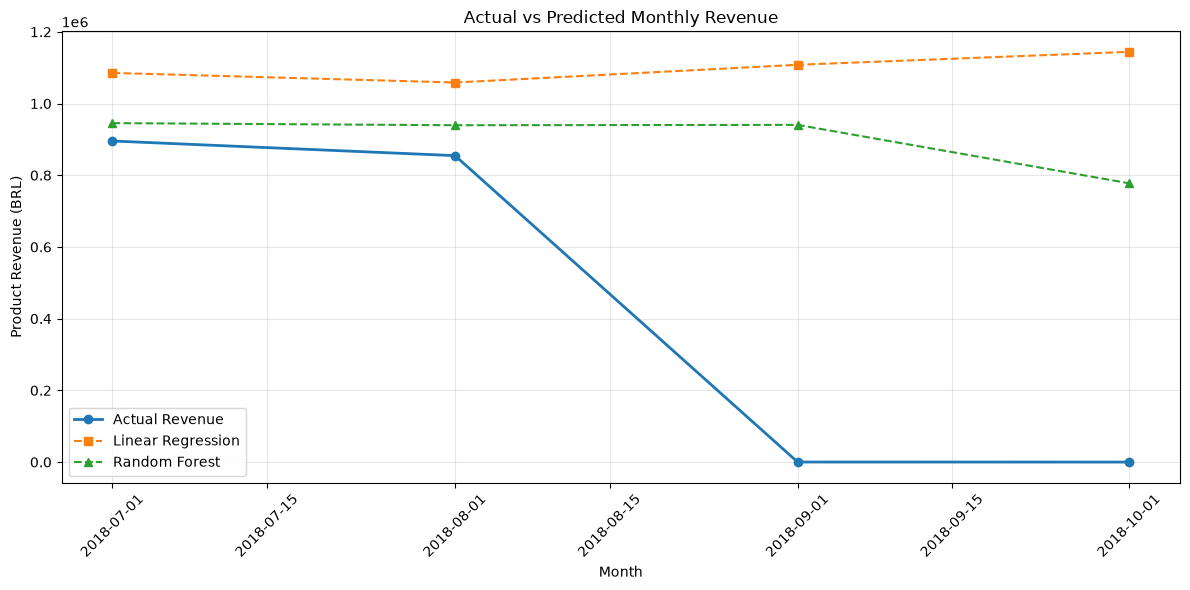

In [113]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    comparison_df["sales_month"],
    y_test.values,
    marker="o",
    linewidth=2,
    label="Actual Revenue"
)

plt.plot(
    comparison_df["sales_month"],
    linear_predictions,
    marker="s",
    linestyle="--",
    label="Linear Regression"
)

plt.plot(
    comparison_df["sales_month"],
    rf_predictions,
    marker="^",
    linestyle="--",
    label="Random Forest"
)

plt.title("Actual vs Predicted Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Product Revenue (BRL)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [114]:

# Inspect the latest months in the original sales dataset

display(
    sales_forecast_df[
        [
            "sales_month",
            "total_orders",
            "delivered_orders",
            "total_product_revenue"
        ]
    ].tail(8)
)


,sales_month,total_orders,delivered_orders,total_product_revenue
17,2018-03-01,7211,7003,983213.44
18,2018-04-01,6939,6798,996647.75
19,2018-05-01,6873,6749,996517.68
20,2018-06-01,6167,6099,865124.31
21,2018-07-01,6292,6159,895507.22
22,2018-08-01,6512,6351,854686.33
23,2018-09-01,16,0,145.00
24,2018-10-01,4,0,0.00


In [115]:

# Keep complete months only, through August 2018
complete_sales_df = sales_forecast_df[
    sales_forecast_df["sales_month"] < "2018-09-01"
].copy()

complete_sales_df = complete_sales_df.sort_values(
    "sales_month"
).reset_index(drop=True)

print("Complete monthly records:", len(complete_sales_df))

print("\nLatest complete months:")
display(
    complete_sales_df[
        ["sales_month", "total_orders", "delivered_orders",
         "total_product_revenue"]
    ].tail(5)
)


Complete monthly records: 23

Latest complete months:


,sales_month,total_orders,delivered_orders,total_product_revenue
18,2018-04-01,6939,6798,996647.75
19,2018-05-01,6873,6749,996517.68
20,2018-06-01,6167,6099,865124.31
21,2018-07-01,6292,6159,895507.22
22,2018-08-01,6512,6351,854686.33


In [116]:

forecast_clean_df = complete_sales_df.copy()

forecast_clean_df = forecast_clean_df.sort_values(
    "sales_month"
).reset_index(drop=True)

# Time-based features
forecast_clean_df["year"] = forecast_clean_df["sales_month"].dt.year
forecast_clean_df["month"] = forecast_clean_df["sales_month"].dt.month
forecast_clean_df["time_index"] = range(len(forecast_clean_df))

# Historical revenue features
forecast_clean_df["lag_1"] = forecast_clean_df["total_product_revenue"].shift(1)
forecast_clean_df["lag_2"] = forecast_clean_df["total_product_revenue"].shift(2)

forecast_clean_df["rolling_mean_3"] = (
    forecast_clean_df["total_product_revenue"]
    .shift(1)
    .rolling(3)
    .mean()
)

# Remove rows with missing lag values
model_clean_df = forecast_clean_df.dropna().copy()

print("Complete monthly records:", len(forecast_clean_df))
print("Usable forecasting records:", len(model_clean_df))

display(model_clean_df.head())


Complete monthly records: 23
Usable forecasting records: 20


,sales_month,total_orders,delivered_orders,total_product_revenue,total_freight,average_order_value,year,month,time_index,lag_1,lag_2,rolling_mean_3
3,2017-01-01,800,750,120312.87,16875.62,171.49,2017,1,3,10.90,49507.66,16595.306667
4,2017-02-01,1780,1653,247303.02,38977.60,160.83,2017,2,4,120312.87,10.90,56610.476667
5,2017-03-01,2682,2546,374344.30,57704.29,161.09,2017,3,5,247303.02,120312.87,122542.263333
6,2017-04-01,2404,2303,359927.23,52495.01,171.56,2017,4,6,374344.30,247303.02,247320.063333
7,2017-05-01,3700,3546,506071.14,80119.81,158.43,2017,5,7,359927.23,374344.30,327191.516667


In [117]:

features = [
    "year",
    "month",
    "time_index",
    "lag_1",
    "lag_2",
    "rolling_mean_3"
]

target = "total_product_revenue"

model_clean_df = model_clean_df.sort_values(
    "sales_month"
).reset_index(drop=True)

X_clean = model_clean_df[features]
y_clean = model_clean_df[target]

# Last 4 complete months for testing
X_train_clean = X_clean.iloc[:-4]
X_test_clean = X_clean.iloc[-4:]

y_train_clean = y_clean.iloc[:-4]
y_test_clean = y_clean.iloc[-4:]

print("Training records:", len(X_train_clean))
print("Testing records:", len(X_test_clean))

print("\nTraining period:")
print(model_clean_df["sales_month"].iloc[0],
      "to",
      model_clean_df["sales_month"].iloc[-5])

print("\nTesting period:")
print(model_clean_df["sales_month"].iloc[-4],
      "to",
      model_clean_df["sales_month"].iloc[-1])


Training records: 16
Testing records: 4

Training period:
2017-01-01 00:00:00 to 2018-04-01 00:00:00

Testing period:
2018-05-01 00:00:00 to 2018-08-01 00:00:00


In [118]:

from sklearn.linear_model import LinearRegression

# Initialize model
linear_clean_model = LinearRegression()

# Train using complete months only
linear_clean_model.fit(X_train_clean, y_train_clean)

# Predict test period
linear_clean_predictions = linear_clean_model.predict(X_test_clean)

print("Clean Linear Regression Model Trained!")

# Actual vs predicted comparison
clean_comparison_df = model_clean_df.loc[
    X_test_clean.index,
    ["sales_month", "total_product_revenue"]
].copy()

clean_comparison_df["predicted_revenue"] = linear_clean_predictions

display(clean_comparison_df)


Clean Linear Regression Model Trained!


,sales_month,total_product_revenue,predicted_revenue
16,2018-05-01,996517.68,1.136022e+06
17,2018-06-01,865124.31,1.191385e+06
18,2018-07-01,895507.22,1.311693e+06
19,2018-08-01,854686.33,1.366653e+06


In [119]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

clean_mae = mean_absolute_error(
    y_test_clean, linear_clean_predictions
)

clean_rmse = np.sqrt(
    mean_squared_error(y_test_clean, linear_clean_predictions)
)

clean_mape = np.mean(
    np.abs(
        (y_test_clean - linear_clean_predictions) / y_test_clean
    )
) * 100

print("CLEAN LINEAR REGRESSION PERFORMANCE")
print("-----------------------------------")
print(f"MAE:  R$ {clean_mae:,.2f}")
print(f"RMSE: R$ {clean_rmse:,.2f}")
print(f"MAPE: {clean_mape:.2f}%")


CLEAN LINEAR REGRESSION PERFORMANCE
-----------------------------------
MAE:  R$ 348,479.44
RMSE: R$ 374,575.75
MAPE: 39.52%


In [120]:

from sklearn.ensemble import RandomForestRegressor

# Initialize Random Forest
rf_clean_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=3,
    min_samples_split=3,
    random_state=42
)

# Train model
rf_clean_model.fit(X_train_clean, y_train_clean)

# Predict test data
rf_clean_predictions = rf_clean_model.predict(X_test_clean)

print("Clean Random Forest Model Trained!")

# Compare actual vs predicted
rf_clean_comparison_df = model_clean_df.loc[
    X_test_clean.index,
    ["sales_month", "total_product_revenue"]
].copy()

rf_clean_comparison_df["predicted_revenue"] = rf_clean_predictions

display(rf_clean_comparison_df)


Clean Random Forest Model Trained!


,sales_month,total_product_revenue,predicted_revenue
16,2018-05-01,996517.68,931104.931439
17,2018-06-01,865124.31,931104.931439
18,2018-07-01,895507.22,947097.574700
19,2018-08-01,854686.33,953836.334818


In [121]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

def evaluate_clean_model(actual, predicted, name):
    return {
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE (%)": np.mean(
            np.abs((actual - predicted) / actual)
        ) * 100
    }

clean_model_comparison = pd.DataFrame([
    evaluate_clean_model(
        y_test_clean,
        linear_clean_predictions,
        "Linear Regression"
    ),
    evaluate_clean_model(
        y_test_clean,
        rf_clean_predictions,
        "Random Forest"
    )
])

display(
    clean_model_comparison.style.format({
        "MAE": "R$ {:,.2f}",
        "RMSE": "R$ {:,.2f}",
        "MAPE (%)": "{:.2f}%"
    })
)


,Model,MAE,RMSE,MAPE (%)
0,Linear Regression,"R$ 348,479.44","R$ 374,575.75",39.52%
1,Random Forest,"R$ 70,533.43","R$ 72,671.45",7.89%


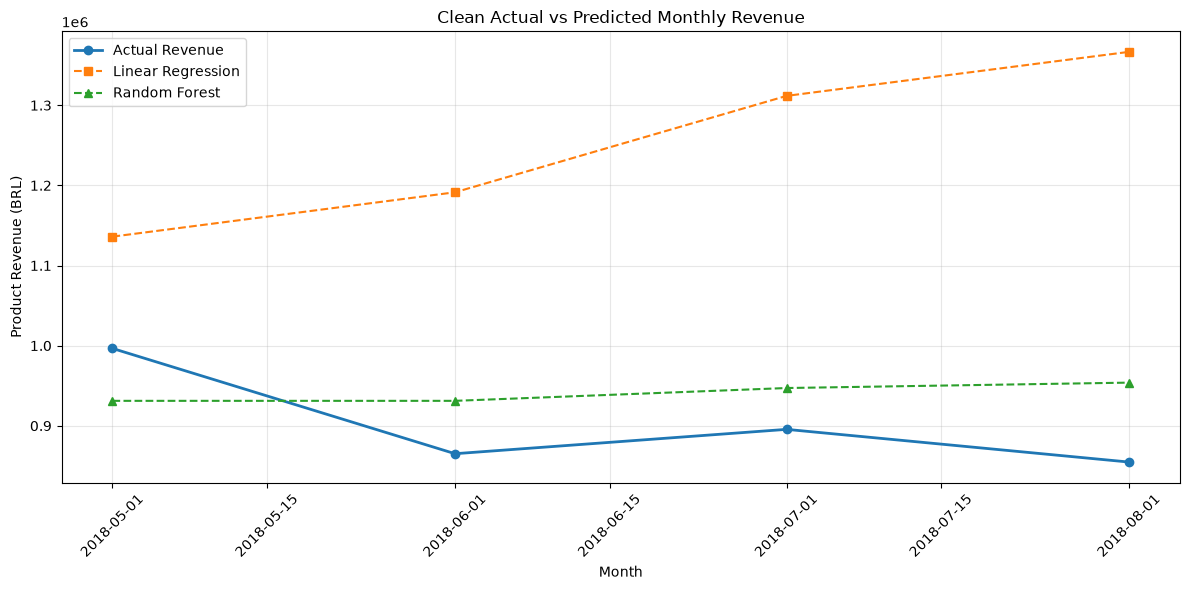

In [122]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    model_clean_df.loc[X_test_clean.index, "sales_month"],
    y_test_clean.values,
    marker="o",
    linewidth=2,
    label="Actual Revenue"
)

plt.plot(
    model_clean_df.loc[X_test_clean.index, "sales_month"],
    linear_clean_predictions,
    marker="s",
    linestyle="--",
    label="Linear Regression"
)

plt.plot(
    model_clean_df.loc[X_test_clean.index, "sales_month"],
    rf_clean_predictions,
    marker="^",
    linestyle="--",
    label="Random Forest"
)

plt.title("Clean Actual vs Predicted Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Product Revenue (BRL)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [123]:

# Create final forecasting results
forecast_results_df = model_clean_df.loc[
    X_test_clean.index,
    ["sales_month", "total_product_revenue"]
].copy()

forecast_results_df["linear_regression_prediction"] = (
    linear_clean_predictions
)

forecast_results_df["random_forest_prediction"] = (
    rf_clean_predictions
)

forecast_results_df["rf_prediction_error"] = (
    forecast_results_df["total_product_revenue"]
    - forecast_results_df["random_forest_prediction"]
)

# Export CSV
forecast_results_df.to_csv(
    "python/outputs/sales_forecast_model_results.csv",
    index=False
)

print("Forecast results exported successfully!")
print("File: python/outputs/sales_forecast_model_results.csv")

display(forecast_results_df)


Forecast results exported successfully!
File: python/outputs/sales_forecast_model_results.csv


,sales_month,total_product_revenue,linear_regression_prediction,random_forest_prediction,rf_prediction_error
16,2018-05-01,996517.68,1.136022e+06,931104.931439,65412.748561
17,2018-06-01,865124.31,1.191385e+06,931104.931439,-65980.621439
18,2018-07-01,895507.22,1.311693e+06,947097.574700,-51590.354700
19,2018-08-01,854686.33,1.366653e+06,953836.334818,-99150.004818


In [124]:

# Save model comparison metrics
clean_model_comparison.to_csv(
    "python/outputs/sales_forecast_model_comparison.csv",
    index=False
)

print("Model comparison exported successfully!")
print("File: python/outputs/sales_forecast_model_comparison.csv")

display(clean_model_comparison)


Model comparison exported successfully!
File: python/outputs/sales_forecast_model_comparison.csv


,Model,MAE,RMSE,MAPE (%)
0,Linear Regression,348479.435894,374575.750339,39.521943
1,Random Forest,70533.432379,72671.449403,7.888156


In [125]:

# Forecasting business insights

best_model_row = clean_model_comparison.loc[
    clean_model_comparison["MAPE (%)"].idxmin()
]

print("SALES FORECASTING BUSINESS INSIGHTS")
print("-----------------------------------")

print(f"Best Model: {best_model_row['Model']}")
print(f"MAPE: {best_model_row['MAPE (%)']:.2f}%")
print(f"MAE: R$ {best_model_row['MAE']:,.2f}")
print(f"RMSE: R$ {best_model_row['RMSE']:,.2f}")

print("\nKey Findings:")
print("1. Random Forest outperformed Linear Regression on the test period.")
print("2. September and October 2018 were excluded as incomplete months.")
print("3. Only four months were used for final testing.")
print("4. More historical data and rolling validation are needed")
print("   before using forecasts for business decisions.")


SALES FORECASTING BUSINESS INSIGHTS
-----------------------------------
Best Model: Random Forest
MAPE: 7.89%
MAE: R$ 70,533.43
RMSE: R$ 72,671.45

Key Findings:
1. Random Forest outperformed Linear Regression on the test period.
2. September and October 2018 were excluded as incomplete months.
3. Only four months were used for final testing.
4. More historical data and rolling validation are needed
   before using forecasts for business decisions.


In [126]:

forecast_insights = pd.DataFrame({
    "insight": [
        "Random Forest outperformed Linear Regression on the test period.",
        "September and October 2018 were excluded as incomplete months.",
        "Only four months were used for final testing.",
        "More historical data and rolling validation are needed before business use."
    ]
})

forecast_insights.to_csv(
    "python/outputs/sales_forecast_business_insights.csv",
    index=False
)

print("Business insights exported successfully!")
print("File: python/outputs/sales_forecast_business_insights.csv")

display(forecast_insights)


Business insights exported successfully!
File: python/outputs/sales_forecast_business_insights.csv


,insight
0,Random Forest outperformed Linear Regression o...
1,September and October 2018 were excluded as in...
2,Only four months were used for final testing.
3,More historical data and rolling validation ar...


In [127]:

from pathlib import Path

output_dir = Path("python/outputs")

print("PROJECT OUTPUT FILES")
print("--------------------")

for file in sorted(output_dir.glob("*")):
    if file.is_file():
        print(f"{file.name} | {file.stat().st_size:,} bytes")



PROJECT OUTPUT FILES
--------------------
city_sales_analysis.csv | 139,731 bytes
customer_rfm_analysis.csv | 10,515,662 bytes
customer_segment_summary.csv | 435 bytes
customer_sentiment_summary.csv | 139 bytes
delivery_summary.csv | 162 bytes
freight_cost_analysis.csv | 147 bytes
ml_customer_segment_summary.csv | 113 bytes
ml_customer_segmentation.csv | 6,663,643 bytes
monthly_customer_retention.csv | 600 bytes
monthly_delivery_analysis.csv | 846 bytes
payment_installment_analysis.csv | 887 bytes
payment_method_analysis.csv | 309 bytes
review_delivery_analysis.csv | 130 bytes
sales_forecast_business_insights.csv | 258 bytes
sales_forecast_model_comparison.csv | 163 bytes
sales_forecast_model_results.csv | 414 bytes
seller_performance_scorecard.csv | 247,227 bytes
state_sales_analysis.csv | 849 bytes
top_10_cities.csv | 671 bytes


In [128]:

from pathlib import Path

project_dir = Path.cwd()

# Create Streamlit application folders
folders = [
    "streamlit_app",
    "streamlit_app/pages",
    "streamlit_app/components",
    "streamlit_app/assets"
]

for folder in folders:
    (project_dir / folder).mkdir(parents=True, exist_ok=True)

# Create main application file if it doesn't exist
app_file = project_dir / "app.py"

if not app_file.exists():
    app_file.write_text("", encoding="utf-8")

print("STREAMLIT PROJECT STRUCTURE")
print("---------------------------")

for folder in folders:
    print(f"Created/verified: {folder}")

print("app.py:", "Exists" if app_file.exists() else "Missing")
print("Project location:", project_dir)


STREAMLIT PROJECT STRUCTURE
---------------------------
Created/verified: streamlit_app
Created/verified: streamlit_app/pages
Created/verified: streamlit_app/components
Created/verified: streamlit_app/assets
app.py: Exists
Project location: /Users/animeshjain/ecommerce-intelligence-analytics


In [129]:

%pip install streamlit

Note: you may need to restart the kernel to use updated packages.


In [130]:
import streamlit as st

print("Streamlit version:", st.__version__)
print("Streamlit installation: Successful")

Streamlit version: 1.67.0
Streamlit installation: Successful


In [131]:

%pip install psycopg2-binary


Note: you may need to restart the kernel to use updated packages.


In [132]:

import psycopg2

# Connect to PostgreSQL
conn = psycopg2.connect(
    host="localhost",
    port=5432,
    database="ecommerce_analytics",
    user="postgres",
    password=input("Enter PostgreSQL password: ")
)

print("PostgreSQL connection successful!")

# Load executive KPIs
executive_kpis_df = pd.read_sql(
    "SELECT * FROM analytics.executive_kpis",
    conn
)

display(executive_kpis_df)

conn.close()


Enter PostgreSQL password:  A250904a


PostgreSQL connection successful!


/var/folders/y9/wrynjjb10td2_6pm041jbm2w0000gn/T/ipykernel_1392/4244266778.py:15: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  executive_kpis_df = pd.read_sql(


,total_orders,delivered_orders,canceled_orders,total_product_revenue,delivered_product_revenue,total_freight,average_order_value,total_customers,total_products,total_sellers,total_reviews,average_review_score,orders_with_delivery_comparison,on_time_orders,on_time_delivery_percentage
0,99441,96478,625,13591643.7,13221498.11,2251909.54,159.33,93358,32951,3095,99224,4.09,96476,88649,91.89


In [133]:
from streamlit_app.db import get_engine
import pandas as pd

engine = get_engine()

executive_kpis_df = pd.read_sql_query(
    "SELECT * FROM analytics.executive_kpis",
    engine
)

print("Executive KPIs loaded successfully!")
display(executive_kpis_df)

2026-11-17 16:30:16.724 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


Executive KPIs loaded successfully!


,total_orders,delivered_orders,canceled_orders,total_product_revenue,delivered_product_revenue,total_freight,average_order_value,total_customers,total_products,total_sellers,total_reviews,average_review_score,orders_with_delivery_comparison,on_time_orders,on_time_delivery_percentage
0,99441,96478,625,13591643.7,13221498.11,2251909.54,159.33,93358,32951,3095,99224,4.09,96476,88649,91.89


In [134]:
# Check missing values in the KPI result
print("KPI NULL VALUE CHECK")
print("--------------------")
print(executive_kpis_df.isnull().sum())
print("\nFULL KPI VALUES")
print("---------------")
display(executive_kpis_df.T)

KPI NULL VALUE CHECK
--------------------
total_orders                       0
delivered_orders                   0
canceled_orders                    0
total_product_revenue              0
delivered_product_revenue          0
total_freight                      0
average_order_value                0
total_customers                    0
total_products                     0
total_sellers                      0
total_reviews                      0
average_review_score               0
orders_with_delivery_comparison    0
on_time_orders                     0
on_time_delivery_percentage        0
dtype: int64

FULL KPI VALUES
---------------


,0
total_orders,99441.00
delivered_orders,96478.00
canceled_orders,625.00
total_product_revenue,13591643.70
delivered_product_revenue,13221498.11
total_freight,2251909.54
average_order_value,159.33
total_customers,93358.00
total_products,32951.00
total_sellers,3095.00


In [135]:
import sqlalchemy
print("SQLAlchemy version:", sqlalchemy.__version__)
print("SQLAlchemy installed successfully!")

SQLAlchemy version: 2.1.8
SQLAlchemy installed successfully!


In [136]:
# Display all Executive KPI values clearly

for column in executive_kpis_df.columns:
    print(f"{column}: {executive_kpis_df[column].iloc[0]}")

total_orders: 99441
delivered_orders: 96478
canceled_orders: 625
total_product_revenue: 13591643.7
delivered_product_revenue: 13221498.11
total_freight: 2251909.54
average_order_value: 159.33
total_customers: 93358
total_products: 32951
total_sellers: 3095
total_reviews: 99224
average_review_score: 4.09
orders_with_delivery_comparison: 96476
on_time_orders: 88649
on_time_delivery_percentage: 91.89


In [137]:
# Executive Business Performance Analysis

kpi = executive_kpis_df.iloc[0]

# Calculate business metrics
delivery_rate = (
    kpi["delivered_orders"] / kpi["total_orders"]
) * 100

cancellation_rate = (
    kpi["canceled_orders"] / kpi["total_orders"]
) * 100

delivered_revenue_share = (
    kpi["delivered_product_revenue"] /
    kpi["total_product_revenue"]
) * 100

freight_to_revenue = (
    kpi["total_freight"] /
    kpi["total_product_revenue"]
) * 100

# Display insights
print("===== EXECUTIVE BUSINESS INSIGHTS =====")

print(f"Delivery Rate: {delivery_rate:.2f}%")
print(f"Cancellation Rate: {cancellation_rate:.2f}%")
print(f"Delivered Revenue Share: {delivered_revenue_share:.2f}%")
print(f"Freight to Product Revenue: {freight_to_revenue:.2f}%")

print(f"Average Order Value: R$ {kpi['average_order_value']:,.2f}")
print(f"Customer Review Score: {kpi['average_review_score']}/5")
print(f"On-Time Delivery: {kpi['on_time_delivery_percentage']}%")

===== EXECUTIVE BUSINESS INSIGHTS =====
Delivery Rate: 97.02%
Cancellation Rate: 0.63%
Delivered Revenue Share: 97.28%
Freight to Product Revenue: 16.57%
Average Order Value: R$ 159.33
Customer Review Score: 4.09/5
On-Time Delivery: 91.89%


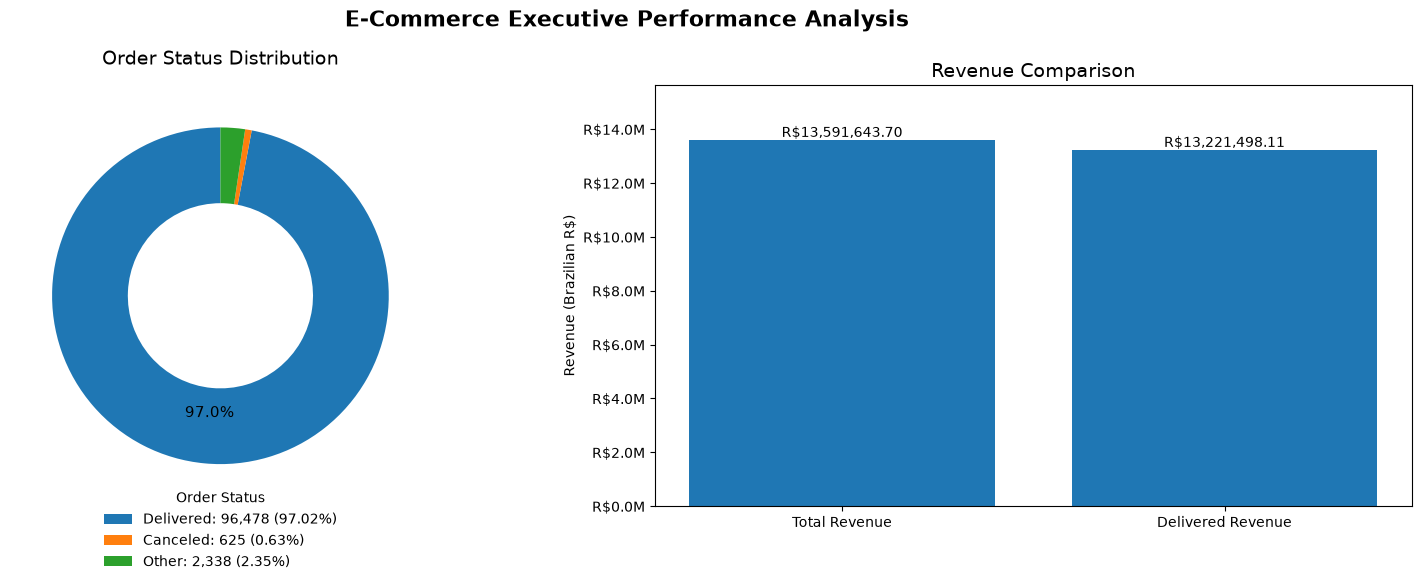

In [138]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

kpi = executive_kpis_df.iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# -----------------------------
# CHART 1: ORDER STATUS
# -----------------------------

order_labels = ["Delivered", "Canceled", "Other"]

order_values = [
    int(kpi["delivered_orders"]),
    int(kpi["canceled_orders"]),
    int(kpi["total_orders"] - kpi["delivered_orders"] - kpi["canceled_orders"])
]

total_orders = sum(order_values)

legend_labels = [
    f"{label}: {value:,} ({value / total_orders * 100:.2f}%)"
    for label, value in zip(order_labels, order_values)
]

wedges, texts, autotexts = axes[0].pie(
    order_values,
    labels=None,
    autopct=lambda p: f"{p:.1f}%" if p >= 5 else "",
    startangle=90,
    pctdistance=0.70,
    wedgeprops={"width": 0.45},
    textprops={"fontsize": 11}
)

axes[0].legend(
    wedges,
    legend_labels,
    title="Order Status",
    loc="lower center",
    bbox_to_anchor=(0.5, -0.18),
    frameon=False
)

axes[0].set_title("Order Status Distribution", fontsize=14, pad=15)

# -----------------------------
# CHART 2: REVENUE COMPARISON
# -----------------------------

revenue_labels = ["Total Revenue", "Delivered Revenue"]

revenue_values = [
    float(kpi["total_product_revenue"]),
    float(kpi["delivered_product_revenue"])
]

bars = axes[1].bar(revenue_labels, revenue_values)

axes[1].set_title("Revenue Comparison", fontsize=14)
axes[1].set_ylabel("Revenue (Brazilian R$)")

# Format Y-axis in millions
axes[1].yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"R${x/1_000_000:.1f}M")
)

# Add exact values above bars
for bar, value in zip(bars, revenue_values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"R${value:,.2f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

axes[1].set_ylim(0, max(revenue_values) * 1.15)

plt.suptitle(
    "E-Commerce Executive Performance Analysis",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [139]:
# Load monthly sales data from PostgreSQL

monthly_sales_df = pd.read_sql_query(
    """
    SELECT *
    FROM analytics.monthly_sales
    ORDER BY sales_month;
    """,
    engine
)

print("Monthly sales data loaded successfully!")
print("Dataset Shape:", monthly_sales_df.shape)

display(monthly_sales_df.head(10))

Monthly sales data loaded successfully!
Dataset Shape: (25, 7)


,sales_month,total_orders,delivered_orders,canceled_orders,total_product_revenue,total_freight,average_order_value
0,2016-09-01,4,1,2,267.36,87.39,88.69
1,2016-10-01,324,265,24,49507.66,7301.18,175.34
2,2016-12-01,1,1,0,10.90,8.72,19.62
3,2017-01-01,800,750,3,120312.87,16875.62,171.49
4,2017-02-01,1780,1653,17,247303.02,38977.60,160.83
5,2017-03-01,2682,2546,33,374344.30,57704.29,161.09
6,2017-04-01,2404,2303,18,359927.23,52495.01,171.56
7,2017-05-01,3700,3546,29,506071.14,80119.81,158.43
8,2017-06-01,3245,3135,16,433038.60,69924.44,155.00
9,2017-07-01,4026,3872,28,498031.48,86940.14,145.30


In [140]:
print("===== MONTHLY SALES DATA INFORMATION =====")

monthly_sales_df.info()

print("\n===== MISSING VALUES =====")
print(monthly_sales_df.isnull().sum())

print("\n===== DATE RANGE =====")
print("Start:", monthly_sales_df["sales_month"].min())
print("End:", monthly_sales_df["sales_month"].max())

===== MONTHLY SALES DATA INFORMATION =====
<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   sales_month            25 non-null     object 
 1   total_orders           25 non-null     int64  
 2   delivered_orders       25 non-null     int64  
 3   canceled_orders        25 non-null     int64  
 4   total_product_revenue  25 non-null     float64
 5   total_freight          25 non-null     float64
 6   average_order_value    25 non-null     float64
dtypes: float64(3), int64(3), object(1)
memory usage: 1.5+ KB

===== MISSING VALUES =====
sales_month              0
total_orders             0
delivered_orders         0
canceled_orders          0
total_product_revenue    0
total_freight            0
average_order_value      0
dtype: int64

===== DATE RANGE =====
Start: 2016-09-01
End: 2018-10-01


In [141]:
# Convert sales_month into datetime
monthly_sales_df["sales_month"] = pd.to_datetime(
    monthly_sales_df["sales_month"]
)

# Exclude incomplete months: September and October 2018
monthly_sales_clean = monthly_sales_df[
    monthly_sales_df["sales_month"] < "2018-09-01"
].copy()

# Sort data by month
monthly_sales_clean = monthly_sales_clean.sort_values(
    "sales_month"
).reset_index(drop=True)

print("Monthly sales data prepared successfully!")

print("Original rows:", len(monthly_sales_df))
print("Clean rows:", len(monthly_sales_clean))

display(monthly_sales_clean.tail(5))

Monthly sales data prepared successfully!
Original rows: 25
Clean rows: 23


,sales_month,total_orders,delivered_orders,canceled_orders,total_product_revenue,total_freight,average_order_value
18,2018-04-01,6939,6798,15,996647.75,163050.29,167.13
19,2018-05-01,6873,6749,24,996517.68,153264.14,167.29
20,2018-06-01,6167,6099,18,865124.31,157552.80,165.83
21,2018-07-01,6292,6159,41,895507.22,163220.81,168.27
22,2018-08-01,6512,6351,84,854686.33,148622.14,154.07


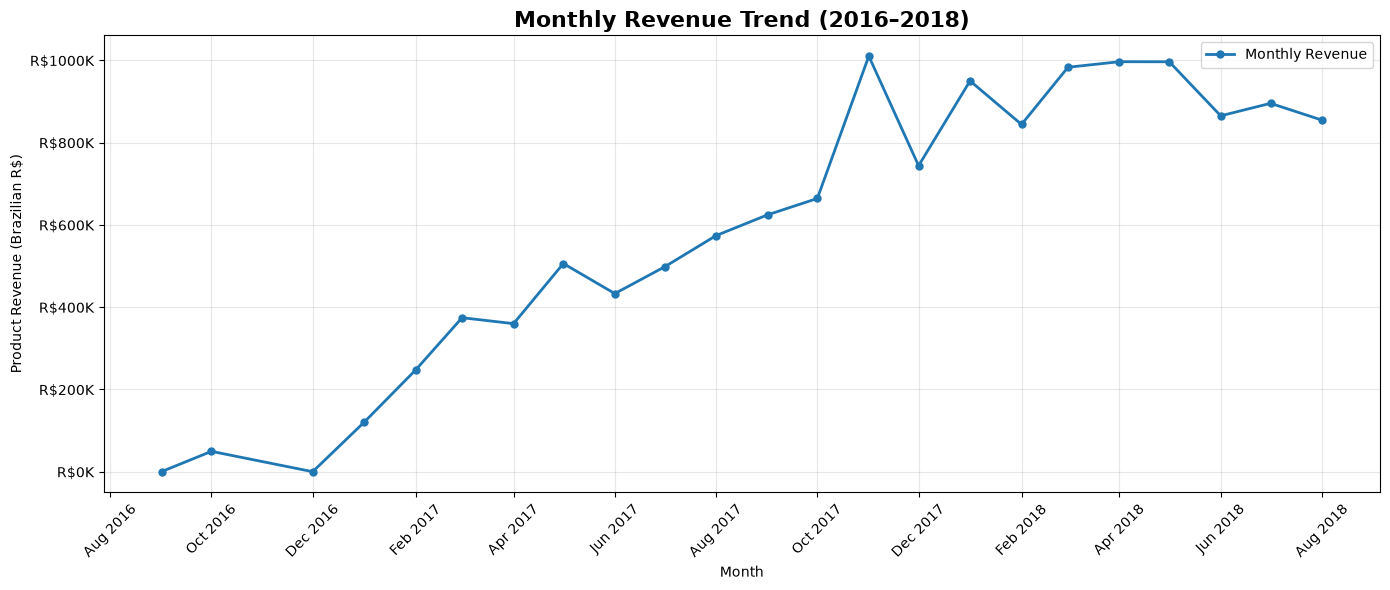

In [142]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    monthly_sales_clean["sales_month"],
    monthly_sales_clean["total_product_revenue"],
    marker="o",
    linewidth=2,
    markersize=5,
    label="Monthly Revenue"
)

ax.set_title(
    "Monthly Revenue Trend (2016–2018)",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Month")
ax.set_ylabel("Product Revenue (Brazilian R$)")

# Format Y-axis in thousands
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"R${x/1000:.0f}K")
)

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

plt.xticks(rotation=45)
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

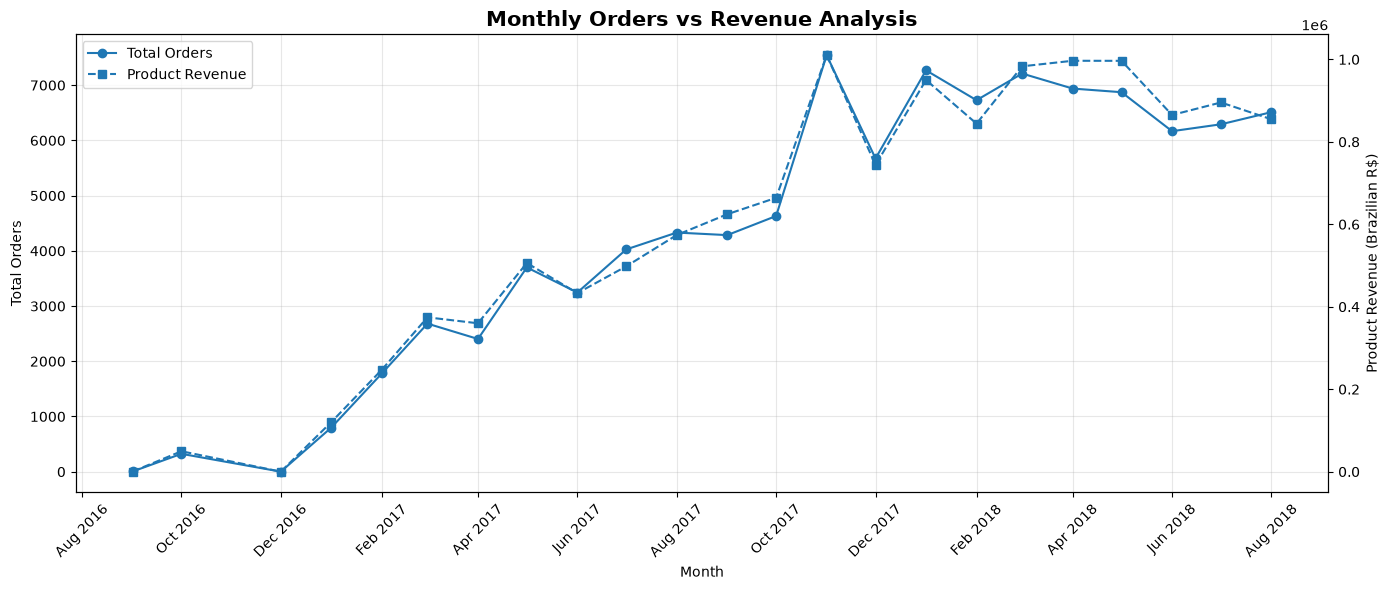

In [143]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, ax1 = plt.subplots(figsize=(14, 6))

# Orders line
ax1.plot(
    monthly_sales_clean["sales_month"],
    monthly_sales_clean["total_orders"],
    marker="o",
    label="Total Orders"
)

ax1.set_xlabel("Month")
ax1.set_ylabel("Total Orders")

# Revenue line on second axis
ax2 = ax1.twinx()

ax2.plot(
    monthly_sales_clean["sales_month"],
    monthly_sales_clean["total_product_revenue"],
    marker="s",
    linestyle="--",
    label="Product Revenue"
)

ax2.set_ylabel("Product Revenue (Brazilian R$)")

ax1.set_title(
    "Monthly Orders vs Revenue Analysis",
    fontsize=15,
    fontweight="bold"
)

ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

plt.setp(ax1.get_xticklabels(), rotation=45)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

ax1.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [144]:
# Calculate correlation
correlation = monthly_sales_clean[
    ["total_orders", "total_product_revenue", "average_order_value"]
].corr()

print("===== MONTHLY SALES CORRELATION =====")
display(correlation)

orders_revenue_corr = correlation.loc[
    "total_orders", "total_product_revenue"
]

print(
    f"\nOrders vs Revenue Correlation: {orders_revenue_corr:.4f}"
)

if orders_revenue_corr >= 0.7:
    print("Interpretation: Strong positive correlation")
elif orders_revenue_corr >= 0.3:
    print("Interpretation: Moderate positive correlation")
elif orders_revenue_corr > 0:
    print("Interpretation: Weak positive correlation")
else:
    print("Interpretation: Negative or no positive correlation")

===== MONTHLY SALES CORRELATION =====


,total_orders,total_product_revenue,average_order_value
total_orders,1.000000,0.995343,0.415950
total_product_revenue,0.995343,1.000000,0.439241
average_order_value,0.415950,0.439241,1.000000



Orders vs Revenue Correlation: 0.9953
Interpretation: Strong positive correlation


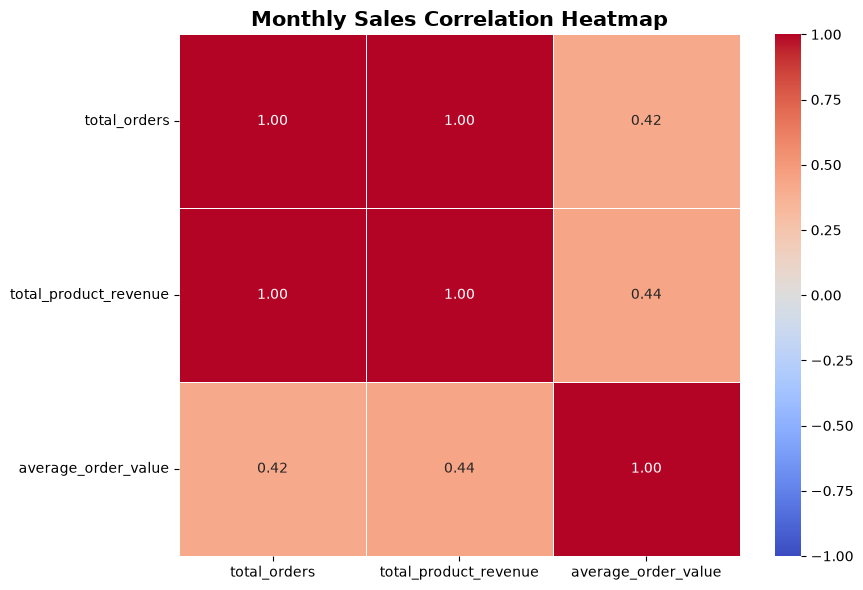

In [145]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title(
    "Monthly Sales Correlation Heatmap",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [146]:
# Create a copy for business analysis
sales_insights_df = monthly_sales_clean.copy()

# Calculate month-over-month growth
sales_insights_df["revenue_growth_pct"] = (
    sales_insights_df["total_product_revenue"].pct_change() * 100
)

# Highest and lowest revenue months
highest_revenue = sales_insights_df.loc[
    sales_insights_df["total_product_revenue"].idxmax()
]

lowest_revenue = sales_insights_df.loc[
    sales_insights_df["total_product_revenue"].idxmin()
]

# Highest order month
highest_orders = sales_insights_df.loc[
    sales_insights_df["total_orders"].idxmax()
]

# Average monthly revenue and orders
average_revenue = sales_insights_df["total_product_revenue"].mean()
average_orders = sales_insights_df["total_orders"].mean()

print("========== MONTHLY SALES BUSINESS INSIGHTS ==========")

print(
    f"\nHighest Revenue Month: "
    f"{highest_revenue['sales_month'].strftime('%B %Y')}"
)
print(
    f"Highest Revenue: R$ {highest_revenue['total_product_revenue']:,.2f}"
)

print(
    f"\nLowest Revenue Month: "
    f"{lowest_revenue['sales_month'].strftime('%B %Y')}"
)
print(
    f"Lowest Revenue: R$ {lowest_revenue['total_product_revenue']:,.2f}"
)

print(
    f"\nHighest Orders Month: "
    f"{highest_orders['sales_month'].strftime('%B %Y')}"
)
print(f"Highest Orders: {highest_orders['total_orders']:,}")

print(f"\nAverage Monthly Revenue: R$ {average_revenue:,.2f}")
print(f"Average Monthly Orders: {average_orders:,.0f}")

print("\n========== MONTHLY REVENUE GROWTH ==========")

display(
    sales_insights_df[
        ["sales_month", "total_product_revenue", "revenue_growth_pct"]
    ].tail(8)
)

========== MONTHLY SALES BUSINESS INSIGHTS ==========

Highest Revenue Month: November 2017
Highest Revenue: R$ 1,010,271.37

Lowest Revenue Month: December 2016
Lowest Revenue: R$ 10.90

Highest Orders Month: November 2017
Highest Orders: 7,544

Average Monthly Revenue: R$ 590,934.73
Average Monthly Orders: 4,323

========== MONTHLY REVENUE GROWTH ==========


,sales_month,total_product_revenue,revenue_growth_pct
15,2018-01-01,950030.36,27.706985
16,2018-02-01,844178.71,-11.141923
17,2018-03-01,983213.44,16.469822
18,2018-04-01,996647.75,1.366368
19,2018-05-01,996517.68,-0.013051
20,2018-06-01,865124.31,-13.185252
21,2018-07-01,895507.22,3.511970
22,2018-08-01,854686.33,-4.558410


In [147]:
# Create a complete monthly calendar
calendar_df = monthly_sales_clean.set_index("sales_month").asfreq("MS")

# Calculate growth only when previous calendar month exists
calendar_df["revenue_growth_pct"] = (
    calendar_df["total_product_revenue"].pct_change(fill_method=None) * 100
)

# Display recent months
print("===== CALENDAR-AWARE MONTHLY REVENUE GROWTH =====")

display(
    calendar_df[
        ["total_product_revenue", "revenue_growth_pct"]
    ].tail(12)
)

print("\nMissing calendar months:")
print(calendar_df[calendar_df["total_product_revenue"].isna()].index)

===== CALENDAR-AWARE MONTHLY REVENUE GROWTH =====


,total_product_revenue,revenue_growth_pct
sales_month,,
2017-09-01,624401.69,8.786150
2017-10-01,664219.43,6.376943
2017-11-01,1010271.37,52.099039
2017-12-01,743914.17,-26.364916
2018-01-01,950030.36,27.706985
2018-02-01,844178.71,-11.141923
2018-03-01,983213.44,16.469822
2018-04-01,996647.75,1.366368
2018-05-01,996517.68,-0.013051



Missing calendar months:
DatetimeIndex(['2016-11-01'], dtype='datetime64[s]', name='sales_month',
              freq='MS')


In [148]:
from pathlib import Path

# Create output directory
output_dir = Path("../python/outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Export cleaned monthly sales data
monthly_sales_clean.to_csv(
    output_dir / "monthly_sales_analysis.csv",
    index=False
)

# Export calendar-aware growth analysis
calendar_df.reset_index().to_csv(
    output_dir / "monthly_sales_growth_analysis.csv",
    index=False
)

# Export correlation matrix
correlation.to_csv(
    output_dir / "monthly_sales_correlation.csv"
)

print("Monthly Sales Analysis exports completed!")

print("\nExported files:")
print("1. monthly_sales_analysis.csv")
print("2. monthly_sales_growth_analysis.csv")
print("3. monthly_sales_correlation.csv")

Monthly Sales Analysis exports completed!

Exported files:
1. monthly_sales_analysis.csv
2. monthly_sales_growth_analysis.csv
3. monthly_sales_correlation.csv


In [149]:
customer_rfm_df = pd.read_sql_query(
    """
    SELECT *
    FROM analytics.customer_rfm
    """,
    engine
)

print("Customer RFM data loaded successfully!")
print("Dataset Shape:", customer_rfm_df.shape)

display(customer_rfm_df.head())

Customer RFM data loaded successfully!
Dataset Shape: (93358, 6)


,customer_unique_id,frequency,monetary,last_purchase_date,first_purchase_date,customer_lifespan_days
0,0000366f3b9a7992bf8c76cfdf3221e2,1,129.90,2018-05-10 10:56:27,2018-05-10 10:56:27,0.0
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,18.90,2018-05-07 11:11:27,2018-05-07 11:11:27,0.0
2,0000f46a3911fa3c0805444483337064,1,69.00,2017-03-10 21:05:03,2017-03-10 21:05:03,0.0
3,0000f6ccb0745a6a4b88665a16c9f078,1,25.99,2017-10-12 20:29:41,2017-10-12 20:29:41,0.0
4,0004aac84e0df4da2b147fca70cf8255,1,180.00,2017-11-14 19:45:42,2017-11-14 19:45:42,0.0


In [150]:
print("===== CUSTOMER RFM DATA QUALITY =====")

print("\n1. Dataset Information")
customer_rfm_df.info()

print("\n2. Missing Values")
print(customer_rfm_df.isnull().sum())

print("\n3. Duplicate Customer IDs")
print(customer_rfm_df["customer_unique_id"].duplicated().sum())

print("\n4. Frequency Summary")
display(customer_rfm_df["frequency"].describe())

print("\n5. Monetary Summary")
display(customer_rfm_df["monetary"].describe())

print("\n6. Customer Lifespan Summary")
display(customer_rfm_df["customer_lifespan_days"].describe())


===== CUSTOMER RFM DATA QUALITY =====

1. Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 93358 entries, 0 to 93357
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   customer_unique_id      93358 non-null  str           
 1   frequency               93358 non-null  int64         
 2   monetary                93358 non-null  float64       
 3   last_purchase_date      93358 non-null  datetime64[us]
 4   first_purchase_date     93358 non-null  datetime64[us]
 5   customer_lifespan_days  93358 non-null  float64       
dtypes: datetime64[us](2), float64(2), int64(1), str(1)
memory usage: 7.1 MB

2. Missing Values
customer_unique_id        0
frequency                 0
monetary                  0
last_purchase_date        0
first_purchase_date       0
customer_lifespan_days    0
dtype: int64

3. Duplicate Customer IDs
0

4. Frequency Summary


count    93358.000000
mean         1.033420
std          0.209097
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         15.000000
Name: frequency, dtype: float64


5. Monetary Summary


count    93358.000000
mean       141.621480
std        215.694014
min          0.850000
25%         47.650000
50%         89.730000
75%        154.737500
max      13440.000000
Name: monetary, dtype: float64


6. Customer Lifespan Summary


count    93358.000000
mean         2.645183
std         25.008095
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        633.080000
Name: customer_lifespan_days, dtype: float64

In [151]:
# Classify customers by purchase frequency

customer_rfm_df["customer_type"] = customer_rfm_df[
    "frequency"
].apply(
    lambda x: "One-Time Customer" if x == 1 else "Repeat Customer"
)

# Count customers by type
customer_type_summary = (
    customer_rfm_df.groupby("customer_type")
    .agg(
        total_customers=("customer_unique_id", "count"),
        average_spending=("monetary", "mean"),
        total_revenue=("monetary", "sum"),
        average_frequency=("frequency", "mean")
    )
    .reset_index()
)

# Calculate customer percentage
customer_type_summary["customer_percentage"] = (
    customer_type_summary["total_customers"]
    / len(customer_rfm_df) * 100
)

print("===== ONE-TIME VS REPEAT CUSTOMER ANALYSIS =====")

display(customer_type_summary.round(2))

===== ONE-TIME VS REPEAT CUSTOMER ANALYSIS =====


,customer_type,total_customers,average_spending,total_revenue,average_frequency,customer_percentage
0,One-Time Customer,90557,137.96,12493089.36,1.00,97.0
1,Repeat Customer,2801,260.05,728408.75,2.11,3.0


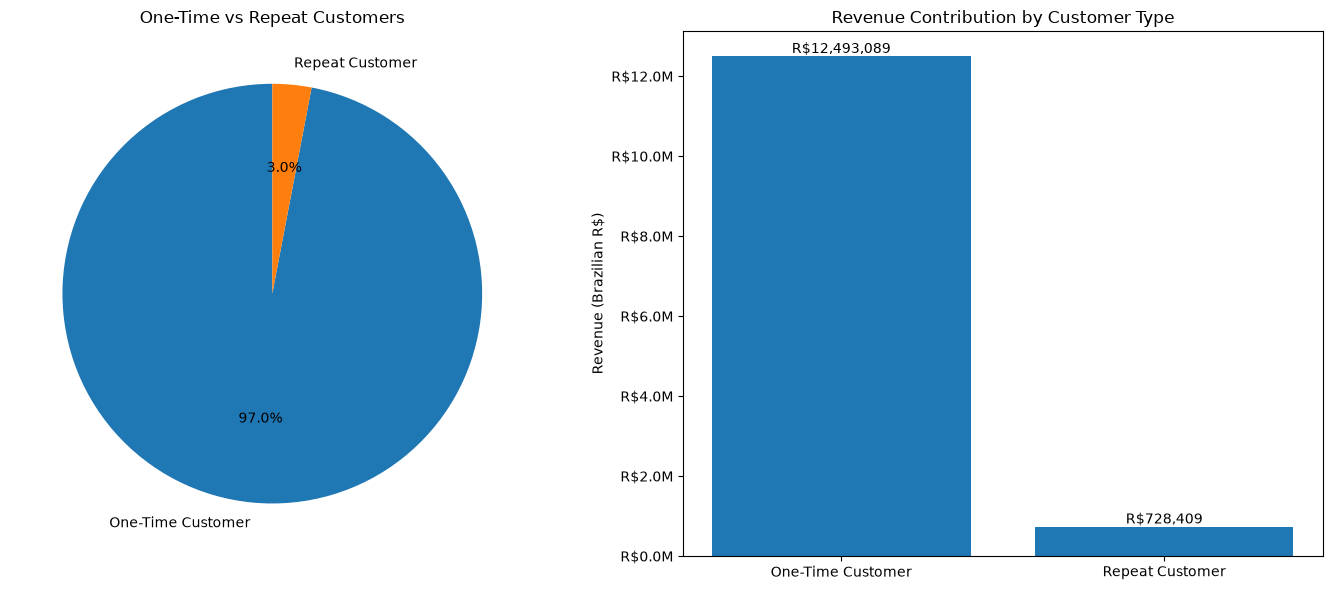

In [152]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Chart 1: Customer distribution
axes[0].pie(
    customer_type_summary["total_customers"],
    labels=customer_type_summary["customer_type"],
    autopct="%1.1f%%",
    startangle=90
)

axes[0].set_title("One-Time vs Repeat Customers")

# Chart 2: Revenue contribution
axes[1].bar(
    customer_type_summary["customer_type"],
    customer_type_summary["total_revenue"]
)

axes[1].set_title("Revenue Contribution by Customer Type")
axes[1].set_ylabel("Revenue (Brazilian R$)")

axes[1].yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f"R${x/1_000_000:.1f}M")
)

for i, value in enumerate(customer_type_summary["total_revenue"]):
    axes[1].text(
        i,
        value,
        f"R${value:,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [153]:
customer_rfm_scores_df = pd.read_sql_query(
    """
    SELECT *
    FROM analytics.customer_rfm_scores
    """,
    engine
)

print("RFM Scores loaded successfully!")
print("Dataset Shape:", customer_rfm_scores_df.shape)

display(customer_rfm_scores_df.head())
print("\nColumns:")
print(customer_rfm_scores_df.columns.tolist())

RFM Scores loaded successfully!
Dataset Shape: (93358, 10)


,customer_unique_id,analysis_date,last_purchase_date,recency_days,frequency,monetary,recency_score,frequency_score,monetary_score,rfm_segment_code
0,830d5b7aaa3b6f1e9ad63703bec97d23,2018-08-29,2016-09-15 12:16:38,713,1,134.97,1,4,4,144
1,8d3a54507421dbd2ce0a1d58046826e0,2018-08-29,2016-10-03 22:06:03,695,1,119.90,1,4,4,144
2,10e89fd8e5c745f81bec101207ba4d7d,2018-08-29,2016-10-03 22:51:30,695,1,74.90,1,3,3,133
3,7390ed59fa1febbfda31a80b4318c8cb,2018-08-29,2016-10-03 22:44:10,695,1,128.90,1,4,4,144
4,2f64e403852e6893ae37485d5fcacdaf,2018-08-29,2016-10-03 16:56:50,695,1,21.90,1,1,1,111



Columns:
['customer_unique_id', 'analysis_date', 'last_purchase_date', 'recency_days', 'frequency', 'monetary', 'recency_score', 'frequency_score', 'monetary_score', 'rfm_segment_code']


In [154]:
print("===== RFM SCORE DISTRIBUTION =====")

print("\n1. Recency Score Distribution")
display(
    customer_rfm_scores_df["recency_score"]
    .value_counts()
    .sort_index()
)

print("\n2. Frequency Score Distribution")
display(
    customer_rfm_scores_df["frequency_score"]
    .value_counts()
    .sort_index()
)

print("\n3. Monetary Score Distribution")
display(
    customer_rfm_scores_df["monetary_score"]
    .value_counts()
    .sort_index()
)

print("\n4. RFM Segment Code Distribution")
rfm_code_summary = (
    customer_rfm_scores_df["rfm_segment_code"]
    .value_counts()
    .sort_index()
    .reset_index()
)

rfm_code_summary.columns = ["rfm_segment_code", "total_customers"]

display(rfm_code_summary)

===== RFM SCORE DISTRIBUTION =====

1. Recency Score Distribution


recency_score
1    18672
2    18672
3    18672
4    18671
5    18671
Name: count, dtype: int64


2. Frequency Score Distribution


frequency_score
1    18672
2    18672
3    18672
4    18671
5    18671
Name: count, dtype: int64


3. Monetary Score Distribution


monetary_score
1    18672
2    18672
3    18672
4    18671
5    18671
Name: count, dtype: int64


4. RFM Segment Code Distribution


,rfm_segment_code,total_customers
0,111,3849
1,112,34
2,113,24
3,121,63
4,122,3792
...,...,...
76,551,10
77,552,45
78,553,83
79,554,175


In [155]:
customer_segments_df = pd.read_sql_query(
    """
    SELECT *
    FROM analytics.customer_segments
    """,
    engine
)

print("Customer Segments loaded successfully!")
print("Dataset Shape:", customer_segments_df.shape)

display(customer_segments_df.head(10))

print("\nColumns:")
print(customer_segments_df.columns.tolist())

Customer Segments loaded successfully!
Dataset Shape: (93358, 9)


,customer_unique_id,recency_days,frequency,monetary,recency_score,frequency_score,monetary_score,rfm_segment_code,customer_segment
0,830d5b7aaa3b6f1e9ad63703bec97d23,713,1,134.97,1,4,4,144,Cannot Lose Them
1,8d3a54507421dbd2ce0a1d58046826e0,695,1,119.90,1,4,4,144,Cannot Lose Them
2,7390ed59fa1febbfda31a80b4318c8cb,695,1,128.90,1,4,4,144,Cannot Lose Them
3,10e89fd8e5c745f81bec101207ba4d7d,695,1,74.90,1,1,3,113,Hibernating
4,61db744d2f835035a5625b59350c6b63,695,1,36.49,1,1,1,111,Hibernating
5,2f64e403852e6893ae37485d5fcacdaf,695,1,21.90,1,1,1,111,Hibernating
6,87776adb449c551e74c13fc34f036105,695,1,29.99,1,1,1,111,Hibernating
7,cd5a5843d35eebdf90368bf24d4a04cf,694,1,49.99,1,2,2,122,At Risk
8,b1a17b1877beaabde6421f631c95a734,694,1,49.90,1,2,2,122,At Risk
9,d58063e0329c70d19363e6225ca43128,694,1,69.90,1,3,3,133,At Risk



Columns:
['customer_unique_id', 'recency_days', 'frequency', 'monetary', 'recency_score', 'frequency_score', 'monetary_score', 'rfm_segment_code', 'customer_segment']


In [156]:
# Customer segment summary

segment_summary = (
    customer_segments_df.groupby("customer_segment")
    .agg(
        total_customers=("customer_unique_id", "count"),
        total_revenue=("monetary", "sum"),
        average_spending=("monetary", "mean"),
        average_frequency=("frequency", "mean"),
        average_recency=("recency_days", "mean")
    )
    .reset_index()
)

# Calculate customer and revenue percentages
segment_summary["customer_percentage"] = (
    segment_summary["total_customers"]
    / len(customer_segments_df) * 100
)

segment_summary["revenue_percentage"] = (
    segment_summary["total_revenue"]
    / customer_segments_df["monetary"].sum() * 100
)

# Sort by revenue
segment_summary = segment_summary.sort_values(
    "total_revenue",
    ascending=False
).reset_index(drop=True)

print("===== CUSTOMER SEGMENT PERFORMANCE =====")

display(segment_summary.round(2))

===== CUSTOMER SEGMENT PERFORMANCE =====


,customer_segment,total_customers,total_revenue,average_spending,average_frequency,average_recency,customer_percentage,revenue_percentage
0,Champions,14934,4073968.48,272.80,1.07,91.10,16.00,30.81
1,Cannot Lose Them,14490,3979656.26,274.65,1.07,392.98,15.52,30.10
2,Loyal Customers,7918,1895059.83,239.34,1.12,211.11,8.48,14.33
3,At Risk,15446,1153898.21,74.71,1.00,392.61,16.54,8.73
4,Potential Loyalists,14518,1081137.42,74.47,1.00,89.38,15.55,8.18
5,Other Customers,14847,743638.07,50.09,1.00,199.05,15.90,5.62
6,Hibernating,7408,193246.04,26.09,1.00,399.44,7.94,1.46
7,New Customers,3797,100893.80,26.57,1.00,44.25,4.07,0.76


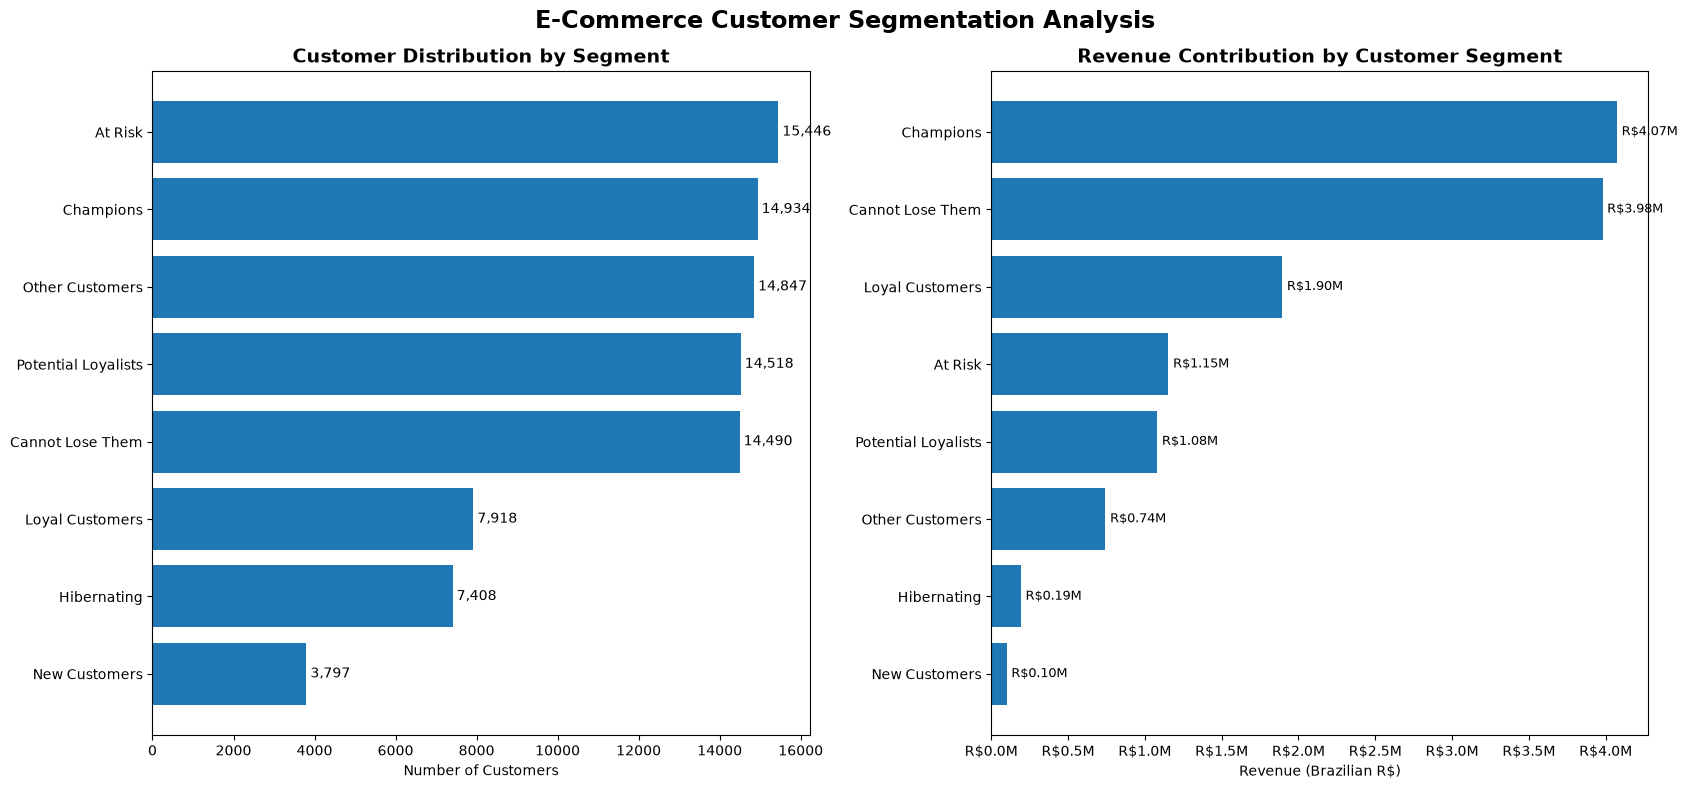

In [157]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Sort segments by customer count
plot_df = segment_summary.sort_values(
    "total_customers",
    ascending=True
)

fig, axes = plt.subplots(1, 2, figsize=(17, 8))

# Chart 1: Customer Distribution
axes[0].barh(
    plot_df["customer_segment"],
    plot_df["total_customers"]
)

axes[0].set_title(
    "Customer Distribution by Segment",
    fontsize=14,
    fontweight="bold"
)
axes[0].set_xlabel("Number of Customers")

for i, value in enumerate(plot_df["total_customers"]):
    axes[0].text(value + 100, i, f"{value:,}", va="center")

# Chart 2: Revenue Contribution
revenue_df = segment_summary.sort_values(
    "total_revenue",
    ascending=True
)

axes[1].barh(
    revenue_df["customer_segment"],
    revenue_df["total_revenue"]
)

axes[1].set_title(
    "Revenue Contribution by Customer Segment",
    fontsize=14,
    fontweight="bold"
)
axes[1].set_xlabel("Revenue (Brazilian R$)")

axes[1].xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"R${x/1_000_000:.1f}M")
)

for i, value in enumerate(revenue_df["total_revenue"]):
    axes[1].text(
        value + 30000,
        i,
        f"R${value/1_000_000:.2f}M",
        va="center",
        fontsize=9
    )

plt.suptitle(
    "E-Commerce Customer Segmentation Analysis",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [158]:
# Customer segment marketing recommendations

marketing_strategy = {
    "Champions": "VIP rewards, exclusive offers and referral programs",
    "Cannot Lose Them": "Personalized win-back campaigns and loyalty incentives",
    "Loyal Customers": "Membership benefits and cross-selling",
    "At Risk": "Reactivation campaigns and targeted discounts",
    "Potential Loyalists": "Second-purchase offers and product recommendations",
    "Other Customers": "Personalized recommendations and engagement campaigns",
    "Hibernating": "Low-cost reactivation emails and special offers",
    "New Customers": "Welcome offers and first-repeat-purchase incentives"
}

segment_summary["marketing_strategy"] = (
    segment_summary["customer_segment"].map(marketing_strategy)
)

print("===== CUSTOMER SEGMENT MARKETING STRATEGY =====")

display(
    segment_summary[
        [
            "customer_segment",
            "total_customers",
            "revenue_percentage",
            "marketing_strategy"
        ]
    ].round(2)
)

===== CUSTOMER SEGMENT MARKETING STRATEGY =====


,customer_segment,total_customers,revenue_percentage,marketing_strategy
0,Champions,14934,30.81,"VIP rewards, exclusive offers and referral pro..."
1,Cannot Lose Them,14490,30.10,Personalized win-back campaigns and loyalty in...
2,Loyal Customers,7918,14.33,Membership benefits and cross-selling
3,At Risk,15446,8.73,Reactivation campaigns and targeted discounts
4,Potential Loyalists,14518,8.18,Second-purchase offers and product recommendat...
5,Other Customers,14847,5.62,Personalized recommendations and engagement ca...
6,Hibernating,7408,1.46,Low-cost reactivation emails and special offers
7,New Customers,3797,0.76,Welcome offers and first-repeat-purchase incen...


In [159]:
from pathlib import Path

output_dir = Path("../python/outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Complete customer RFM data
customer_rfm_df.to_csv(
    output_dir / "customer_rfm_eda.csv",
    index=False
)

# 2. Customer type summary
customer_type_summary.to_csv(
    output_dir / "one_time_vs_repeat_customers.csv",
    index=False
)

# 3. Customer segment summary with marketing strategy
segment_summary.to_csv(
    output_dir / "customer_segment_business_analysis.csv",
    index=False
)

# 4. Complete customer segmentation
customer_segments_df.to_csv(
    output_dir / "customer_segmentation_details.csv",
    index=False
)

print("Customer Analysis exports completed!")

print("\nExported files:")
print("1. customer_rfm_eda.csv")
print("2. one_time_vs_repeat_customers.csv")
print("3. customer_segment_business_analysis.csv")
print("4. customer_segmentation_details.csv")

Customer Analysis exports completed!

Exported files:
1. customer_rfm_eda.csv
2. one_time_vs_repeat_customers.csv
3. customer_segment_business_analysis.csv
4. customer_segmentation_details.csv


In [160]:
product_df = pd.read_sql_query(
    """
    SELECT *
    FROM analytics.product_performance_detailed
    """,
    engine
)

print("Product data loaded successfully!")
print("Dataset Shape:", product_df.shape)

display(product_df.head())

print("\nColumns:")
print(product_df.columns.tolist())

Product data loaded successfully!
Dataset Shape: (32951, 9)


,product_id,category_name,total_items_sold,total_orders,total_sellers,total_revenue,total_freight,avg_selling_price,avg_freight
0,00066f42aeeb9f3007548bb9d3f33c38,perfumery,1,1,1,101.65,18.59,101.65,18.59
1,00088930e925c41fd95ebfe695fd2655,auto,1,1,1,129.90,13.93,129.90,13.93
2,0009406fd7479715e4bef61dd91f2462,bed_bath_table,1,1,1,229.00,13.10,229.00,13.10
3,000b8f95fcb9e0096488278317764d19,housewares,2,2,1,117.80,39.20,58.90,19.60
4,000d9be29b5207b54e86aa1b1ac54872,watches_gifts,1,1,1,199.00,19.27,199.00,19.27



Columns:
['product_id', 'category_name', 'total_items_sold', 'total_orders', 'total_sellers', 'total_revenue', 'total_freight', 'avg_selling_price', 'avg_freight']


In [161]:
print("===== PRODUCT DATA QUALITY CHECK =====")

print("\n1. Dataset Information")
product_df.info()

print("\n2. Missing Values")
print(product_df.isnull().sum())

print("\n3. Duplicate Product IDs")
print(product_df["product_id"].duplicated().sum())

print("\n4. Negative Revenue")
print((product_df["total_revenue"] < 0).sum())

print("\n5. Negative Freight")
print((product_df["total_freight"] < 0).sum())

print("\n6. Products Never Sold")
print((product_df["total_items_sold"] == 0).sum())

print("\n7. Product Revenue Summary")
display(product_df["total_revenue"].describe())

print("\n8. Items Sold Summary")
display(product_df["total_items_sold"].describe())

===== PRODUCT DATA QUALITY CHECK =====

1. Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   product_id         32951 non-null  str    
 1   category_name      32951 non-null  str    
 2   total_items_sold   32951 non-null  int64  
 3   total_orders       32951 non-null  int64  
 4   total_sellers      32951 non-null  int64  
 5   total_revenue      32951 non-null  float64
 6   total_freight      32951 non-null  float64
 7   avg_selling_price  32951 non-null  float64
 8   avg_freight        32951 non-null  float64
dtypes: float64(4), int64(3), str(2)
memory usage: 3.7 MB

2. Missing Values
product_id           0
category_name        0
total_items_sold     0
total_orders         0
total_sellers        0
total_revenue        0
total_freight        0
avg_selling_price    0
avg_freight          0
dtype: int64

3. Duplicate P

count    32951.000000
mean       412.480462
std       1371.945598
min          2.200000
25%         59.900000
50%        136.750000
75%        329.000000
max      63885.000000
Name: total_revenue, dtype: float64


8. Items Sold Summary


count    32951.000000
mean         3.418713
std         10.619709
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max        527.000000
Name: total_items_sold, dtype: float64

In [162]:
# Top 10 products by revenue

top_10_revenue = product_df.sort_values(
    "total_revenue",
    ascending=False
).head(10)

print("===== TOP 10 PRODUCTS BY REVENUE =====")

display(
    top_10_revenue[
        [
            "product_id",
            "category_name",
            "total_items_sold",
            "total_orders",
            "total_revenue",
            "avg_selling_price"
        ]
    ].reset_index(drop=True)
)

===== TOP 10 PRODUCTS BY REVENUE =====


,product_id,category_name,total_items_sold,total_orders,total_revenue,avg_selling_price
0,bb50f2e236e5eea0100680137654686c,health_beauty,195,187,63885.00,327.62
1,6cdd53843498f92890544667809f1595,health_beauty,156,151,54730.20,350.83
2,d6160fb7873f184099d9bc95e30376af,computers,35,35,48899.34,1397.12
3,d1c427060a0f73f6b889a5c7c61f2ac4,computers_accessories,343,323,47214.51,137.65
4,99a4788cb24856965c36a24e339b6058,bed_bath_table,488,467,43025.56,88.17
5,3dd2a17168ec895c781a9191c1e95ad7,computers_accessories,274,255,41082.60,149.94
6,25c38557cf793876c5abdd5931f922db,baby,38,38,38907.32,1023.88
7,5f504b3a1c75b73d6151be81eb05bdc9,cool_stuff,63,63,37733.90,598.95
8,53b36df67ebb7c41585e8d54d6772e08,watches_gifts,323,306,37683.42,116.67
9,aca2eb7d00ea1a7b8ebd4e68314663af,furniture_decor,527,431,37608.90,71.36


In [163]:
# Top 10 products by quantity sold

top_10_bestselling = product_df.sort_values(
    "total_items_sold",
    ascending=False
).head(10)

print("===== TOP 10 BEST-SELLING PRODUCTS =====")

display(
    top_10_bestselling[
        [
            "product_id",
            "category_name",
            "total_items_sold",
            "total_orders",
            "total_revenue",
            "avg_selling_price"
        ]
    ].reset_index(drop=True)
)

===== TOP 10 BEST-SELLING PRODUCTS =====


,product_id,category_name,total_items_sold,total_orders,total_revenue,avg_selling_price
0,aca2eb7d00ea1a7b8ebd4e68314663af,furniture_decor,527,431,37608.90,71.36
1,99a4788cb24856965c36a24e339b6058,bed_bath_table,488,467,43025.56,88.17
2,422879e10f46682990de24d770e7f83d,garden_tools,484,352,26577.22,54.91
3,389d119b48cf3043d311335e499d9c6b,garden_tools,392,311,21440.59,54.70
4,368c6c730842d78016ad823897a372db,garden_tools,388,291,21056.80,54.27
5,53759a2ecddad2bb87a079a1f1519f73,garden_tools,373,287,20387.20,54.66
6,d1c427060a0f73f6b889a5c7c61f2ac4,computers_accessories,343,323,47214.51,137.65
7,53b36df67ebb7c41585e8d54d6772e08,watches_gifts,323,306,37683.42,116.67
8,154e7e31ebfa092203795c972e5804a6,health_beauty,281,269,6325.19,22.51
9,3dd2a17168ec895c781a9191c1e95ad7,computers_accessories,274,255,41082.60,149.94


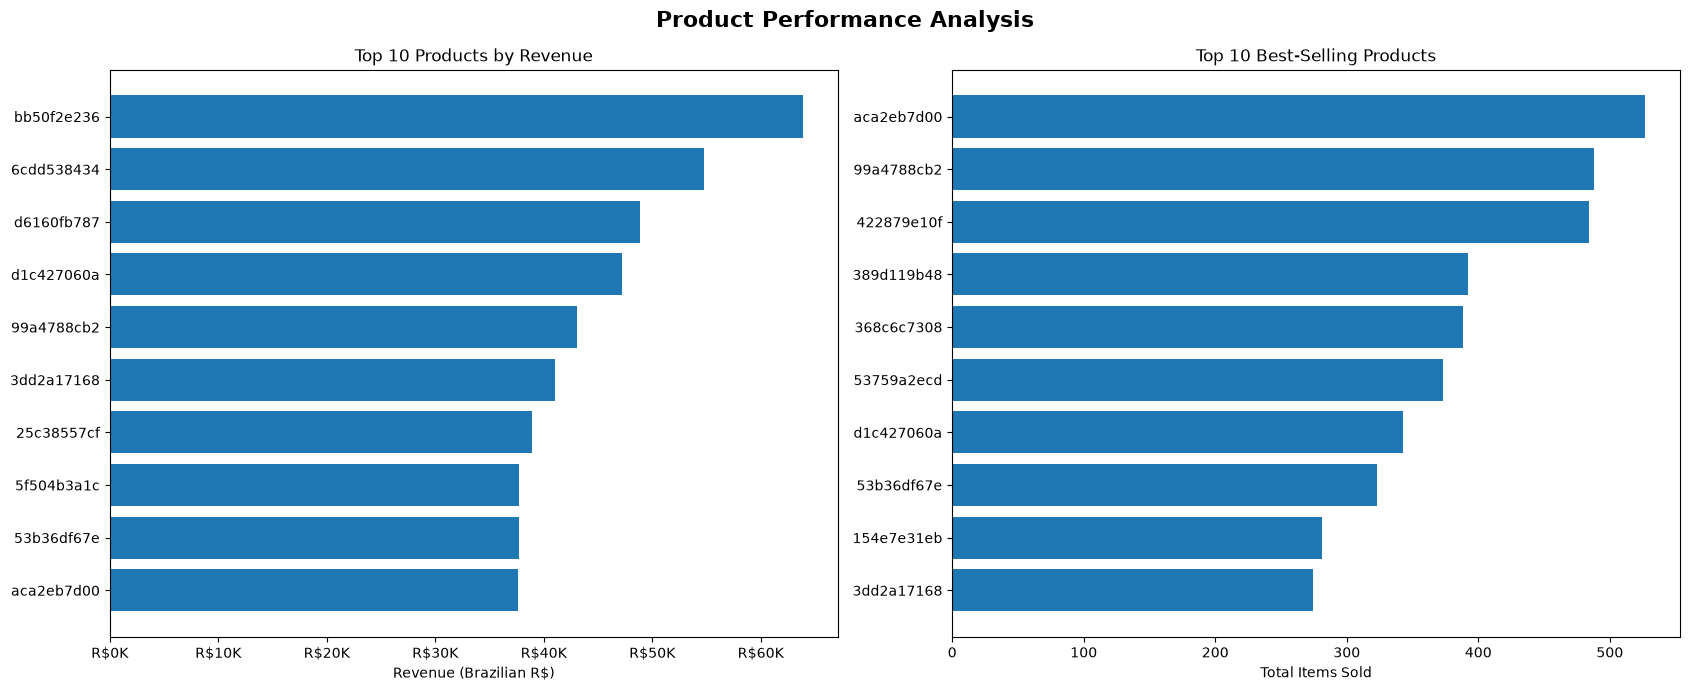

In [164]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

fig, axes = plt.subplots(1, 2, figsize=(17, 7))

# Chart 1: Top 10 by Revenue
revenue_plot = top_10_revenue.sort_values(
    "total_revenue",
    ascending=True
)

axes[0].barh(
    revenue_plot["product_id"].str[:10],
    revenue_plot["total_revenue"]
)

axes[0].set_title("Top 10 Products by Revenue")
axes[0].set_xlabel("Revenue (Brazilian R$)")

axes[0].xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"R${x/1000:.0f}K")
)

# Chart 2: Top 10 by Units Sold
sales_plot = top_10_bestselling.sort_values(
    "total_items_sold",
    ascending=True
)

axes[1].barh(
    sales_plot["product_id"].str[:10],
    sales_plot["total_items_sold"]
)

axes[1].set_title("Top 10 Best-Selling Products")
axes[1].set_xlabel("Total Items Sold")

plt.suptitle(
    "Product Performance Analysis",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [165]:
# Load category-level performance from PostgreSQL

category_df = pd.read_sql_query(
    """
    SELECT *
    FROM analytics.category_product_performance
    ORDER BY total_revenue DESC
    """,
    engine
)

print("Category data loaded successfully!")
print("Dataset Shape:", category_df.shape)

display(category_df.head(10))

print("\nColumns:")
print(category_df.columns.tolist())

Category data loaded successfully!
Dataset Shape: (74, 7)


,category_name,total_products,total_items_sold,product_order_count,total_revenue,avg_product_price,revenue_per_item
0,health_beauty,2444,9670.0,9022.0,1258681.34,146.78,130.16
1,watches_gifts,1329,5991.0,5799.0,1205005.68,335.91,201.14
2,bed_bath_table,3029,11115.0,10160.0,1036988.68,107.46,93.30
3,sports_leisure,2867,8641.0,7858.0,988048.97,135.44,114.34
4,computers_accessories,1639,7827.0,6887.0,911954.32,156.03,116.51
5,furniture_decor,2657,8334.0,6781.0,729762.49,103.23,87.56
6,cool_stuff,789,3796.0,3658.0,635290.85,214.70,167.36
7,housewares,2335,6964.0,6019.0,632248.66,98.56,90.79
8,auto,1900,4235.0,3991.0,592720.11,152.58,139.96
9,garden_tools,753,4347.0,3607.0,485256.46,222.61,111.63



Columns:
['category_name', 'total_products', 'total_items_sold', 'product_order_count', 'total_revenue', 'avg_product_price', 'revenue_per_item']


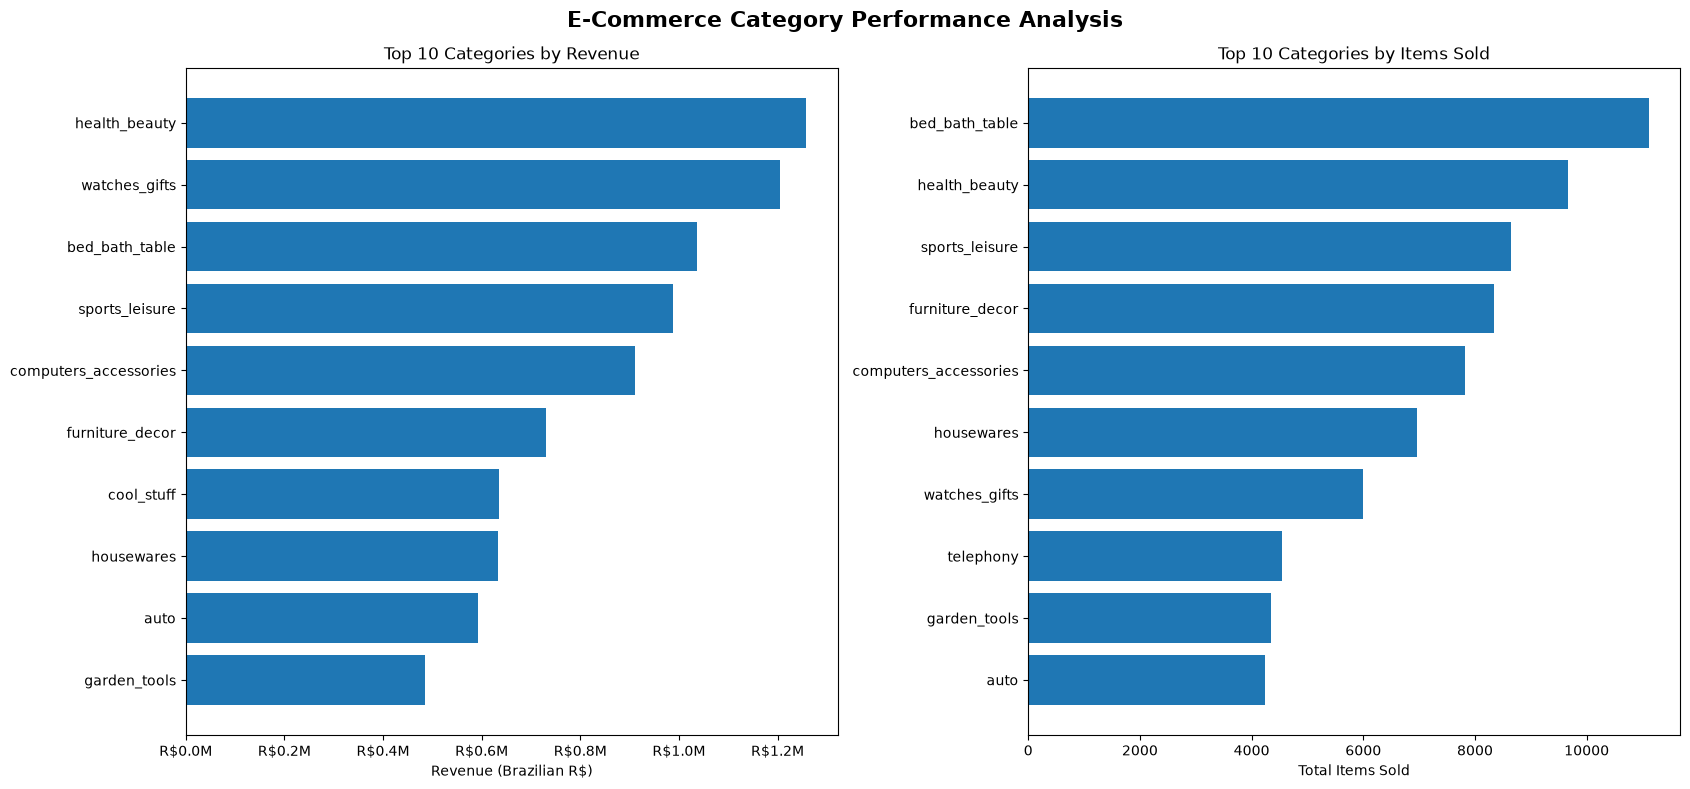

In [166]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

fig, axes = plt.subplots(1, 2, figsize=(17, 8))

# Top 10 categories by revenue
top_categories_revenue = category_df.nlargest(
    10, "total_revenue"
).sort_values("total_revenue")

axes[0].barh(
    top_categories_revenue["category_name"],
    top_categories_revenue["total_revenue"]
)

axes[0].set_title("Top 10 Categories by Revenue")
axes[0].set_xlabel("Revenue (Brazilian R$)")

axes[0].xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"R${x/1_000_000:.1f}M")
)

# Top 10 categories by items sold
top_categories_items = category_df.nlargest(
    10, "total_items_sold"
).sort_values("total_items_sold")

axes[1].barh(
    top_categories_items["category_name"],
    top_categories_items["total_items_sold"]
)

axes[1].set_title("Top 10 Categories by Items Sold")
axes[1].set_xlabel("Total Items Sold")

plt.suptitle(
    "E-Commerce Category Performance Analysis",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [167]:
# Calculate median thresholds
median_items = category_df["total_items_sold"].median()
median_revenue = category_df["total_revenue"].median()

# Classify categories
def classify_category(row):
    high_volume = row["total_items_sold"] >= median_items
    high_revenue = row["total_revenue"] >= median_revenue

    if high_volume and high_revenue:
        return "High Volume - High Revenue"
    elif high_volume and not high_revenue:
        return "High Volume - Low Revenue"
    elif not high_volume and high_revenue:
        return "Low Volume - High Revenue"
    else:
        return "Low Volume - Low Revenue"

category_df["category_segment"] = category_df.apply(
    classify_category,
    axis=1
)

# Summary
category_segment_summary = (
    category_df.groupby("category_segment")
    .agg(
        total_categories=("category_name", "count"),
        total_items_sold=("total_items_sold", "sum"),
        total_revenue=("total_revenue", "sum")
    )
    .reset_index()
)

print("===== CATEGORY PERFORMANCE SEGMENTS =====")
print("Median Items Sold:", median_items)
print("Median Revenue: R$", round(median_revenue, 2))

display(category_segment_summary.round(2))


===== CATEGORY PERFORMANCE SEGMENTS =====
Median Items Sold: 279.5
Median Revenue: R$ 46592.62


,category_segment,total_categories,total_items_sold,total_revenue
0,High Volume - High Revenue,32,106665.0,12574325.19
1,High Volume - Low Revenue,5,1785.0,167608.95
2,Low Volume - High Revenue,5,993.0,515840.05
3,Low Volume - Low Revenue,32,3207.0,333869.51


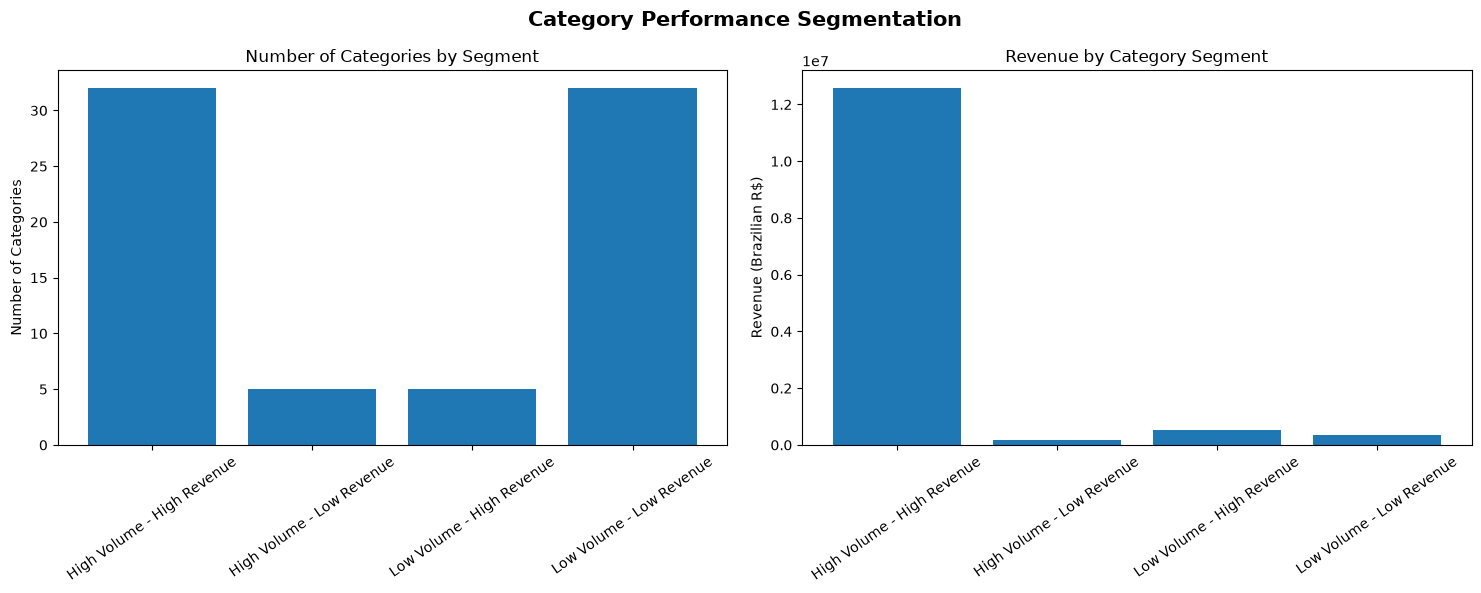

In [168]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Category count
axes[0].bar(
    category_segment_summary["category_segment"],
    category_segment_summary["total_categories"]
)

axes[0].set_title("Number of Categories by Segment")
axes[0].set_ylabel("Number of Categories")
axes[0].tick_params(axis="x", rotation=35)

# Revenue contribution
axes[1].bar(
    category_segment_summary["category_segment"],
    category_segment_summary["total_revenue"]
)

axes[1].set_title("Revenue by Category Segment")
axes[1].set_ylabel("Revenue (Brazilian R$)")
axes[1].tick_params(axis="x", rotation=35)

plt.suptitle(
    "Category Performance Segmentation",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [169]:
from pathlib import Path

output_dir = Path("../python/outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Complete product performance
product_df.to_csv(
    output_dir / "product_performance_analysis.csv",
    index=False
)

# 2. Top 10 revenue products
top_10_revenue.to_csv(
    output_dir / "top_10_products_by_revenue.csv",
    index=False
)

# 3. Top 10 best-selling products
top_10_bestselling.to_csv(
    output_dir / "top_10_bestselling_products.csv",
    index=False
)

# 4. Category performance
category_df.to_csv(
    output_dir / "category_performance_analysis.csv",
    index=False
)

# 5. Category segment summary
category_segment_summary.to_csv(
    output_dir / "category_segment_business_analysis.csv",
    index=False
)

print("Product & Category Analysis exports completed!")
print("Total files exported: 5")

Product & Category Analysis exports completed!
Total files exported: 5


In [170]:
seller_df = pd.read_sql_query(
    """
    SELECT *
    FROM analytics.seller_performance
    """,
    engine
)

print("Seller data loaded successfully!")
print("Dataset Shape:", seller_df.shape)

display(seller_df.head())

print("\nColumns:")
print(seller_df.columns.tolist())

Seller data loaded successfully!
Dataset Shape: (3095, 12)


,seller_id,seller_city,seller_state,total_orders,total_items,total_product_revenue,total_freight,avg_item_price,delivered_orders,avg_delivery_days,avg_review_score,reviewed_orders
0,0015a82c2db000af6aaaf3ae2ecb0532,santo andre,SP,3,3,2685.00,63.06,895.00,3,10.79,3.67,3
1,001cca7ae9ae17fb1caed9dfb1094831,cariacica,ES,200,239,25080.03,8854.14,104.94,195,13.41,3.98,197
2,001e6ad469a905060d959994f1b41e4f,sao goncalo,RJ,1,1,250.00,17.94,250.00,0,NaN,1.00,1
3,002100f778ceb8431b7a1020ff7ab48f,franca,SP,51,55,1234.50,793.66,22.45,50,16.39,3.90,51
4,003554e2dce176b5555353e4f3555ac8,goiania,GO,1,1,120.00,19.38,120.00,1,4.65,5.00,1



Columns:
['seller_id', 'seller_city', 'seller_state', 'total_orders', 'total_items', 'total_product_revenue', 'total_freight', 'avg_item_price', 'delivered_orders', 'avg_delivery_days', 'avg_review_score', 'reviewed_orders']


In [171]:
print("===== SELLER DATA QUALITY CHECK =====")

print("\n1. Dataset Information")
seller_df.info()

print("\n2. Missing Values")
display(seller_df.isnull().sum())

print("\n3. Duplicate Seller IDs")
print(seller_df["seller_id"].duplicated().sum())

print("\n4. Negative Revenue")
print((seller_df["total_product_revenue"] < 0).sum())

print("\n5. Negative Freight")
print((seller_df["total_freight"] < 0).sum())

print("\n6. Sellers with Zero Orders")
print((seller_df["total_orders"] == 0).sum())

print("\n7. Sellers with No Delivered Orders")
print((seller_df["delivered_orders"] == 0).sum())

print("\n8. Seller Revenue Summary")
display(seller_df["total_product_revenue"].describe())

print("\n9. Seller Orders Summary")
display(seller_df["total_orders"].describe())

print("\n10. Seller Review Score Summary")
display(seller_df["avg_review_score"].describe())

===== SELLER DATA QUALITY CHECK =====

1. Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   seller_id              3095 non-null   str    
 1   seller_city            3095 non-null   str    
 2   seller_state           3095 non-null   str    
 3   total_orders           3095 non-null   int64  
 4   total_items            3095 non-null   int64  
 5   total_product_revenue  3095 non-null   float64
 6   total_freight          3095 non-null   float64
 7   avg_item_price         3095 non-null   float64
 8   delivered_orders       3095 non-null   int64  
 9   avg_delivery_days      2970 non-null   float64
 10  avg_review_score       3090 non-null   float64
 11  reviewed_orders        3095 non-null   int64  
dtypes: float64(5), int64(4), str(3)
memory usage: 423.8 KB

2. Missing Values


seller_id                  0
seller_city                0
seller_state               0
total_orders               0
total_items                0
total_product_revenue      0
total_freight              0
avg_item_price             0
delivered_orders           0
avg_delivery_days        125
avg_review_score           5
reviewed_orders            0
dtype: int64


3. Duplicate Seller IDs
0

4. Negative Revenue
0

5. Negative Freight
0

6. Sellers with Zero Orders
0

7. Sellers with No Delivered Orders
125

8. Seller Revenue Summary


count      3095.000000
mean       4391.484233
std       13921.997192
min           3.500000
25%         208.850000
50%         821.480000
75%        3280.830000
max      229472.630000
Name: total_product_revenue, dtype: float64


9. Seller Orders Summary


count    3095.000000
mean       32.313409
std       105.139763
min         1.000000
25%         2.000000
50%         6.000000
75%        21.500000
max      1854.000000
Name: total_orders, dtype: float64


10. Seller Review Score Summary


count    3090.000000
mean        3.998570
std         0.955878
min         1.000000
25%         3.780000
50%         4.180000
75%         4.600000
max         5.000000
Name: avg_review_score, dtype: float64

In [172]:
# Top 10 sellers by revenue

top_10_sellers_revenue = seller_df.sort_values(
    "total_product_revenue",
    ascending=False
).head(10)

print("===== TOP 10 SELLERS BY REVENUE =====")

display(
    top_10_sellers_revenue[
        [
            "seller_id",
            "seller_city",
            "seller_state",
            "total_orders",
            "total_items",
            "total_product_revenue",
            "avg_review_score",
            "avg_delivery_days"
        ]
    ].reset_index(drop=True)
)

===== TOP 10 SELLERS BY REVENUE =====


,seller_id,seller_city,seller_state,total_orders,total_items,total_product_revenue,avg_review_score,avg_delivery_days
0,4869f7a5dfa277a7dca6462dcf3b52b2,guariba,SP,1132,1156,229472.63,4.13,15.06
1,53243585a1d6dc2643021fd1853d8905,lauro de freitas,BA,358,410,222776.05,4.13,13.43
2,4a3ca9315b744ce9f8e9374361493884,ibitinga,SP,1806,1987,200472.92,3.83,14.49
3,fa1c13f2614d7b5c4749cbc52fecda94,sumare,SP,585,586,194042.03,4.34,13.35
4,7c67e1448b00f6e969d365cea6b010ab,itaquaquecetuba,SP,982,1364,187923.89,3.49,22.34
5,7e93a43ef30c4f03f38b393420bc753a,barueri,SP,336,340,176431.87,4.21,11.31
6,da8622b14eb17ae2831f4ac5b9dab84a,piracicaba,SP,1314,1551,160236.57,4.17,11.19
7,7a67c85e85bb2ce8582c35f2203ad736,sao paulo,SP,1160,1171,141745.53,4.24,11.20
8,1025f0e2d44d7041d6cf58b6550e0bfa,sao paulo,SP,915,1428,138968.55,3.99,12.39
9,955fee9216a65b617aa5c0531780ce60,sao paulo,SP,1287,1499,135171.70,4.16,10.77


In [173]:
# Top 10 sellers by order volume

top_10_sellers_orders = seller_df.sort_values(
    "total_orders",
    ascending=False
).head(10)

print("===== TOP 10 SELLERS BY ORDERS =====")

display(
    top_10_sellers_orders[
        [
            "seller_id",
            "seller_city",
            "seller_state",
            "total_orders",
            "total_items",
            "total_product_revenue",
            "avg_review_score",
            "avg_delivery_days"
        ]
    ].reset_index(drop=True)
)

===== TOP 10 SELLERS BY ORDERS =====


,seller_id,seller_city,seller_state,total_orders,total_items,total_product_revenue,avg_review_score,avg_delivery_days
0,6560211a19b47992c3666cc44a7e94c0,sao paulo,SP,1854,2033,123304.83,3.94,9.63
1,4a3ca9315b744ce9f8e9374361493884,ibitinga,SP,1806,1987,200472.92,3.83,14.49
2,cc419e0650a3c5ba77189a1882b7556a,santo andre,SP,1706,1775,104288.42,4.07,11.59
3,1f50f920176fa81dab994f9023523100,sao jose do rio preto,SP,1404,1931,106939.21,4.13,15.81
4,da8622b14eb17ae2831f4ac5b9dab84a,piracicaba,SP,1314,1551,160236.57,4.17,11.19
5,955fee9216a65b617aa5c0531780ce60,sao paulo,SP,1287,1499,135171.70,4.16,10.77
6,7a67c85e85bb2ce8582c35f2203ad736,sao paulo,SP,1160,1171,141745.53,4.24,11.20
7,ea8482cd71df3c1969d7b9473ff13abc,sao paulo,SP,1146,1203,37177.52,4.00,13.32
8,4869f7a5dfa277a7dca6462dcf3b52b2,guariba,SP,1132,1156,229472.63,4.13,15.06
9,3d871de0142ce09b7081e2b9d1733cb1,campo limpo paulista,SP,1080,1147,94914.20,4.15,13.51


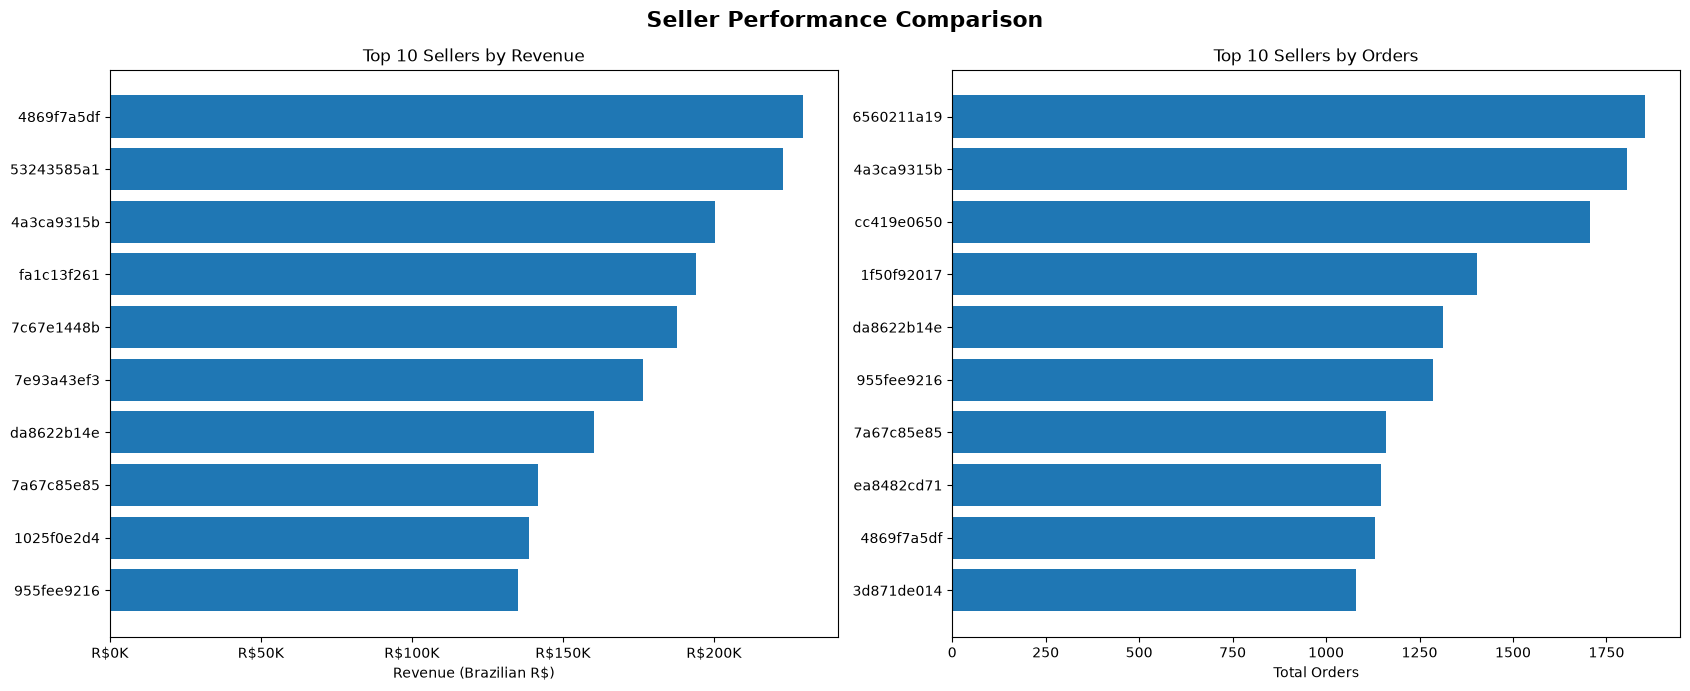

In [174]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

fig, axes = plt.subplots(1, 2, figsize=(17, 7))

# Revenue chart
revenue_plot = top_10_sellers_revenue.sort_values(
    "total_product_revenue",
    ascending=True
)

axes[0].barh(
    revenue_plot["seller_id"].str[:10],
    revenue_plot["total_product_revenue"]
)

axes[0].set_title("Top 10 Sellers by Revenue")
axes[0].set_xlabel("Revenue (Brazilian R$)")

axes[0].xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"R${x/1000:.0f}K")
)

# Orders chart
orders_plot = top_10_sellers_orders.sort_values(
    "total_orders",
    ascending=True
)

axes[1].barh(
    orders_plot["seller_id"].str[:10],
    orders_plot["total_orders"]
)

axes[1].set_title("Top 10 Sellers by Orders")
axes[1].set_xlabel("Total Orders")

plt.suptitle(
    "Seller Performance Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [175]:
# Top 10 sellers by customer rating
top_rated_sellers = (
    seller_df.dropna(subset=["avg_review_score"])
    .sort_values("avg_review_score", ascending=False)
    .head(10)
)

# Bottom 10 sellers by customer rating
lowest_rated_sellers = (
    seller_df.dropna(subset=["avg_review_score"])
    .sort_values("avg_review_score", ascending=True)
    .head(10)
)

# Fastest delivery sellers (minimum 10 delivered orders)
fastest_delivery_sellers = (
    seller_df[seller_df["delivered_orders"] >= 10]
    .dropna(subset=["avg_delivery_days"])
    .sort_values("avg_delivery_days")
    .head(10)
)

# Slowest delivery sellers (minimum 10 delivered orders)
slowest_delivery_sellers = (
    seller_df[seller_df["delivered_orders"] >= 10]
    .dropna(subset=["avg_delivery_days"])
    .sort_values("avg_delivery_days", ascending=False)
    .head(10)
)

print("===== TOP 10 HIGHEST-RATED SELLERS =====")
display(top_rated_sellers[
    ["seller_id", "seller_city", "seller_state",
     "avg_review_score", "reviewed_orders"]
])

print("\n===== TOP 10 LOWEST-RATED SELLERS =====")
display(lowest_rated_sellers[
    ["seller_id", "seller_city", "seller_state",
     "avg_review_score", "reviewed_orders"]
])

print("\n===== TOP 10 FASTEST-DELIVERY SELLERS =====")
display(fastest_delivery_sellers[
    ["seller_id", "seller_city", "delivered_orders",
     "avg_delivery_days", "avg_review_score"]
])

print("\n===== TOP 10 SLOWEST-DELIVERY SELLERS =====")
display(slowest_delivery_sellers[
    ["seller_id", "seller_city", "delivered_orders",
     "avg_delivery_days", "avg_review_score"]
])

===== TOP 10 HIGHEST-RATED SELLERS =====


,seller_id,seller_city,seller_state,avg_review_score,reviewed_orders
1891,9b76ad3d04236f76bc71c59470305e13,boituva,SP,5.0,2
256,160851d3ece7aa1a510f8d1a4bb8a8af,garca,SP,5.0,2
2161,b3e2faf2c1004d674f16a3aa3197f0e1,ribeirao preto,SP,5.0,3
2945,f3862c2188522d89860c38a3ea8b550d,ribeirao preto,SP,5.0,1
859,48b6c3f4c6a93171da04b75313f2130f,osvaldo cruz,SP,5.0,2
1805,93bef6edaa84956e8e575016449b6351,sao paulo,SP,5.0,1
350,1d953075c2f0dd990bacf27b83b330f1,belo horizonte,MG,5.0,1
1061,570d4583587a5fe2d47c7be89b91ad27,sao paulo,SP,5.0,2
1062,5721089ba9214e80074f27d5a03fc0eb,sao paulo,SP,5.0,5
1063,5733d806668f8712c24b9abaefbfa642,chapeco,SP,5.0,2



===== TOP 10 LOWEST-RATED SELLERS =====


,seller_id,seller_city,seller_state,avg_review_score,reviewed_orders
689,3a52d63a8f9daf5a28f3626d7eb9bd28,aguas claras df,SP,1.0,1
2661,dc120d932ddf9d4dfb6fd68beefda622,sao jose dos pinhais,PR,1.0,1
1745,8e670472e453ba34a379331513d6aab1,juiz de fora,MG,1.0,1
2645,dadc51ef321949ec9a3ab25cd902e23d,sao paulo,SP,1.0,1
395,20fd2d2080ed85fa67fad3fcbb2c1813,colombo,PR,1.0,1
2638,da2782c804606d2a5d8e1760dbb3e7ec,sao paulo,SP,1.0,1
128,0aa124728afc1131dff5655f4c6f487b,alfenas,MG,1.0,2
1777,90d4125885ab6c86e8820a722be71974,taboao da serra,SP,1.0,3
1779,913fd0ebba70bb919f7254a02239173c,blumenau,SC,1.0,1
1734,8d92f3ea807b89465643c219455e7369,sao paulo,SP,1.0,3



===== TOP 10 FASTEST-DELIVERY SELLERS =====


,seller_id,seller_city,delivered_orders,avg_delivery_days,avg_review_score
1099,5a413ade68e8f8d93071a7f52a64cb9e,sao paulo,14,4.12,4.64
577,30a81d8cf85fb2ada1b1b094c9583a95,sao paulo,17,4.29,4.82
2366,c3e1abd72a42fe690fcd89cf5720fe29,mogi guacu,13,4.31,4.46
2057,aac51c486b672a9850d59f3e84b1cf88,sao paulo,10,4.65,4.80
786,41c2bad7229b0c25e6becf179ebf63ff,natal,20,4.69,4.95
2264,bc2ac6b95e1accce9858528ee566c17e,campinas,18,4.75,4.56
1575,7ff588a03c2aeae4fbd23f9ae64b760d,guarulhos,14,4.79,4.64
845,4736e9d642ef4257cd7622516931eb51,piracicaba,16,4.80,4.13
756,3fac58ce0ad699020c7944d53c41329c,sao paulo,10,4.89,4.40
2531,d13e50eaa47b4cbe9eb81465865d8cfc,santo andre,66,5.04,4.82



===== TOP 10 SLOWEST-DELIVERY SELLERS =====


,seller_id,seller_city,delivered_orders,avg_delivery_days,avg_review_score
2468,cb41bfbcbda0aea354a834ab222f9a59,sao paulo,11,37.56,3.33
2862,ecccfa2bb93b34a3bf033cc5d1dcdc69,curitiba,12,32.12,2.57
1257,66e0557ecc2b4dbea057e93f215f68d8,sao paulo,30,31.73,3.94
59,054694fa03fe82cec4b7551487331d74,itajobi,20,30.79,3.48
492,2a1348e9addc1af5aaa619b1a3679d6b,belo horizonte,48,27.31,3.12
962,5058e8c1e82653974541e83690655b4a,itaquaquecetuba,62,26.68,3.24
1604,822bad9bc42b51213ba522fe87b7ab5d,balneario camboriu,18,26.66,4.11
459,26e2c91ef821e1ff8985f408788fe35b,ibitinga,12,26.22,3.00
32,02d35243ea2e497335cd0f076b45675d,natal,14,26.17,2.64
1032,54965bbe3e4f07ae045b90b0b8541f52,foz do iguacu,73,26.17,3.00


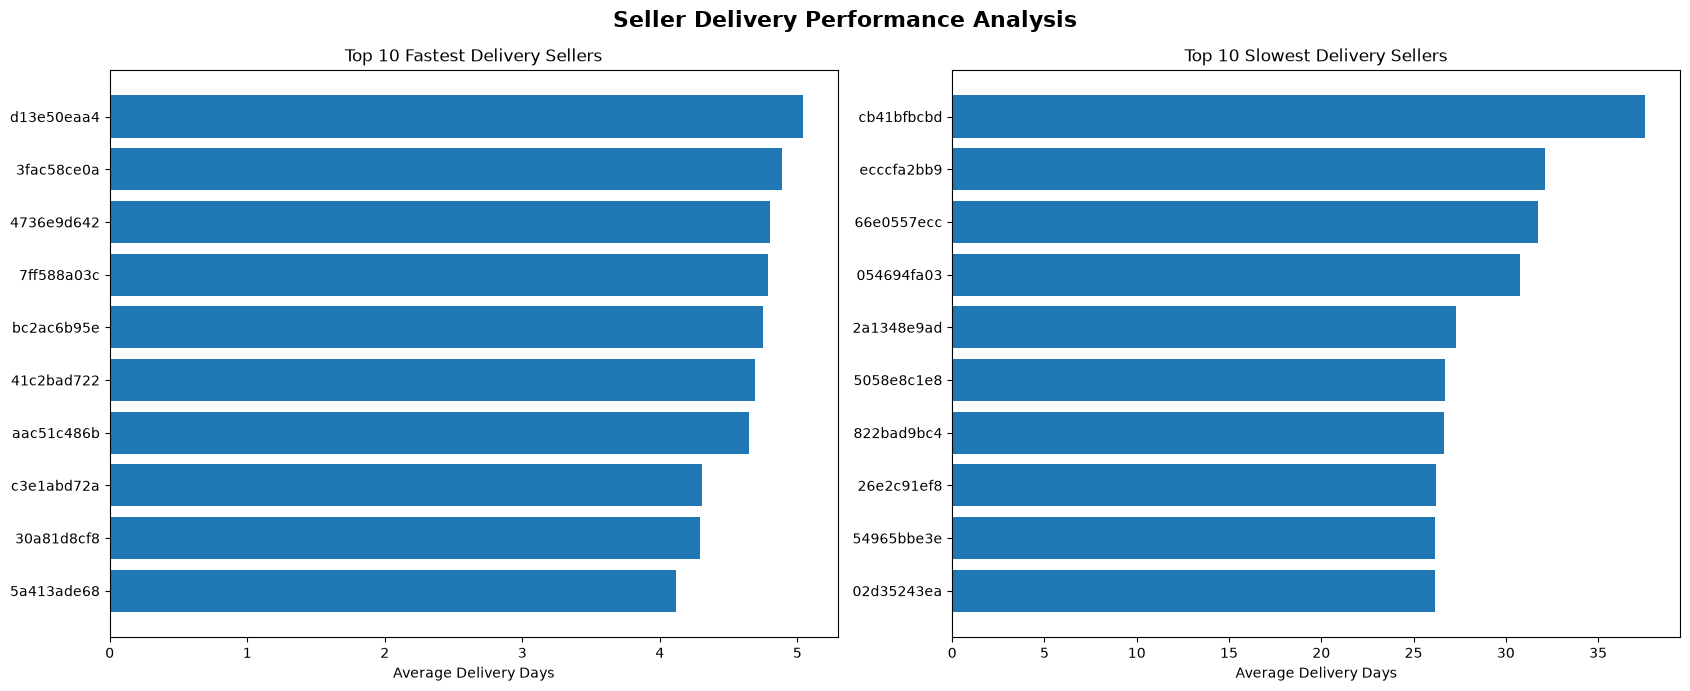

In [176]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(17, 7))

# Top 10 fastest delivery sellers
fast_plot = fastest_delivery_sellers.sort_values(
    "avg_delivery_days",
    ascending=True
)

axes[0].barh(
    fast_plot["seller_id"].str[:10],
    fast_plot["avg_delivery_days"]
)

axes[0].set_title("Top 10 Fastest Delivery Sellers")
axes[0].set_xlabel("Average Delivery Days")

# Top 10 slowest delivery sellers
slow_plot = slowest_delivery_sellers.sort_values(
    "avg_delivery_days",
    ascending=True
)

axes[1].barh(
    slow_plot["seller_id"].str[:10],
    slow_plot["avg_delivery_days"]
)

axes[1].set_title("Top 10 Slowest Delivery Sellers")
axes[1].set_xlabel("Average Delivery Days")

plt.suptitle(
    "Seller Delivery Performance Analysis",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [177]:
# State-wise seller performance
seller_state_analysis = (
    seller_df.groupby("seller_state")
    .agg(
        total_sellers=("seller_id", "nunique"),
        total_orders=("total_orders", "sum"),
        total_revenue=("total_product_revenue", "sum"),
        avg_review_score=("avg_review_score", "mean"),
        avg_delivery_days=("avg_delivery_days", "mean")
    )
    .reset_index()
)

# Sort by revenue
seller_state_analysis = seller_state_analysis.sort_values(
    "total_revenue",
    ascending=False
)

# Display results
display(seller_state_analysis.round(2))

print("Total States:", seller_state_analysis["seller_state"].nunique())
print("Highest Revenue State:",
      seller_state_analysis.iloc[0]["seller_state"])
print("Highest Revenue:",
      round(seller_state_analysis.iloc[0]["total_revenue"], 2))

,seller_state,total_sellers,total_orders,total_revenue,avg_review_score,avg_delivery_days
22,SP,1849,70950,8753396.21,3.97,11.84
15,PR,349,7717,1261887.21,4.04,12.13
8,MG,244,7942,1011564.74,4.05,12.76
16,RJ,171,4355,843984.22,3.98,11.76
20,SC,190,3672,632426.07,4.08,12.88
19,RS,129,1991,378559.54,4.06,13.43
2,BA,19,569,285561.56,3.94,15.89
4,DF,30,824,97749.48,4.03,13.29
13,PE,9,406,91493.85,4.12,13.37
6,GO,40,463,66399.21,4.11,14.45


Total States: 23
Highest Revenue State: SP
Highest Revenue: 8753396.21


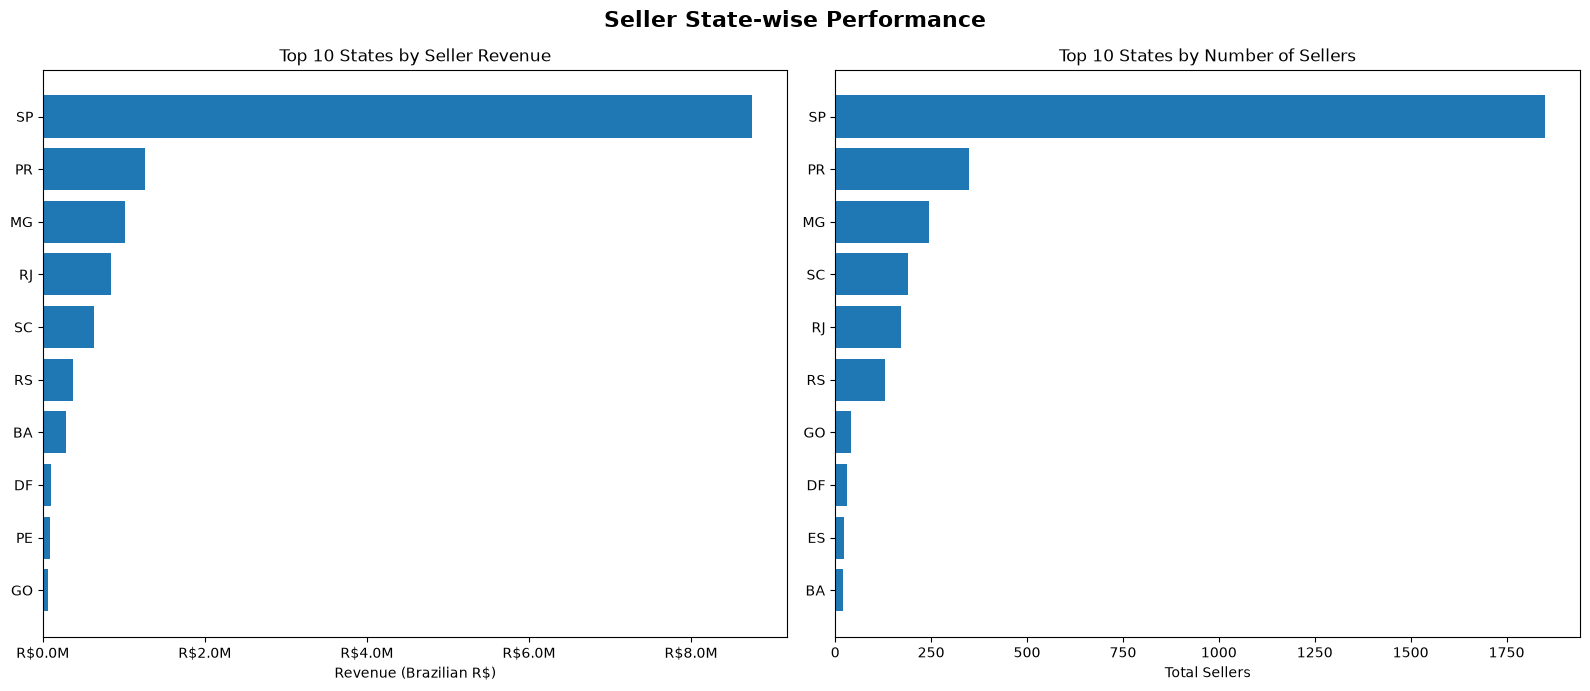

In [178]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Top 10 states by revenue
top_states_revenue = seller_state_analysis.nlargest(
    10, "total_revenue"
).sort_values("total_revenue")

# Top 10 states by seller count
top_states_sellers = seller_state_analysis.nlargest(
    10, "total_sellers"
).sort_values("total_sellers")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Revenue chart
axes[0].barh(
    top_states_revenue["seller_state"],
    top_states_revenue["total_revenue"]
)
axes[0].set_title("Top 10 States by Seller Revenue")
axes[0].set_xlabel("Revenue (Brazilian R$)")
axes[0].xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"R${x/1_000_000:.1f}M")
)

# Seller count chart
axes[1].barh(
    top_states_sellers["seller_state"],
    top_states_sellers["total_sellers"]
)
axes[1].set_title("Top 10 States by Number of Sellers")
axes[1].set_xlabel("Total Sellers")

plt.suptitle(
    "Seller State-wise Performance",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [179]:
from pathlib import Path

# Create output directory
output_dir = Path("../python/outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Export seller datasets
seller_df.to_csv(
    output_dir / "seller_performance_analysis.csv",
    index=False
)

top_10_sellers_revenue.to_csv(
    output_dir / "top_10_sellers_by_revenue.csv",
    index=False
)

top_10_sellers_orders.to_csv(
    output_dir / "top_10_sellers_by_orders.csv",
    index=False
)

top_rated_sellers.to_csv(
    output_dir / "top_10_highest_rated_sellers.csv",
    index=False
)

lowest_rated_sellers.to_csv(
    output_dir / "top_10_lowest_rated_sellers.csv",
    index=False
)

fastest_delivery_sellers.to_csv(
    output_dir / "top_10_fastest_delivery_sellers.csv",
    index=False
)

slowest_delivery_sellers.to_csv(
    output_dir / "top_10_slowest_delivery_sellers.csv",
    index=False
)

seller_state_analysis.to_csv(
    output_dir / "seller_state_performance.csv",
    index=False
)

print("Seller analysis CSV exports completed!")
print("Files saved:", len(list(output_dir.glob("*seller*.csv"))))

Seller analysis CSV exports completed!
Files saved: 9


In [180]:
# Verify seller analysis exports

seller_export_files = sorted(
    output_dir.glob("*seller*.csv")
)

for file in seller_export_files:
    print(f"{file.name} | {file.stat().st_size / 1024:.2f} KB")

print("\nTotal seller CSV files:", len(seller_export_files))

seller_business_insights.csv | 0.91 KB
seller_performance_analysis.csv | 261.72 KB
seller_state_performance.csv | 1.08 KB
top_10_fastest_delivery_sellers.csv | 1.03 KB
top_10_highest_rated_sellers.csv | 0.98 KB
top_10_lowest_rated_sellers.csv | 0.97 KB
top_10_sellers_by_orders.csv | 1.19 KB
top_10_sellers_by_revenue.csv | 1.16 KB
top_10_slowest_delivery_sellers.csv | 1.07 KB

Total seller CSV files: 9


In [181]:
seller_business_insights = pd.DataFrame({
    "Area": [
        "Revenue Leadership",
        "Seller Concentration",
        "Order Volume",
        "Customer Experience",
        "Delivery Performance",
        "Delivery Risk",
        "State Performance"
    ],
    "Finding": [
        "SP generated the highest seller revenue of R$8.75M.",
        "SP accounts for 1,849 of 3,095 sellers.",
        "Top seller by orders handled 1,854 orders.",
        "Overall average seller review score is 4.00/5.",
        "Fastest observed seller average delivery was 4.12 days.",
        "Slowest observed seller average delivery was 37.56 days.",
        "PR and MG are the second and third highest revenue states."
    ],
    "Business_Recommendation": [
        "Protect and grow the São Paulo seller base.",
        "Explore opportunities to expand seller presence in other states.",
        "Study high-volume sellers to identify scalable practices.",
        "Investigate sellers with persistently low ratings using adequate review samples.",
        "Study fast-delivery sellers' fulfilment processes.",
        "Investigate logistics delays and seller fulfilment bottlenecks.",
        "Evaluate regional expansion opportunities."
    ]
})

display(seller_business_insights)

,Area,Finding,Business_Recommendation
0,Revenue Leadership,SP generated the highest seller revenue of R$8...,Protect and grow the São Paulo seller base.
1,Seller Concentration,"SP accounts for 1,849 of 3,095 sellers.",Explore opportunities to expand seller presenc...
2,Order Volume,"Top seller by orders handled 1,854 orders.",Study high-volume sellers to identify scalable...
3,Customer Experience,Overall average seller review score is 4.00/5.,Investigate sellers with persistently low rati...
4,Delivery Performance,Fastest observed seller average delivery was 4...,Study fast-delivery sellers' fulfilment proces...
5,Delivery Risk,Slowest observed seller average delivery was 3...,Investigate logistics delays and seller fulfil...
6,State Performance,PR and MG are the second and third highest rev...,Evaluate regional expansion opportunities.


In [182]:
# Export seller business insights
seller_business_insights.to_csv(
    output_dir / "seller_business_insights.csv",
    index=False
)

# Verify all analysis exports
all_csv_files = sorted(output_dir.glob("*.csv"))

print("===== EDA EXPORT SUMMARY =====")
print("Total CSV files:", len(all_csv_files))

for file in all_csv_files:
    print(f"✓ {file.name}")

print("\nEDA export verification completed!")

===== EDA EXPORT SUMMARY =====
Total CSV files: 21
✓ category_performance_analysis.csv
✓ category_segment_business_analysis.csv
✓ customer_rfm_eda.csv
✓ customer_segment_business_analysis.csv
✓ customer_segmentation_details.csv
✓ monthly_sales_analysis.csv
✓ monthly_sales_correlation.csv
✓ monthly_sales_growth_analysis.csv
✓ one_time_vs_repeat_customers.csv
✓ product_performance_analysis.csv
✓ seller_business_insights.csv
✓ seller_performance_analysis.csv
✓ seller_state_performance.csv
✓ top_10_bestselling_products.csv
✓ top_10_fastest_delivery_sellers.csv
✓ top_10_highest_rated_sellers.csv
✓ top_10_lowest_rated_sellers.csv
✓ top_10_products_by_revenue.csv
✓ top_10_sellers_by_orders.csv
✓ top_10_sellers_by_revenue.csv
✓ top_10_slowest_delivery_sellers.csv

EDA export verification completed!


In [185]:
import pandas as pd

# Read seller data from exported CSV
seller_export_df = pd.read_csv(
    output_dir / "seller_performance_analysis.csv"
)

# Count exported CSV files
all_csv_files = list(output_dir.glob("*.csv"))

print("===== EDA PROJECT FINAL CHECK =====")

print("Executive KPI rows:", len(kpi_df))
print("Monthly sales records:", len(monthly_df))
print("Customer records:", len(customer_rfm_df))
print("Product records:", len(product_df))
print("Category records:", len(category_df))
print("Seller records:", len(seller_export_df))
print("Total CSV exports:", len(all_csv_files))

print("\nEDA analysis successfully completed!")

===== EDA PROJECT FINAL CHECK =====
Executive KPI rows: 1
Monthly sales records: 25
Customer records: 93358
Product records: 32951
Category records: 74
Seller records: 3095
Total CSV exports: 21

EDA analysis successfully completed!


In [184]:
import pandas as pd

print("===== AVAILABLE DATAFRAMES =====")

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(f"{name}: {obj.shape}")

===== AVAILABLE DATAFRAMES =====
kpi_df: (1, 15)
available_views: (17, 3)
monthly_df: (25, 7)
top_5_months: (5, 4)
zero_revenue_months: (1, 5)
monthly_growth_df: (25, 9)
product_columns: (10, 2)
product_df: (32951, 9)
category_df: (74, 8)
top_categories: (10, 6)
customer_columns: (6, 2)
customer_rfm_df: (93358, 7)
customer_summary_df: (1, 8)
segment_summary: (8, 9)
rfm_upload_df: (93358, 12)
verification_df: (1, 5)
retention_check_df: (8, 5)
validation_df: (1, 2)
retention_df: (1, 4)
monthly_retention_df: (23, 4)
category_revenue_df: (74, 4)
top_10_categories: (10, 4)
top_10_revenue: (10, 9)
pareto_df: (74, 6)
categories_for_80: (17, 6)
pareto_plot_df: (74, 6)
seller_df: (3095, 12)
top_10_sellers: (10, 7)
seller_delivery_df: (2970, 6)
top_delivery_sellers: (10, 6)
seller_scorecard: (2970, 11)
review_df: (99224, 8)
sentiment_summary: (3, 4)
comments_df: (40950, 9)
top_words_df: (20, 2)
top_words_plot: (20, 2)
review_delivery_df: (2, 4)
payment_df: (5, 6)
payment_plot_df: (5, 6)
installm

In [186]:
from pathlib import Path

project_path = Path.cwd()

print("Current directory:", project_path)

print("\n===== PROJECT FOLDERS =====")

for folder in project_path.iterdir():
    if folder.is_dir() and folder.name != ".venv":
        print(folder.name)

Current directory: /Users/animeshjain/ecommerce-intelligence-analytics

===== PROJECT FOLDERS =====
screenshots
python
excel
__pycache__
powerbi
.ipynb_checkpoints
streamlit_app
data
sql


In [187]:
from pathlib import Path

python_path = project_path / "python"

print("===== PYTHON PROJECT STRUCTURE =====")

for item in sorted(python_path.rglob("*")):
    if ".ipynb_checkpoints" in str(item):
        continue

    relative_path = item.relative_to(python_path)

    if item.is_dir():
        print(f"[FOLDER] {relative_path}")
    else:
        print(f"[FILE]   {relative_path}")

===== PYTHON PROJECT STRUCTURE =====
[FOLDER] notebooks
[FOLDER] outputs
[FILE]   outputs/city_sales_analysis.csv
[FILE]   outputs/customer_rfm_analysis.csv
[FILE]   outputs/customer_segment_summary.csv
[FILE]   outputs/customer_sentiment_summary.csv
[FILE]   outputs/delivery_summary.csv
[FILE]   outputs/freight_cost_analysis.csv
[FILE]   outputs/ml_customer_segment_summary.csv
[FILE]   outputs/ml_customer_segmentation.csv
[FILE]   outputs/monthly_customer_retention.csv
[FILE]   outputs/monthly_delivery_analysis.csv
[FILE]   outputs/payment_installment_analysis.csv
[FILE]   outputs/payment_method_analysis.csv
[FILE]   outputs/review_delivery_analysis.csv
[FILE]   outputs/sales_forecast_business_insights.csv
[FILE]   outputs/sales_forecast_model_comparison.csv
[FILE]   outputs/sales_forecast_model_results.csv
[FILE]   outputs/seller_performance_scorecard.csv
[FILE]   outputs/state_sales_analysis.csv
[FILE]   outputs/top_10_cities.csv
[FOLDER] src


In [188]:
from pathlib import Path

print("===== NOTEBOOK FILES =====")

for file in sorted((python_path / "notebooks").rglob("*")):
    if file.is_file():
        print(file.relative_to(python_path))

print("\n===== SOURCE FILES =====")

for file in sorted((python_path / "src").rglob("*")):
    if file.is_file():
        print(file.relative_to(python_path))

===== NOTEBOOK FILES =====

===== SOURCE FILES =====


In [189]:
# Inspect existing ML output files

ml_files = [
    "ml_customer_segmentation.csv",
    "ml_customer_segment_summary.csv",
    "sales_forecast_model_results.csv",
    "sales_forecast_model_comparison.csv",
    "sales_forecast_business_insights.csv"
]

for filename in ml_files:
    file_path = python_path / "outputs" / filename

    print(f"\n===== {filename} =====")

    if file_path.exists():
        df = pd.read_csv(file_path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(3))
    else:
        print("File not found!")


===== ml_customer_segmentation.csv =====
Shape: (93358, 6)
Columns: ['customer_unique_id', 'frequency', 'monetary', 'recency_days', 'ml_cluster', 'ml_segment']


,customer_unique_id,frequency,monetary,recency_days,ml_cluster,ml_segment
0,0000366f3b9a7992bf8c76cfdf3221e2,1,129.9,111,1,Low Engagement Customers
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,18.9,114,1,Low Engagement Customers
2,0000f46a3911fa3c0805444483337064,1,69.0,536,1,Low Engagement Customers



===== ml_customer_segment_summary.csv =====
Shape: (2, 3)
Columns: ['ml_segment', 'total_customers', 'customer_percentage']


,ml_segment,total_customers,customer_percentage
0,High Value Customers,2801,3.0
1,Low Engagement Customers,90557,97.0



===== sales_forecast_model_results.csv =====
Shape: (4, 5)
Columns: ['sales_month', 'total_product_revenue', 'linear_regression_prediction', 'random_forest_prediction', 'rf_prediction_error']


,sales_month,total_product_revenue,linear_regression_prediction,random_forest_prediction,rf_prediction_error
0,2018-05-01,996517.68,1.136022e+06,931104.931439,65412.748561
1,2018-06-01,865124.31,1.191385e+06,931104.931439,-65980.621439
2,2018-07-01,895507.22,1.311693e+06,947097.574700,-51590.354700



===== sales_forecast_model_comparison.csv =====
Shape: (2, 4)
Columns: ['Model', 'MAE', 'RMSE', 'MAPE (%)']


,Model,MAE,RMSE,MAPE (%)
0,Linear Regression,348479.435894,374575.750339,39.521943
1,Random Forest,70533.432379,72671.449403,7.888156



===== sales_forecast_business_insights.csv =====
Shape: (4, 1)
Columns: ['insight']


,insight
0,Random Forest outperformed Linear Regression o...
1,September and October 2018 were excluded as in...
2,Only four months were used for final testing.


In [190]:
from pathlib import Path

ml_path = project_path / "python" / "ml"

folders = [
    "notebooks",
    "models",
    "outputs",
    "src"
]

for folder in folders:
    (ml_path / folder).mkdir(parents=True, exist_ok=True)

print("ML project structure created!")

for folder in folders:
    print("Created:", ml_path / folder)

ML project structure created!
Created: /Users/animeshjain/ecommerce-intelligence-analytics/python/ml/notebooks
Created: /Users/animeshjain/ecommerce-intelligence-analytics/python/ml/models
Created: /Users/animeshjain/ecommerce-intelligence-analytics/python/ml/outputs
Created: /Users/animeshjain/ecommerce-intelligence-analytics/python/ml/src


In [191]:
import pandas as pd
from pathlib import Path

# Load existing customer ML dataset
ml_data_path = (
    project_path / "python" / "outputs" /
    "ml_customer_segmentation.csv"
)

ml_customer_df = pd.read_csv(ml_data_path)

print("Dataset Shape:", ml_customer_df.shape)

print("\nDataset Columns:")
print(ml_customer_df.columns.tolist())

print("\nFirst 5 Records:")
display(ml_customer_df.head())

print("\nMissing Values:")
display(ml_customer_df.isnull().sum())

print("\nStatistical Summary:")
display(
    ml_customer_df[
        ["frequency", "monetary", "recency_days"]
    ].describe().round(2)
)

Dataset Shape: (93358, 6)

Dataset Columns:
['customer_unique_id', 'frequency', 'monetary', 'recency_days', 'ml_cluster', 'ml_segment']

First 5 Records:


,customer_unique_id,frequency,monetary,recency_days,ml_cluster,ml_segment
0,0000366f3b9a7992bf8c76cfdf3221e2,1,129.90,111,1,Low Engagement Customers
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,18.90,114,1,Low Engagement Customers
2,0000f46a3911fa3c0805444483337064,1,69.00,536,1,Low Engagement Customers
3,0000f6ccb0745a6a4b88665a16c9f078,1,25.99,320,1,Low Engagement Customers
4,0004aac84e0df4da2b147fca70cf8255,1,180.00,287,1,Low Engagement Customers



Missing Values:


customer_unique_id    0
frequency             0
monetary              0
recency_days          0
ml_cluster            0
ml_segment            0
dtype: int64


Statistical Summary:


,frequency,monetary,recency_days
count,93358.00,93358.00,93358.00
mean,1.03,141.62,236.94
std,0.21,215.69,152.59
min,1.00,0.85,0.00
25%,1.00,47.65,113.00
50%,1.00,89.73,218.00
75%,1.00,154.74,345.00
max,15.00,13440.00,713.00


In [192]:
import numpy as np

# Select customer behaviour features
ml_features = ml_customer_df[
    ["frequency", "monetary", "recency_days"]
].copy()

# Apply log1p transformation
ml_features_log = np.log1p(ml_features)

print("Original feature statistics:")
display(ml_features.describe().round(2))

print("\nLog-transformed feature statistics:")
display(ml_features_log.describe().round(2))

print("\nMissing values after transformation:")
print(ml_features_log.isnull().sum())

print("\nInfinite values:")
print(np.isinf(ml_features_log).sum())


Original feature statistics:


,frequency,monetary,recency_days
count,93358.00,93358.00,93358.00
mean,1.03,141.62,236.94
std,0.21,215.69,152.59
min,1.00,0.85,0.00
25%,1.00,47.65,113.00
50%,1.00,89.73,218.00
75%,1.00,154.74,345.00
max,15.00,13440.00,713.00



Log-transformed feature statistics:


,frequency,monetary,recency_days
count,93358.00,93358.00,93358.00
mean,0.71,4.49,5.16
std,0.08,0.92,0.95
min,0.69,0.62,0.00
25%,0.69,3.88,4.74
50%,0.69,4.51,5.39
75%,0.69,5.05,5.85
max,2.77,9.51,6.57



Missing values after transformation:
frequency       0
monetary        0
recency_days    0
dtype: int64

Infinite values:
frequency       0
monetary        0
recency_days    0
dtype: int64


In [193]:
from sklearn.preprocessing import StandardScaler

# Initialize scaler
scaler = StandardScaler()

# Scale transformed features
ml_features_scaled = scaler.fit_transform(ml_features_log)

# Convert into DataFrame
ml_scaled_df = pd.DataFrame(
    ml_features_scaled,
    columns=["frequency", "monetary", "recency_days"]
)

print("Scaled Dataset Shape:", ml_scaled_df.shape)

print("\nScaled Feature Statistics:")
display(ml_scaled_df.describe().round(3))

print("\nMissing Values:")
print(ml_scaled_df.isnull().sum())

Scaled Dataset Shape: (93358, 3)

Scaled Feature Statistics:


,frequency,monetary,recency_days
count,93358.000,93358.000,93358.000
mean,-0.000,0.000,-0.000
std,1.000,1.000,1.000
min,-0.170,-4.191,-5.423
25%,-0.170,-0.651,-0.441
50%,-0.170,0.024,0.246
75%,-0.170,0.609,0.727
max,26.947,5.436,1.489



Missing Values:
frequency       0
monetary        0
recency_days    0
dtype: int64


In [194]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import pandas as pd

cluster_results = []

for k in range(2, 9):

    print(f"Testing K = {k}")

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(ml_scaled_df)

    score = silhouette_score(
        ml_scaled_df,
        labels,
        sample_size=10000,
        random_state=42
    )

    cluster_results.append({
        "K": k,
        "Inertia": kmeans.inertia_,
        "Silhouette_Score": score
    })

cluster_results_df = pd.DataFrame(cluster_results)

print("\n===== CLUSTER EVALUATION =====")
display(cluster_results_df.round(4))


Testing K = 2
Testing K = 3
Testing K = 4
Testing K = 5
Testing K = 6
Testing K = 7
Testing K = 8

===== CLUSTER EVALUATION =====


,K,Inertia,Silhouette_Score
0,2,190706.4407,0.7127
1,3,129900.8892,0.4175
2,4,83368.2155,0.3924
3,5,69153.6993,0.3501
4,6,58972.6961,0.3508
5,7,52060.2997,0.3465
6,8,46646.7886,0.3374


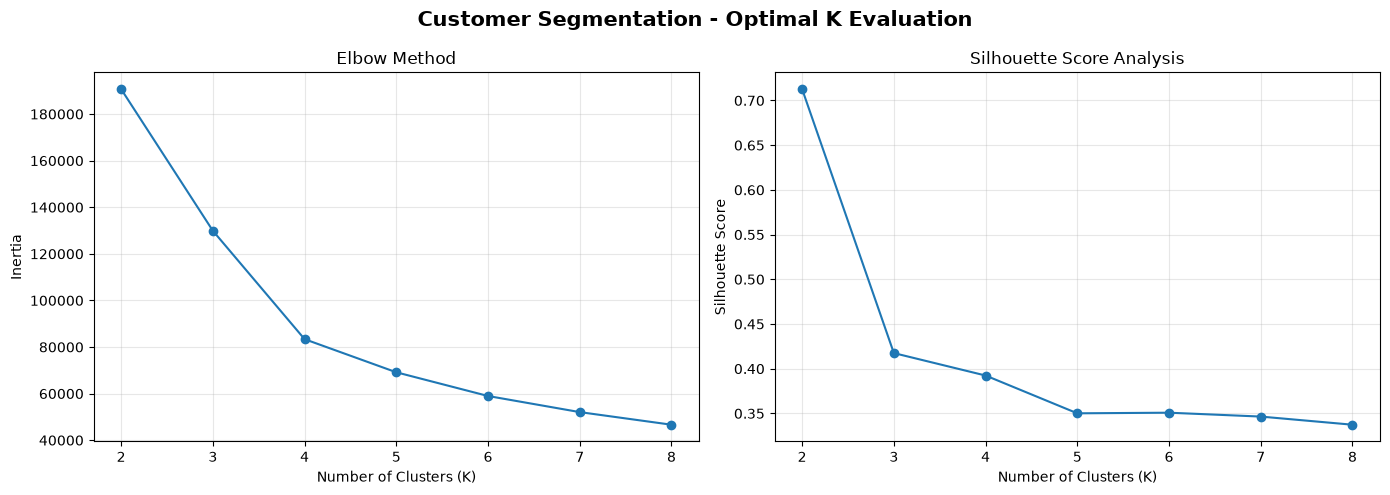

In [195]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow method
axes[0].plot(
    cluster_results_df["K"],
    cluster_results_df["Inertia"],
    marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(range(2, 9))
axes[0].grid(alpha=0.3)

# Silhouette scores
axes[1].plot(
    cluster_results_df["K"],
    cluster_results_df["Silhouette_Score"],
    marker="o"
)
axes[1].set_title("Silhouette Score Analysis")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(range(2, 9))
axes[1].grid(alpha=0.3)

plt.suptitle(
    "Customer Segmentation - Optimal K Evaluation",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [196]:
from sklearn.cluster import KMeans

comparison_results = []

for k in [2, 3, 4]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(ml_scaled_df)

    temp_df = ml_customer_df[
        ["frequency", "monetary", "recency_days"]
    ].copy()

    temp_df["cluster"] = labels

    profile = temp_df.groupby("cluster").agg(
        total_customers=("frequency", "count"),
        avg_frequency=("frequency", "mean"),
        avg_monetary=("monetary", "mean"),
        avg_recency=("recency_days", "mean")
    ).reset_index()

    profile["K"] = k

    comparison_results.append(profile)

cluster_profile_comparison = pd.concat(
    comparison_results,
    ignore_index=True
)

display(
    cluster_profile_comparison.round(2)
)

,cluster,total_customers,avg_frequency,avg_monetary,avg_recency,K
0,0,2801,2.11,260.05,219.29,2
1,1,90557,1.00,137.96,237.49,2
2,0,18918,1.00,139.00,46.69,3
3,1,71639,1.00,137.68,287.87,3
4,2,2801,2.11,260.05,219.29,3
5,0,36876,1.00,45.15,282.18,4
6,1,37930,1.00,236.88,276.08,4
7,2,2801,2.11,260.05,219.29,4
8,3,15751,1.00,117.03,39.92,4


In [197]:
# Train final candidate K-Means model with K=4

final_kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

final_labels = final_kmeans.fit_predict(ml_scaled_df)

# Add cluster labels
ml_customer_final = ml_customer_df[
    ["customer_unique_id", "frequency", "monetary", "recency_days"]
].copy()

ml_customer_final["cluster"] = final_labels

# Cluster distribution
cluster_distribution = (
    ml_customer_final["cluster"]
    .value_counts()
    .sort_index()
    .reset_index()
)

cluster_distribution.columns = [
    "cluster",
    "total_customers"
]

cluster_distribution["customer_percentage"] = (
    cluster_distribution["total_customers"]
    / len(ml_customer_final) * 100
)

display(cluster_distribution.round(2))


,cluster,total_customers,customer_percentage
0,0,36876,39.50
1,1,37930,40.63
2,2,2801,3.00
3,3,15751,16.87


In [198]:
cluster_profiles = (
    ml_customer_final.groupby("cluster")
    .agg(
        total_customers=("customer_unique_id", "count"),
        avg_frequency=("frequency", "mean"),
        median_frequency=("frequency", "median"),
        avg_monetary=("monetary", "mean"),
        median_monetary=("monetary", "median"),
        avg_recency=("recency_days", "mean"),
        median_recency=("recency_days", "median")
    )
    .reset_index()
)

cluster_profiles["customer_percentage"] = (
    cluster_profiles["total_customers"]
    / len(ml_customer_final) * 100
)

display(cluster_profiles.round(2))

,cluster,total_customers,avg_frequency,median_frequency,avg_monetary,median_monetary,avg_recency,median_recency,customer_percentage
0,0,36876,1.00,1.0,45.15,44.99,282.18,266.0,39.50
1,1,37930,1.00,1.0,236.88,150.00,276.08,259.0,40.63
2,2,2801,2.11,2.0,260.05,182.10,219.29,198.0,3.00
3,3,15751,1.00,1.0,117.03,83.98,39.92,36.0,16.87


In [199]:
# Map cluster IDs to business segment names

segment_mapping = {
    0: "Low Value Dormant Customers",
    1: "High Spending Dormant Customers",
    2: "Repeat High Value Customers",
    3: "Recent One-Time Customers"
}

ml_customer_final["ml_segment"] = (
    ml_customer_final["cluster"].map(segment_mapping)
)

# Create final segment summary
final_segment_summary = (
    ml_customer_final.groupby("ml_segment")
    .agg(
        total_customers=("customer_unique_id", "count"),
        avg_frequency=("frequency", "mean"),
        avg_monetary=("monetary", "mean"),
        avg_recency=("recency_days", "mean"),
        total_revenue=("monetary", "sum")
    )
    .reset_index()
)

final_segment_summary["customer_percentage"] = (
    final_segment_summary["total_customers"]
    / len(ml_customer_final) * 100
)

final_segment_summary = final_segment_summary.sort_values(
    "total_revenue",
    ascending=False
)

display(final_segment_summary.round(2))

,ml_segment,total_customers,avg_frequency,avg_monetary,avg_recency,total_revenue,customer_percentage
0,High Spending Dormant Customers,37930,1.00,236.88,276.08,8984870.89,40.63
2,Recent One-Time Customers,15751,1.00,117.03,39.92,1843320.20,16.87
1,Low Value Dormant Customers,36876,1.00,45.15,282.18,1664898.27,39.50
3,Repeat High Value Customers,2801,2.11,260.05,219.29,728408.75,3.00


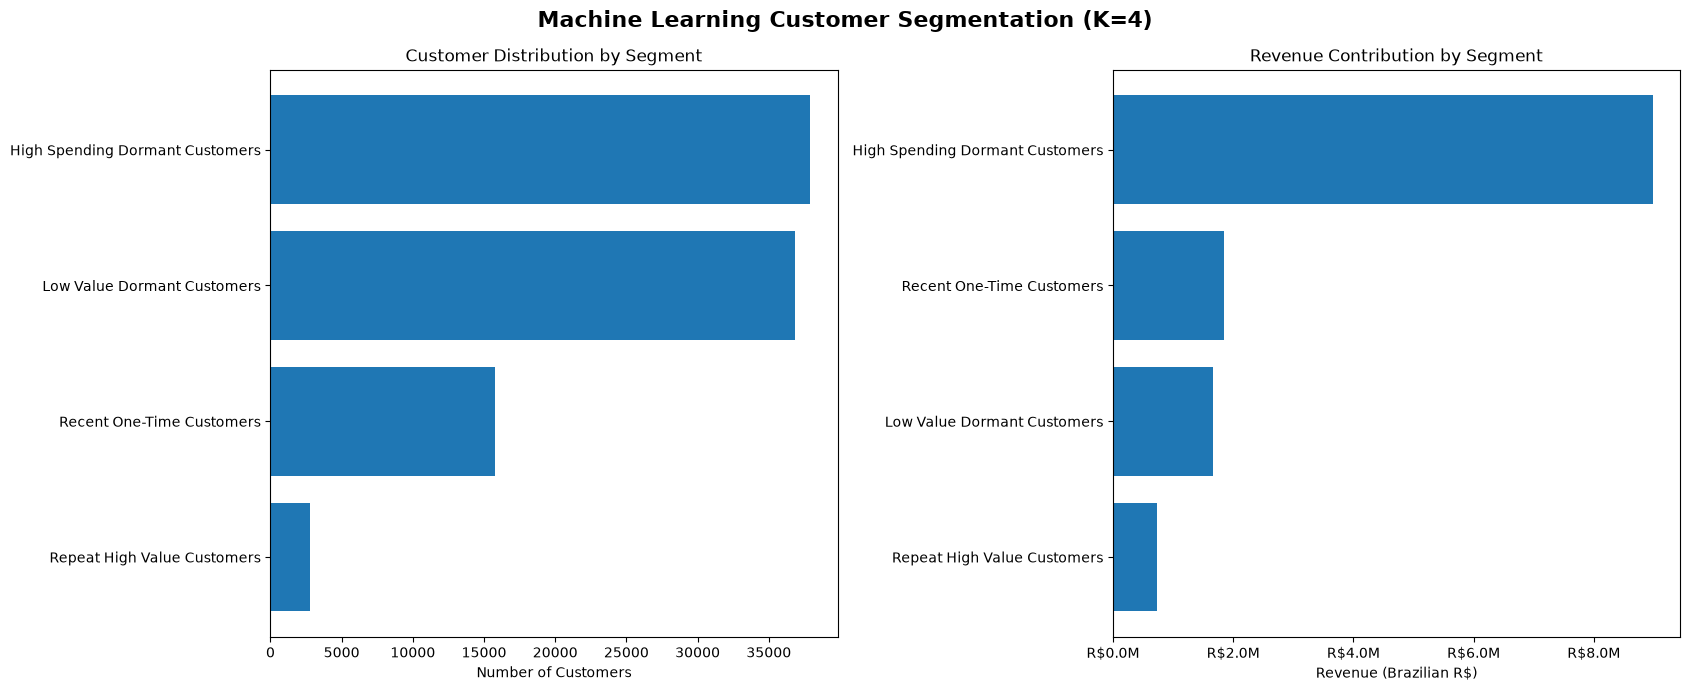

In [200]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

fig, axes = plt.subplots(1, 2, figsize=(17, 7))

# Customer distribution
customer_plot = final_segment_summary.sort_values(
    "total_customers",
    ascending=True
)

axes[0].barh(
    customer_plot["ml_segment"],
    customer_plot["total_customers"]
)

axes[0].set_title("Customer Distribution by Segment")
axes[0].set_xlabel("Number of Customers")

# Revenue contribution
revenue_plot = final_segment_summary.sort_values(
    "total_revenue",
    ascending=True
)

axes[1].barh(
    revenue_plot["ml_segment"],
    revenue_plot["total_revenue"]
)

axes[1].set_title("Revenue Contribution by Segment")
axes[1].set_xlabel("Revenue (Brazilian R$)")

axes[1].xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"R${x/1_000_000:.1f}M")
)

plt.suptitle(
    "Machine Learning Customer Segmentation (K=4)",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [201]:
# Export final ML customer segmentation
ml_customer_final.to_csv(
    ml_path / "outputs" / "ml_customer_segmentation_k4.csv",
    index=False
)

# Export segment summary
final_segment_summary.to_csv(
    ml_path / "outputs" / "ml_customer_segment_summary_k4.csv",
    index=False
)

print("===== ML SEGMENTATION EXPORT =====")
print("Customer records:", len(ml_customer_final))
print("Segments:", ml_customer_final["ml_segment"].nunique())

print("\nExported files:")
print("1. ml_customer_segmentation_k4.csv")
print("2. ml_customer_segment_summary_k4.csv")

===== ML SEGMENTATION EXPORT =====
Customer records: 93358
Segments: 4

Exported files:
1. ml_customer_segmentation_k4.csv
2. ml_customer_segment_summary_k4.csv


In [202]:
import joblib
import json

# Save trained K-Means model
joblib.dump(
    final_kmeans,
    ml_path / "models" / "kmeans_customer_model.pkl"
)

# Save fitted StandardScaler
joblib.dump(
    scaler,
    ml_path / "models" / "customer_scaler.pkl"
)

# Save segment mapping
with open(
    ml_path / "models" / "customer_segment_mapping.json",
    "w"
) as file:
    json.dump(segment_mapping, file, indent=4)

print("===== MODEL ARTIFACTS SAVED =====")

print("K-Means model saved")
print("StandardScaler saved")
print("Customer segment mapping saved")

===== MODEL ARTIFACTS SAVED =====
K-Means model saved
StandardScaler saved
Customer segment mapping saved


In [203]:
import joblib
import json
import numpy as np

# Load saved model and scaler
loaded_kmeans = joblib.load(
    ml_path / "models" / "kmeans_customer_model.pkl"
)

loaded_scaler = joblib.load(
    ml_path / "models" / "customer_scaler.pkl"
)

with open(
    ml_path / "models" / "customer_segment_mapping.json",
    "r"
) as file:
    loaded_mapping = json.load(file)

# Take 5 sample customers
sample_customers = ml_customer_df[
    ["frequency", "monetary", "recency_days"]
].head(5).copy()

# Apply same transformations used during training
sample_log = np.log1p(sample_customers)

sample_scaled = loaded_scaler.transform(sample_log)

# Predict customer clusters
sample_predictions = loaded_kmeans.predict(sample_scaled)

# Map predictions to business labels
sample_customers["predicted_cluster"] = sample_predictions

sample_customers["predicted_segment"] = [
    loaded_mapping[str(cluster)]
    for cluster in sample_predictions
]

display(sample_customers)

print("Saved model prediction test completed!")

/Users/animeshjain/ecommerce-intelligence-analytics/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


,frequency,monetary,recency_days,predicted_cluster,predicted_segment
0,1,129.90,111,1,High Spending Dormant Customers
1,1,18.90,114,0,Low Value Dormant Customers
2,1,69.00,536,0,Low Value Dormant Customers
3,1,25.99,320,0,Low Value Dormant Customers
4,1,180.00,287,1,High Spending Dormant Customers


Saved model prediction test completed!


In [204]:
# Keep feature names during scaling
sample_scaled_df = pd.DataFrame(
    loaded_scaler.transform(sample_log),
    columns=["frequency", "monetary", "recency_days"],
    index=sample_customers.index
)

# Predict using DataFrame
sample_predictions = loaded_kmeans.predict(sample_scaled_df)

# Create prediction results
sample_customers["predicted_cluster"] = sample_predictions

sample_customers["predicted_segment"] = [
    loaded_mapping[str(cluster)]
    for cluster in sample_predictions
]

display(sample_customers)

print("Prediction test completed without feature-name mismatch.")

,frequency,monetary,recency_days,predicted_cluster,predicted_segment
0,1,129.90,111,1,High Spending Dormant Customers
1,1,18.90,114,0,Low Value Dormant Customers
2,1,69.00,536,0,Low Value Dormant Customers
3,1,25.99,320,0,Low Value Dormant Customers
4,1,180.00,287,1,High Spending Dormant Customers


Prediction test completed without feature-name mismatch.


In [205]:
from sklearn.metrics import silhouette_score

# Evaluate final K=4 model
final_silhouette = silhouette_score(
    ml_scaled_df,
    final_labels,
    sample_size=10000,
    random_state=42
)

print("===== FINAL K-MEANS MODEL EVALUATION =====")
print("Algorithm: K-Means")
print("Number of Clusters:", 4)
print("Total Customers:", len(ml_customer_final))
print("Silhouette Score:", round(final_silhouette, 4))
print("Inertia:", round(final_kmeans.inertia_, 2))

===== FINAL K-MEANS MODEL EVALUATION =====
Algorithm: K-Means
Number of Clusters: 4
Total Customers: 93358
Silhouette Score: 0.3924
Inertia: 83368.22


In [206]:
model_evaluation = pd.DataFrame([{
    "Model": "K-Means",
    "Number_of_Clusters": 4,
    "Total_Customers": len(ml_customer_final),
    "Silhouette_Score": final_silhouette,
    "Inertia": final_kmeans.inertia_,
    "Features": "frequency, monetary, recency_days",
    "Transformation": "log1p + StandardScaler"
}])

model_evaluation.to_csv(
    ml_path / "outputs" / "customer_segmentation_model_evaluation.csv",
    index=False
)

display(model_evaluation.round(4))

print("Model evaluation report exported successfully!")

,Model,Number_of_Clusters,Total_Customers,Silhouette_Score,Inertia,Features,Transformation
0,K-Means,4,93358,0.3924,83368.2155,"frequency, monetary, recency_days",log1p + StandardScaler


Model evaluation report exported successfully!


In [207]:
from pathlib import Path

ml_script = '''import joblib
import json
import numpy as np
import pandas as pd
from pathlib import Path


MODEL_DIR = Path(__file__).resolve().parents[1] / "models"

def load_customer_model():
    model = joblib.load(
        MODEL_DIR / "kmeans_customer_model.pkl"
    )

    scaler = joblib.load(
        MODEL_DIR / "customer_scaler.pkl"
    )

    with open(
        MODEL_DIR / "customer_segment_mapping.json",
        "r"
    ) as file:
        mapping = json.load(file)

    return model, scaler, mapping


def predict_customer_segments(customer_data):
    required_columns = [
        "frequency",
        "monetary",
        "recency_days"
    ]

    if not set(required_columns).issubset(customer_data.columns):
        raise ValueError("Required customer features are missing.")

    if customer_data[required_columns].isnull().any().any():
        raise ValueError("Customer features contain missing values.")

    if (customer_data[required_columns] < 0).any().any():
        raise ValueError("Customer features cannot be negative.")

    model, scaler, mapping = load_customer_model()

    features = customer_data[required_columns].copy()

    transformed_features = np.log1p(features)

    scaled_features = pd.DataFrame(
        scaler.transform(transformed_features),
        columns=required_columns,
        index=customer_data.index
    )

    predictions = model.predict(scaled_features)

    result = customer_data.copy()
    result["predicted_cluster"] = predictions
    result["predicted_segment"] = [
        mapping[str(cluster)] for cluster in predictions
    ]

    return result
'''

script_path = ml_path / "src" / "customer_segmentation.py"

script_path.write_text(ml_script)

print("Reusable ML script created:")
print(script_path)

Reusable ML script created:
/Users/animeshjain/ecommerce-intelligence-analytics/python/ml/src/customer_segmentation.py


In [208]:
import sys
import pandas as pd

# Add ML source folder to Python path
src_path = str(ml_path / "src")

if src_path not in sys.path:
    sys.path.insert(0, src_path)

# Import reusable prediction function
from customer_segmentation import predict_customer_segments

# Prepare sample customer data
test_customers = pd.DataFrame({
    "frequency": [1, 2, 3, 1, 5],
    "monetary": [129.90, 500, 1200, 25.99, 2500],
    "recency_days": [111, 30, 60, 320, 15]
})

# Generate predictions
test_predictions = predict_customer_segments(test_customers)

display(test_predictions)

print("\nTotal predictions:", len(test_predictions))
print("Unique segments:", test_predictions["predicted_segment"].nunique())
print("\nReusable ML script tested successfully!")

,frequency,monetary,recency_days,predicted_cluster,predicted_segment
0,1,129.90,111,1,High Spending Dormant Customers
1,2,500.00,30,2,Repeat High Value Customers
2,3,1200.00,60,2,Repeat High Value Customers
3,1,25.99,320,0,Low Value Dormant Customers
4,5,2500.00,15,2,Repeat High Value Customers



Total predictions: 5
Unique segments: 3

Reusable ML script tested successfully!


In [209]:
# Inspect monthly sales dataset for forecasting

print("Dataset shape:", monthly_df.shape)

print("\nColumns:")
print(monthly_df.columns.tolist())

print("\nDate range:")
print(monthly_df["sales_month"].min())
print(monthly_df["sales_month"].max())

print("\nMonthly sales data:")
display(monthly_df.head(10))

print("\nMissing values:")
display(monthly_df.isnull().sum())

Dataset shape: (25, 7)

Columns:
['sales_month', 'total_orders', 'delivered_orders', 'canceled_orders', 'total_product_revenue', 'total_freight', 'average_order_value']

Date range:
2016-09-01 00:00:00
2018-10-01 00:00:00

Monthly sales data:


,sales_month,total_orders,delivered_orders,canceled_orders,total_product_revenue,total_freight,average_order_value
0,2016-09-01,4,1,2,267.36,87.39,88.69
1,2016-10-01,324,265,24,49507.66,7301.18,175.34
2,2016-12-01,1,1,0,10.90,8.72,19.62
3,2017-01-01,800,750,3,120312.87,16875.62,171.49
4,2017-02-01,1780,1653,17,247303.02,38977.60,160.83
5,2017-03-01,2682,2546,33,374344.30,57704.29,161.09
6,2017-04-01,2404,2303,18,359927.23,52495.01,171.56
7,2017-05-01,3700,3546,29,506071.14,80119.81,158.43
8,2017-06-01,3245,3135,16,433038.60,69924.44,155.00
9,2017-07-01,4026,3872,28,498031.48,86940.14,145.30



Missing values:


sales_month              0
total_orders             0
delivered_orders         0
canceled_orders          0
total_product_revenue    0
total_freight            0
average_order_value      0
dtype: int64

In [210]:
# Prepare monthly sales data
forecast_df = monthly_df.copy()

forecast_df["sales_month"] = pd.to_datetime(
    forecast_df["sales_month"]
)

forecast_df = forecast_df.sort_values(
    "sales_month"
).reset_index(drop=True)

# Generate complete monthly calendar
full_calendar = pd.date_range(
    start=forecast_df["sales_month"].min(),
    end=forecast_df["sales_month"].max(),
    freq="MS"
)

# Identify missing months
missing_months = full_calendar.difference(
    forecast_df["sales_month"]
)

print("===== MONTHLY TIMELINE AUDIT =====")

print("First month:", forecast_df["sales_month"].min())
print("Last month:", forecast_df["sales_month"].max())
print("Available records:", len(forecast_df))
print("Expected calendar months:", len(full_calendar))

print("\nMissing months:")
print(missing_months.strftime("%Y-%m").tolist())

print("\nMonthly order and revenue overview:")

display(
    forecast_df[
        ["sales_month", "total_orders", "total_product_revenue"]
    ].to_string(index=False)
)

===== MONTHLY TIMELINE AUDIT =====
First month: 2016-09-01 00:00:00
Last month: 2018-10-01 00:00:00
Available records: 25
Expected calendar months: 26

Missing months:
['2016-11']

Monthly order and revenue overview:


'sales_month  total_orders  total_product_revenue\n 2016-09-01             4                 267.36\n 2016-10-01           324               49507.66\n 2016-12-01             1                  10.90\n 2017-01-01           800              120312.87\n 2017-02-01          1780              247303.02\n 2017-03-01          2682              374344.30\n 2017-04-01          2404              359927.23\n 2017-05-01          3700              506071.14\n 2017-06-01          3245              433038.60\n 2017-07-01          4026              498031.48\n 2017-08-01          4331              573971.68\n 2017-09-01          4285              624401.69\n 2017-10-01          4631              664219.43\n 2017-11-01          7544             1010271.37\n 2017-12-01          5673              743914.17\n 2018-01-01          7269              950030.36\n 2018-02-01          6728              844178.71\n 2018-03-01          7211              983213.44\n 2018-04-01          6939              996647.75\

In [211]:
# Keep complete monthly period: Jan 2017 to Aug 2018

forecast_clean_df = forecast_df[
    (forecast_df["sales_month"] >= "2017-01-01") &
    (forecast_df["sales_month"] <= "2018-08-01")
].copy()

forecast_clean_df = forecast_clean_df.sort_values(
    "sales_month"
).reset_index(drop=True)

print("===== CLEAN FORECAST DATASET =====")

print("Total months:", len(forecast_clean_df))
print("Start date:", forecast_clean_df["sales_month"].min())
print("End date:", forecast_clean_df["sales_month"].max())

print("\nMissing values:")
display(forecast_clean_df.isnull().sum())

print("\nMonthly revenue:")
display(
    forecast_clean_df[
        ["sales_month", "total_orders", "total_product_revenue"]
    ]
)

===== CLEAN FORECAST DATASET =====
Total months: 20
Start date: 2017-01-01 00:00:00
End date: 2018-08-01 00:00:00

Missing values:


sales_month              0
total_orders             0
delivered_orders         0
canceled_orders          0
total_product_revenue    0
total_freight            0
average_order_value      0
dtype: int64


Monthly revenue:


,sales_month,total_orders,total_product_revenue
0,2017-01-01,800,120312.87
1,2017-02-01,1780,247303.02
2,2017-03-01,2682,374344.30
3,2017-04-01,2404,359927.23
4,2017-05-01,3700,506071.14
5,2017-06-01,3245,433038.60
6,2017-07-01,4026,498031.48
7,2017-08-01,4331,573971.68
8,2017-09-01,4285,624401.69
9,2017-10-01,4631,664219.43


In [212]:
# Create time-series features

model_df = forecast_clean_df[
    ["sales_month", "total_product_revenue", "total_orders"]
].copy()

# Previous month revenue
model_df["revenue_lag_1"] = (
    model_df["total_product_revenue"].shift(1)
)

# Revenue from two months ago
model_df["revenue_lag_2"] = (
    model_df["total_product_revenue"].shift(2)
)

# Revenue from three months ago
model_df["revenue_lag_3"] = (
    model_df["total_product_revenue"].shift(3)
)

# Average revenue of previous three months
model_df["revenue_rolling_mean_3"] = (
    model_df["total_product_revenue"]
    .shift(1)
    .rolling(window=3)
    .mean()
)

# Previous month order count
model_df["orders_lag_1"] = (
    model_df["total_orders"].shift(1)
)

# Remove rows without historical features
model_df = model_df.dropna().reset_index(drop=True)

print("===== FEATURE ENGINEERING RESULTS =====")

print("Original records:", len(forecast_clean_df))
print("Records after feature engineering:", len(model_df))

print("\nFeature columns:")
print(model_df.columns.tolist())

print("\nMissing values:")
display(model_df.isnull().sum())

print("\nFinal model dataset:")
display(model_df.head(10))

===== FEATURE ENGINEERING RESULTS =====
Original records: 20
Records after feature engineering: 17

Feature columns:
['sales_month', 'total_product_revenue', 'total_orders', 'revenue_lag_1', 'revenue_lag_2', 'revenue_lag_3', 'revenue_rolling_mean_3', 'orders_lag_1']

Missing values:


sales_month               0
total_product_revenue     0
total_orders              0
revenue_lag_1             0
revenue_lag_2             0
revenue_lag_3             0
revenue_rolling_mean_3    0
orders_lag_1              0
dtype: int64


Final model dataset:


,sales_month,total_product_revenue,total_orders,revenue_lag_1,revenue_lag_2,revenue_lag_3,revenue_rolling_mean_3,orders_lag_1
0,2017-04-01,359927.23,2404,374344.30,247303.02,120312.87,247320.063333,2682.0
1,2017-05-01,506071.14,3700,359927.23,374344.30,247303.02,327191.516667,2404.0
2,2017-06-01,433038.60,3245,506071.14,359927.23,374344.30,413447.556667,3700.0
3,2017-07-01,498031.48,4026,433038.60,506071.14,359927.23,433012.323333,3245.0
4,2017-08-01,573971.68,4331,498031.48,433038.60,506071.14,479047.073333,4026.0
5,2017-09-01,624401.69,4285,573971.68,498031.48,433038.60,501680.586667,4331.0
6,2017-10-01,664219.43,4631,624401.69,573971.68,498031.48,565468.283333,4285.0
7,2017-11-01,1010271.37,7544,664219.43,624401.69,573971.68,620864.266667,4631.0
8,2017-12-01,743914.17,5673,1010271.37,664219.43,624401.69,766297.496667,7544.0
9,2018-01-01,950030.36,7269,743914.17,1010271.37,664219.43,806134.990000,5673.0


In [213]:
# Define features and target

feature_columns = [
    "revenue_lag_1",
    "revenue_lag_2",
    "revenue_lag_3",
    "revenue_rolling_mean_3",
    "orders_lag_1"
]

X = model_df[feature_columns].copy()
y = model_df["total_product_revenue"].copy()

# Chronological split: first 13 for training, last 4 for testing
split_index = len(model_df) - 4

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("===== TRAIN-TEST SPLIT =====")

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining period:")
print(model_df["sales_month"].iloc[0], "to",
      model_df["sales_month"].iloc[split_index - 1])

print("\nTesting period:")
print(model_df["sales_month"].iloc[split_index], "to",
      model_df["sales_month"].iloc[-1])

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTest data:")
display(
    model_df.iloc[split_index:][
        ["sales_month", "total_product_revenue"]
    ]
)


===== TRAIN-TEST SPLIT =====
Training records: 13
Testing records: 4

Training period:
2017-04-01 00:00:00 to 2018-04-01 00:00:00

Testing period:
2018-05-01 00:00:00 to 2018-08-01 00:00:00

Training feature shape: (13, 5)
Testing feature shape: (4, 5)

Test data:


,sales_month,total_product_revenue
13,2018-05-01,996517.68
14,2018-06-01,865124.31
15,2018-07-01,895507.22
16,2018-08-01,854686.33


In [214]:
# Import machine learning models and metrics

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# 1. Baseline prediction: previous month's revenue
baseline_predictions = X_test["revenue_lag_1"].values

# 2. Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

# 3. Random Forest
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=3,
    min_samples_leaf=2,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

# Compare actual and predicted revenue
prediction_df = pd.DataFrame({
    "sales_month": model_df["sales_month"].iloc[split_index:].values,
    "actual_revenue": y_test.values,
    "baseline_prediction": baseline_predictions,
    "linear_prediction": linear_predictions,
    "random_forest_prediction": rf_predictions
})

print("===== FORECAST MODEL PREDICTIONS =====")

display(prediction_df.round(2))

===== FORECAST MODEL PREDICTIONS =====


/var/folders/y9/wrynjjb10td2_6pm041jbm2w0000gn/T/ipykernel_1392/594362510.py:41: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(prediction_df.round(2))


,sales_month,actual_revenue,baseline_prediction,linear_prediction,random_forest_prediction
0,2018-05-01,996517.68,996647.75,1160595.07,933253.68
1,2018-06-01,865124.31,996517.68,1226637.19,932333.71
2,2018-07-01,895507.22,865124.31,1179708.78,955618.95
3,2018-08-01,854686.33,895507.22,1103822.12,958571.01


In [215]:
# Evaluate forecasting models

def calculate_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = np.mean(np.abs((actual - predicted) / actual)) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    }


# Calculate metrics for all models
results = {
    "Baseline": calculate_metrics(
        y_test.values, baseline_predictions
    ),
    "Linear Regression": calculate_metrics(
        y_test.values, linear_predictions
    ),
    "Random Forest": calculate_metrics(
        y_test.values, rf_predictions
    )
}

evaluation_df = pd.DataFrame(results).T

evaluation_df = evaluation_df.sort_values(
    "MAE"
)

print("===== MODEL PERFORMANCE COMPARISON =====")

display(evaluation_df.round(2))


===== MODEL PERFORMANCE COMPARISON =====


,MAE,RMSE,MAPE (%)
Baseline,50681.81,70451.58,5.84
Random Forest,73617.45,75704.83,8.25
Linear Regression,264731.91,274067.57,29.78


In [216]:
# Verify MAPE for all three models

for name, predictions in {
    "Baseline": baseline_predictions,
    "Linear Regression": linear_predictions,
    "Random Forest": rf_predictions
}.items():

    actual = np.asarray(y_test, dtype=float)
    predicted = np.asarray(predictions, dtype=float)

    mape = np.mean(
        np.abs((actual - predicted) / actual)
    ) * 100

    print(f"{name}: {mape:.2f}%")
    

Baseline: 5.84%
Linear Regression: 29.78%
Random Forest: 8.25%


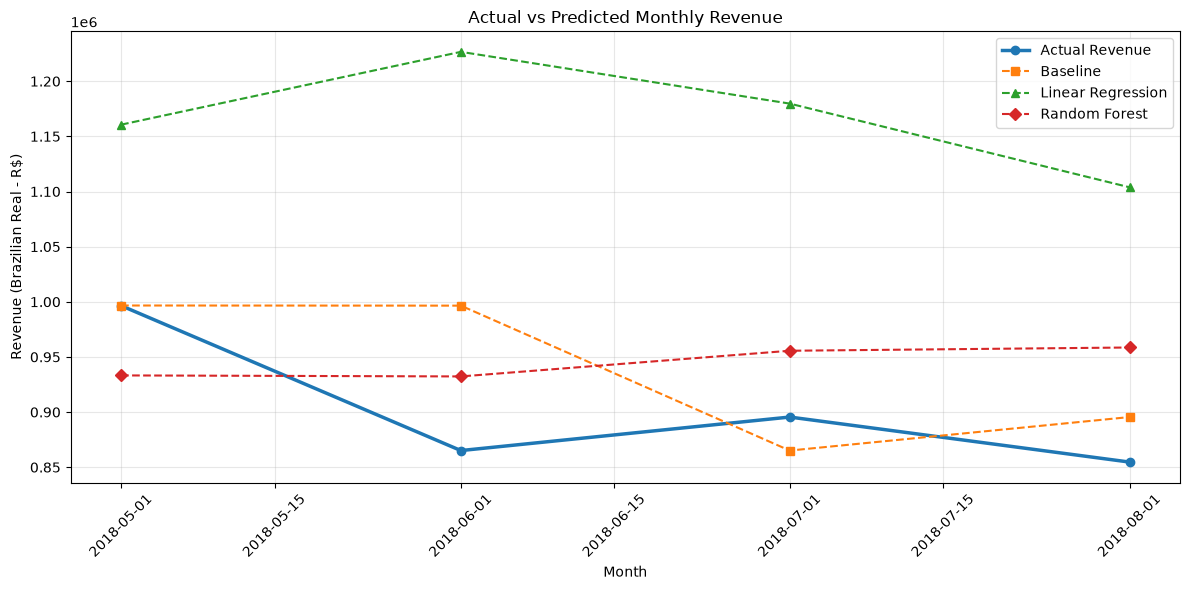

Chart saved successfully!


In [217]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Prepare comparison chart
plt.figure(figsize=(12, 6))

plt.plot(
    prediction_df["sales_month"],
    prediction_df["actual_revenue"],
    marker="o",
    linewidth=2.5,
    label="Actual Revenue"
)

plt.plot(
    prediction_df["sales_month"],
    prediction_df["baseline_prediction"],
    marker="s",
    linestyle="--",
    label="Baseline"
)

plt.plot(
    prediction_df["sales_month"],
    prediction_df["linear_prediction"],
    marker="^",
    linestyle="--",
    label="Linear Regression"
)

plt.plot(
    prediction_df["sales_month"],
    prediction_df["random_forest_prediction"],
    marker="D",
    linestyle="--",
    label="Random Forest"
)

plt.title("Actual vs Predicted Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (Brazilian Real - R$)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save chart
forecast_output_dir = ml_path / "outputs"
forecast_output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    forecast_output_dir / "actual_vs_predicted_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully!")

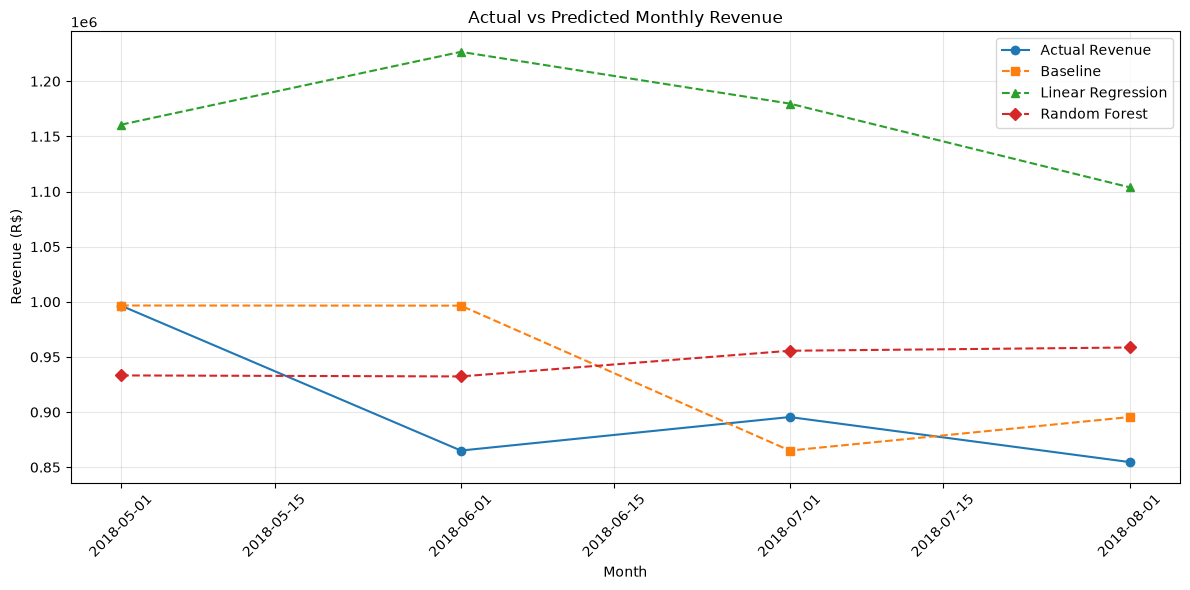

Forecasting files saved successfully!

Saved files:
sales_forecast_model_evaluation.csv
sales_forecast_predictions.csv


In [218]:
# Save forecasting outputs

forecast_output_dir = ml_path / "outputs"
forecast_output_dir.mkdir(parents=True, exist_ok=True)

# Save actual vs predicted values
prediction_df.to_csv(
    forecast_output_dir / "sales_forecast_predictions.csv",
    index=False
)

# Save model evaluation metrics
evaluation_df.to_csv(
    forecast_output_dir / "sales_forecast_model_evaluation.csv"
)

# Save chart (already generated, save again for consistency)
plt.figure(figsize=(12, 6))

plt.plot(
    prediction_df["sales_month"],
    prediction_df["actual_revenue"],
    marker="o",
    label="Actual Revenue"
)

plt.plot(
    prediction_df["sales_month"],
    prediction_df["baseline_prediction"],
    marker="s",
    linestyle="--",
    label="Baseline"
)

plt.plot(
    prediction_df["sales_month"],
    prediction_df["linear_prediction"],
    marker="^",
    linestyle="--",
    label="Linear Regression"
)

plt.plot(
    prediction_df["sales_month"],
    prediction_df["random_forest_prediction"],
    marker="D",
    linestyle="--",
    label="Random Forest"
)

plt.title("Actual vs Predicted Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (R$)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    forecast_output_dir / "actual_vs_predicted_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Forecasting files saved successfully!")

print("\nSaved files:")
for file in forecast_output_dir.glob("sales_forecast*"):
    print(file.name)

In [219]:
# Verify all forecasting output files

print("===== FORECASTING OUTPUT FILES =====")

for file in sorted(forecast_output_dir.glob("*")):
    if file.is_file():
        print(f"{file.name} | {file.stat().st_size:,} bytes")

===== FORECASTING OUTPUT FILES =====
actual_vs_predicted_revenue.png | 252,481 bytes
customer_segmentation_model_evaluation.csv | 202 bytes
ml_customer_segment_summary_k4.csv | 533 bytes
ml_customer_segmentation_k4.csv | 7,075,136 bytes
sales_forecast_model_evaluation.csv | 222 bytes
sales_forecast_predictions.csv | 359 bytes


In [220]:
# Create reusable Sales Forecasting module

from pathlib import Path

forecast_script = r'''
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error


FEATURE_COLUMNS = [
    "revenue_lag_1",
    "revenue_lag_2",
    "revenue_lag_3",
    "revenue_rolling_mean_3",
    "orders_lag_1"
]


def prepare_forecasting_data(monthly_df):
    """Clean monthly data and create historical features."""

    df = monthly_df.copy()

    df["sales_month"] = pd.to_datetime(df["sales_month"])
    df = df.sort_values("sales_month")

    # Use complete historical period
    df = df[
        (df["sales_month"] >= "2017-01-01") &
        (df["sales_month"] <= "2018-08-01")
    ].copy()

    df["revenue_lag_1"] = df["total_product_revenue"].shift(1)
    df["revenue_lag_2"] = df["total_product_revenue"].shift(2)
    df["revenue_lag_3"] = df["total_product_revenue"].shift(3)

    df["revenue_rolling_mean_3"] = (
        df["total_product_revenue"]
        .shift(1)
        .rolling(3)
        .mean()
    )

    df["orders_lag_1"] = df["total_orders"].shift(1)

    return df.dropna().reset_index(drop=True)


def evaluate_forecasting_models(model_df, test_months=4):
    """Train and evaluate forecasting models chronologically."""

    if len(model_df) <= test_months:
        raise ValueError("Not enough records for the requested test period.")

    X = model_df[FEATURE_COLUMNS]
    y = model_df["total_product_revenue"]

    split_index = len(model_df) - test_months

    X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
    y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

    # Baseline
    baseline_predictions = X_test["revenue_lag_1"].to_numpy()

    # Linear Regression
    linear_model = LinearRegression()
    linear_model.fit(X_train, y_train)
    linear_predictions = linear_model.predict(X_test)

    # Random Forest
    rf_model = RandomForestRegressor(
        n_estimators=200,
        max_depth=3,
        min_samples_leaf=2,
        random_state=42
    )
    rf_model.fit(X_train, y_train)
    rf_predictions = rf_model.predict(X_test)

    predictions = pd.DataFrame({
        "sales_month": model_df["sales_month"].iloc[split_index:].values,
        "actual_revenue": y_test.values,
        "baseline_prediction": baseline_predictions,
        "linear_prediction": linear_predictions,
        "random_forest_prediction": rf_predictions
    })

    def metrics(actual, predicted):
        actual = np.asarray(actual, dtype=float)
        predicted = np.asarray(predicted, dtype=float)

        return {
            "MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
            "MAPE (%)": np.mean(
                np.abs((actual - predicted) / actual)
            ) * 100
        }

    evaluation = pd.DataFrame({
        "Baseline": metrics(y_test, baseline_predictions),
        "Linear Regression": metrics(y_test, linear_predictions),
        "Random Forest": metrics(y_test, rf_predictions)
    }).T

    return predictions, evaluation
'''

script_path = ml_path / "src" / "sales_forecasting.py"

script_path.write_text(forecast_script, encoding="utf-8")

print("Module created:", script_path)
print("File exists:", script_path.exists())
print("File size:", script_path.stat().st_size, "bytes")

Module created: /Users/animeshjain/ecommerce-intelligence-analytics/python/ml/src/sales_forecasting.py
File exists: True
File size: 3103 bytes


In [221]:
# Import reusable forecasting module

import sys
import importlib

src_path = str(ml_path / "src")

if src_path not in sys.path:
    sys.path.insert(0, src_path)

import sales_forecasting

importlib.reload(sales_forecasting)

# Prepare data using reusable function
test_model_df = sales_forecasting.prepare_forecasting_data(monthly_df)

# Run forecasting models
test_predictions, test_evaluation = (
    sales_forecasting.evaluate_forecasting_models(
        test_model_df,
        test_months=4
    )
)

print("===== MODULE TEST RESULTS =====")

print("Prepared dataset shape:", test_model_df.shape)

print("\nPredictions:")
display(test_predictions.round(2))

print("\nModel evaluation:")
display(test_evaluation.round(2))

===== MODULE TEST RESULTS =====
Prepared dataset shape: (17, 12)

Predictions:


/var/folders/y9/wrynjjb10td2_6pm041jbm2w0000gn/T/ipykernel_1392/3191008873.py:31: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(test_predictions.round(2))


,sales_month,actual_revenue,baseline_prediction,linear_prediction,random_forest_prediction
0,2018-05-01,996517.68,996647.75,1160595.07,933253.68
1,2018-06-01,865124.31,996517.68,1226637.19,932333.71
2,2018-07-01,895507.22,865124.31,1179708.78,955618.95
3,2018-08-01,854686.33,895507.22,1103822.12,958571.01



Model evaluation:


,MAE,RMSE,MAPE (%)
Baseline,50681.81,70451.58,5.84
Linear Regression,264731.91,274067.57,29.78
Random Forest,73617.45,75704.83,8.25


In [222]:
# Add next-month forecasting function to reusable module

forecast_script = script_path.read_text(encoding="utf-8")

new_function = '''

def forecast_next_month(monthly_df):
    """Train models on all prepared data and predict next month revenue."""

    model_df = prepare_forecasting_data(monthly_df)

    X = model_df[FEATURE_COLUMNS]
    y = model_df["total_product_revenue"]

    # Build features for the next month
    next_features = pd.DataFrame([{
        "revenue_lag_1": model_df["total_product_revenue"].iloc[-1],
        "revenue_lag_2": model_df["total_product_revenue"].iloc[-2],
        "revenue_lag_3": model_df["total_product_revenue"].iloc[-3],
        "revenue_rolling_mean_3": (
            model_df["total_product_revenue"].tail(3).mean()
        ),
        "orders_lag_1": model_df["total_orders"].iloc[-1]
    }])

    # Train models on all available historical records
    linear_model = LinearRegression()
    linear_model.fit(X, y)

    rf_model = RandomForestRegressor(
        n_estimators=200,
        max_depth=3,
        min_samples_leaf=2,
        random_state=42
    )
    rf_model.fit(X, y)

    last_month = model_df["sales_month"].max()
    next_month = last_month + pd.offsets.MonthBegin(1)

    return pd.DataFrame({
        "forecast_month": [next_month],
        "baseline_prediction": [next_features["revenue_lag_1"].iloc[0]],
        "linear_prediction": [linear_model.predict(next_features)[0]],
        "random_forest_prediction": [rf_model.predict(next_features)[0]]
    })
'''

if "def forecast_next_month" not in forecast_script:
    script_path.write_text(
        forecast_script + new_function,
        encoding="utf-8"
    )

print("Next-month forecasting function added.")
print("Module size:", script_path.stat().st_size, "bytes")

Next-month forecasting function added.
Module size: 4488 bytes


In [223]:
# Reload updated forecasting module

import importlib
importlib.reload(sales_forecasting)

# Generate next-month forecast
next_month_forecast = sales_forecasting.forecast_next_month(
    monthly_df
)

print("===== NEXT MONTH REVENUE FORECAST =====")

display(next_month_forecast.round(2))

# Identify forecast values
print("\nForecast month:")
print(next_month_forecast["forecast_month"].iloc[0])

print("\nBaseline prediction:")
print(round(next_month_forecast["baseline_prediction"].iloc[0], 2))

print("\nLinear Regression prediction:")
print(round(next_month_forecast["linear_prediction"].iloc[0], 2))

print("\nRandom Forest prediction:")
print(round(next_month_forecast["random_forest_prediction"].iloc[0], 2))

===== NEXT MONTH REVENUE FORECAST =====


/var/folders/y9/wrynjjb10td2_6pm041jbm2w0000gn/T/ipykernel_1392/4026277580.py:13: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(next_month_forecast.round(2))


,forecast_month,baseline_prediction,linear_prediction,random_forest_prediction
0,2018-09-01,854686.33,911282.88,957966.07



Forecast month:
2018-09-01 00:00:00

Baseline prediction:
854686.33

Linear Regression prediction:
911282.88

Random Forest prediction:
957966.07


In [224]:
# Save next-month forecast

forecast_file = (
    forecast_output_dir / "next_month_revenue_forecast.csv"
)

next_month_forecast.to_csv(
    forecast_file,
    index=False
)

print("Forecast saved successfully!")
print("File:", forecast_file)
print("Exists:", forecast_file.exists())


Forecast saved successfully!
File: /Users/animeshjain/ecommerce-intelligence-analytics/python/ml/outputs/next_month_revenue_forecast.csv
Exists: True


In [225]:
# Final Sales Forecasting verification

required_files = [
    ml_path / "src" / "sales_forecasting.py",
    forecast_output_dir / "sales_forecast_predictions.csv",
    forecast_output_dir / "sales_forecast_model_evaluation.csv",
    forecast_output_dir / "next_month_revenue_forecast.csv",
    forecast_output_dir / "actual_vs_predicted_revenue.png"
]

print("===== SALES FORECASTING FINAL CHECK =====")

for file in required_files:
    print(
        f"{file.name}:",
        "PASS" if file.exists() else "MISSING"
    )

print("\nModel evaluation:")
display(test_evaluation.round(2))

print("\nForecast:")
display(next_month_forecast)

===== SALES FORECASTING FINAL CHECK =====
sales_forecasting.py: PASS
sales_forecast_predictions.csv: PASS
sales_forecast_model_evaluation.csv: PASS
next_month_revenue_forecast.csv: PASS
actual_vs_predicted_revenue.png: PASS

Model evaluation:


,MAE,RMSE,MAPE (%)
Baseline,50681.81,70451.58,5.84
Linear Regression,264731.91,274067.57,29.78
Random Forest,73617.45,75704.83,8.25



Forecast:


,forecast_month,baseline_prediction,linear_prediction,random_forest_prediction
0,2018-09-01,854686.33,911282.87954,957966.069866


In [226]:
grep -nE "st.title|st.header|st.subheader|st.sidebar|except Exception|def " app.py


SyntaxError: invalid syntax (57083125.py, line 1)